In [4]:
#%pip install seaborn

In [1]:
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt  
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import geopandas as gpd  
from cartopy.io.shapereader import Reader
import matplotlib.patheffects as pe
import seaborn as sns
from matplotlib.ticker import FuncFormatter, MaxNLocator
from shapely.validation import make_valid  
from shapely.geometry import Point, MultiPolygon  
import pathlib
from tqdm import tqdm
from matplotlib.patches import Patch

os.chdir ('C:\\Users\\hamod4691\\Code\\arctic-benthic-biodiversity\\All data')

# Merge

In [22]:
files = {
    "GBIF": "gbif_final.parquet",
    "OBIS": "obis_final.parquet",
    "CB": "cb_final.parquet",
    "OGSL": "ogsl_final.parquet",
}

dfs = [
    pd.read_parquet(os.path.join("..", folder, fname))
    for folder, fname in files.items()
 ]
all_merged = pd.concat(dfs, ignore_index=True)

# Keep mixed text/number values by normalizing to string
for col in ["sourceID", "eventID"]:
    if col in all_merged.columns:
        all_merged[col] = all_merged[col].apply(
            lambda x: x.decode("utf-8") if isinstance(x, (bytes, bytearray)) else x
        ).astype("string")

# Normalize percentCoverage to string to avoid mixed object types
if "percentCoverage" in all_merged.columns:
    all_merged["percentCoverage"] = all_merged["percentCoverage"].apply(
        lambda x: x.decode("utf-8") if isinstance(x, (bytes, bytearray)) else x
    ).astype("string")

# Clean and coerce percentCoverage to numeric in a new column
if "percentCoverage" in all_merged.columns:
    percent_clean = all_merged["percentCoverage"].astype("string").str.strip()
    percent_clean = percent_clean.str.replace("%", "", regex=False)
    percent_clean = percent_clean.str.replace(",", "", regex=False)
    all_merged["percentCoverage_num"] = pd.to_numeric(percent_clean, errors="coerce")

total_records = len(all_merged)
all_merged.to_parquet("all_merged.parquet", index=False)

total_records

3614601

# Visualize stations

In [23]:
stations = pd.read_parquet("all_merged.parquet")

cols = [
    "decimalLatitudeStart",
    "decimalLongitudeStart",
    "datasetKey",
    "datasetTitle",
    "sourceDatabase",
    "year",
    "gebcoDepth",
]
all_stations = stations[cols].drop_duplicates()

total_stations = len(all_stations)
all_stations.to_parquet("all_stations.parquet", index=False)

all_stations

,decimalLatitudeStart,decimalLongitudeStart,datasetKey,datasetTitle,sourceDatabase,year,gebcoDepth
0,81.01390,8.00940,005eb8d8-ed94-41be-89cf-e3115a9058e4,NaN,GBIF,1980.0,-838.0
1,81.83330,8.56670,005eb8d8-ed94-41be-89cf-e3115a9058e4,NaN,GBIF,1980.0,-775.0
2,76.40000,30.00000,005eb8d8-ed94-41be-89cf-e3115a9058e4,NaN,GBIF,1991.0,-295.0
5,60.06780,168.74000,005eb8d8-ed94-41be-89cf-e3115a9058e4,NaN,GBIF,NaN,-130.0
6,60.83530,174.25190,005eb8d8-ed94-41be-89cf-e3115a9058e4,NaN,GBIF,1996.0,-568.0
...,...,...,...,...,...,...,...
3614391,68.49128,-100.65000,amd2018,NaN,OGSL,NaN,-12.0
3614463,68.30935,-100.79838,amd2018,NaN,OGSL,NaN,-57.0
3614506,68.32972,-102.94163,amd2018,NaN,OGSL,NaN,-44.0
3614535,68.47864,-103.43332,amd2018,NaN,OGSL,NaN,-62.0


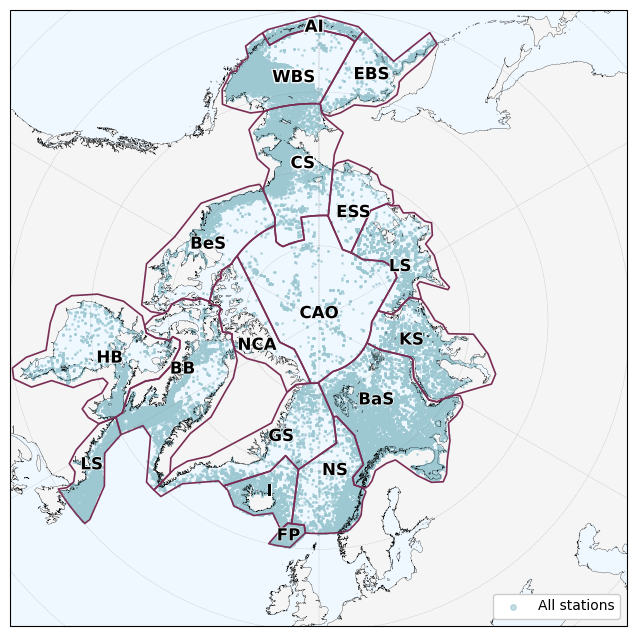

In [ ]:
# Ensure shapefile can be read even if .shx is missing
os.environ['SHAPE_RESTORE_SHX'] = 'YES'

# Load the data from device_water.xlsx
FILEPATH = 'all_stations.parquet'
df_station = pd.read_parquet(FILEPATH)

# Use LatStart and LonStart for coordinates
lat = df_station['decimalLatitudeStart'].copy()
lon = df_station['decimalLongitudeStart'].copy()

# Create coordinates dataframe
coords = pd.DataFrame({
    'lat': pd.to_numeric(lat, errors='coerce'),
    'lon': pd.to_numeric(lon, errors='coerce')
})
coords = coords.dropna()

# Filter to plausible lat/lon ranges
coords = coords[(coords['lat'] >= -90) & (coords['lat'] <= 90) &
                (coords['lon'] >= -180) & (coords['lon'] <= 180)]


# Create the plot with smaller figure size
plt.figure(figsize=(8, 8))
proj = ccrs.NorthPolarStereo()
ax = plt.axes(projection=proj)
ax.set_extent([-180, 180, 50, 90], crs=ccrs.PlateCarree())
ax.add_feature(cfeature.LAND, facecolor='whitesmoke')
ax.add_feature(cfeature.OCEAN, facecolor='aliceblue')
ax.coastlines(resolution='10m', linewidth=0.2, color='black')
ax.gridlines(draw_labels=False, linewidth=0.3, color='gray', alpha=0.5, linestyle='--')

# Add shapefile lines (EPSG:4326, same as stations)
shape_reader = Reader('../LME_boundaries_2014/lme_2013_wgs.shp')
line_feature = cfeature.ShapelyFeature(
    list(shape_reader.geometries()),
    ccrs.PlateCarree(),
    edgecolor='#792D54',
    facecolor='none'
)
ax.add_feature(line_feature, linewidth=1.2)

# Read the shapefile with attributes so we can access names
gdf_lme = gpd.read_file('../LME_boundaries_2014/lme_2013_wgs.shp')

# Ensure coordinates for labeling are in EPSG:4326 (PlateCarree)
gdf_lme_pc = gdf_lme.to_crs(epsg=4326)

# Step 1: Reproject to a projected CRS (e.g., EPSG:3395 for World Mercator)
gdf_lme_projected = gdf_lme.to_crs(epsg=3395)
# Step 2: Calculate centroids in the projected CRS
gdf_lme_projected['centroid'] = gdf_lme_projected.geometry.centroid
# Step 3: Reproject centroids back to the original geographic CRS (EPSG:4326)
gdf_lme_pc['centroid'] = gdf_lme_projected['centroid'].to_crs(epsg=4326)
# Step 4: Extract longitude and latitude for labeling
gdf_lme_pc['lon'] = gdf_lme_pc['centroid'].x  # Extract longitude
gdf_lme_pc['lat'] = gdf_lme_pc['centroid'].y  # Extract latitude


# Step 5: Add labels using the LME field
for _, row in gdf_lme_pc.iterrows():
    if row['LME'] in ['Central Arctic LME', 'Chukchi Sea LME', 'West Bering Sea LME', 'Alutian Islands LME']:
        # Skip these labels in the main loop
        continue
# Handle specific cases for Barents Sea and Beaufort Sea
    if row['LME'] == 'Barents Sea LME':
        short_label = 'BaS'  # Unique abbreviation for Barents Sea
    elif row['LME'] == 'Beaufort Sea LME':
        short_label = 'BeS'  # Unique abbreviation for Beaufort Sea
    else:
        words = row['LME'].split()  # Split the name into words
        short_label = ''.join([word[0] for word in words[:-1]])  # Take the first letter of each word except the last one
    # Add the label to the map
    ax.text(
        row['lon'],
        row['lat'],
        short_label,  # Use the shortened label
        transform=ccrs.PlateCarree(),
        fontsize=12,
        fontweight='bold',  # Make the text bold
        color='black',
        ha='center',
        va='center',
        path_effects=[pe.withStroke(linewidth=1, foreground='white')]
    )

# Step 7: Manual adjustment for problematic labels
for _, row in gdf_lme_pc.iterrows():
    if row['LME'] == 'Central Arctic LME':
        ax.text(
            -179, 89,  # Replace with correct longitude and latitude
            'CAO',
            transform=ccrs.PlateCarree(),
            fontsize=12,
            fontweight='bold',
            color='black',
            ha='center',
            va='center',
            path_effects=[pe.withStroke(linewidth=1, foreground='white')]
        )
    elif row['LME'] == 'Chukchi Sea LME':
        ax.text(
            -174, 69,  # Replace with correct longitude and latitude
            'CS',
            transform=ccrs.PlateCarree(),
            fontsize=12,
            fontweight='bold',
            color='black',
            ha='center',
            va='center',
            path_effects=[pe.withStroke(linewidth=2, foreground='white')]
        )
    elif row['LME'] == 'West Bering Sea LME':
        ax.text(
            -174, 58,  # Replace with correct longitude and latitude
            'WBS',
            transform=ccrs.PlateCarree(),
            fontsize=12,
            fontweight='bold',
            color='black',
            ha='center',
            va='center',
            path_effects=[pe.withStroke(linewidth=2, foreground='white')]
        )
    elif row['LME'] == 'Alutian Islands LME':
        ax.text(
            -179, 52,  # Replace with correct longitude and latitude
            'AI',
            transform=ccrs.PlateCarree(),
            fontsize=12,
            fontweight='bold',
            color='black',
            ha='center',
            va='center',
            path_effects=[pe.withStroke(linewidth=2, foreground='white')]
        )

# Plot the station points
ax.scatter(coords['lon'].values, coords['lat'].values,
           s=1, color='#9DC8D2', alpha=0.6, transform=ccrs.PlateCarree(), label='All stations')


# Add a legend with a custom markerscale
plt.legend(loc='lower right', markerscale=4, fontsize=10, facecolor='white', framealpha=1)

plt.savefig("map_stations.png", dpi=300, bbox_inches="tight", facecolor="white")
plt.show()

# Over time

In [5]:
# Compute number of records per year from all_merged.parquet and save
all_merged = pd.read_parquet("all_merged.parquet")

if "year" not in all_merged.columns:
    raise ValueError("Column 'year' not found in all_merged.parquet")

records_year = (
    all_merged.dropna(subset=["year"])
    .assign(year=pd.to_numeric(all_merged["year"], errors="coerce"))
    .dropna(subset=["year"])
    .groupby("year")
    .size()
    .reset_index(name="RecordCount")
    .sort_values("year")
)

records_year.to_parquet("records_year.parquet", index=False)
records_year

,year,RecordCount
0,1773.0,1
1,1776.0,23
2,1800.0,4
3,1814.0,1
4,1817.0,6
...,...,...
185,2021.0,388471
186,2022.0,212222
187,2023.0,210252
188,2024.0,189775


In [6]:
# Proportion of stations per year with records from a single phylum
all_merged = pd.read_parquet("all_merged.parquet")

required_cols = ["phylum", "year", "decimalLatitudeStart", "decimalLongitudeStart"]
missing = [col for col in required_cols if col not in all_merged.columns]
if missing:
    raise ValueError(f"Missing columns in all_merged.parquet: {missing}")

stations = (
    all_merged[required_cols]
    .dropna(subset=required_cols)
    .assign(year=pd.to_numeric(all_merged["year"], errors="coerce"))
    .dropna(subset=["year"])
    .assign(year=lambda df: df["year"].astype(int))
    .reset_index(drop=True)
 )

# Count unique phyla per station per year
phylum_counts = (
    stations.groupby(["year", "decimalLatitudeStart", "decimalLongitudeStart"])["phylum"]
    .nunique()
    .reset_index(name="phylum_count")
 )

# Aggregate to yearly proportions
single_stats = (
    phylum_counts.assign(is_single=lambda df: df["phylum_count"] == 1)
    .groupby("year")
    .agg(total_stations=("is_single", "size"), single_stations=("is_single", "sum"))
    .reset_index()
 )
single_stats["prop_single_phylum"] = single_stats["single_stations"] / single_stats["total_stations"]

single_stats.to_parquet("single_phylum.parquet", index=False)
single_stats.sort_values("year").head()

,year,total_stations,single_stations,prop_single_phylum
0,1773,1,1,1.0
1,1776,22,22,1.0
2,1800,4,4,1.0
3,1814,1,1,1.0
4,1817,6,6,1.0


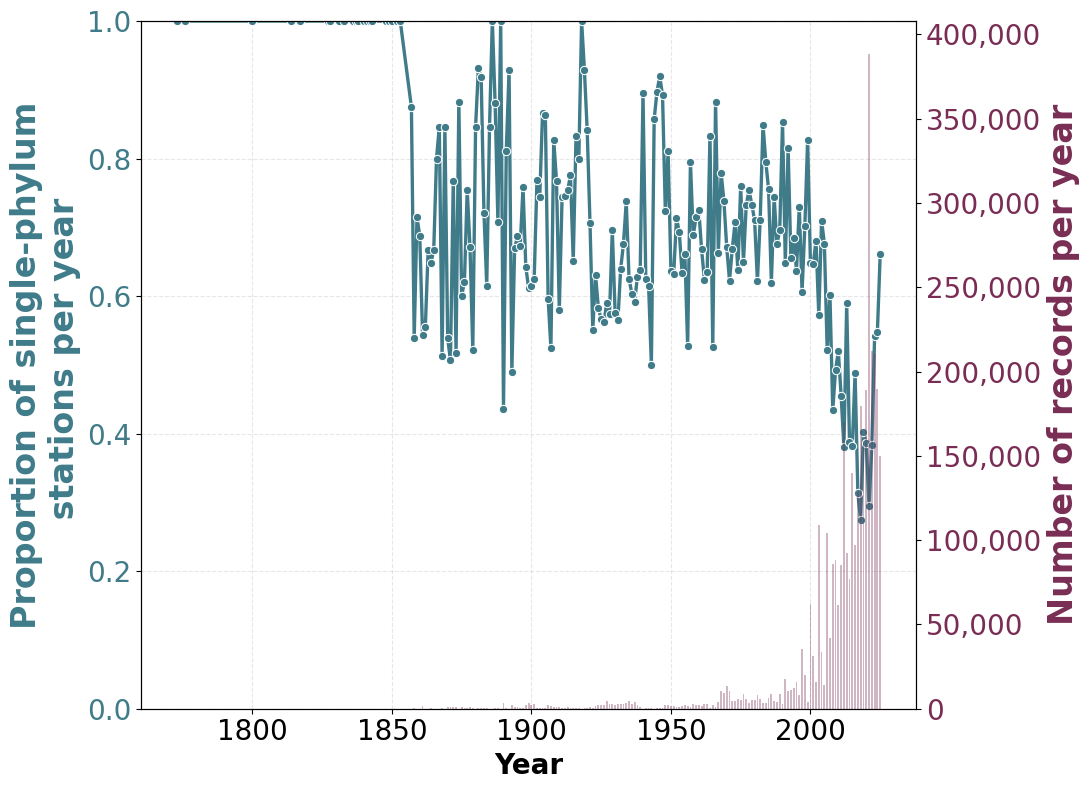

In [23]:
# Load outputs from prior cells
records_year = pd.read_parquet("records_year.parquet")
single_stats = pd.read_parquet("single_phylum.parquet")

# Align for plotting
plot_df_sorted = (
    pd.merge(single_stats, records_year, on="year", how="left")
    .sort_values("year")
 )
plot_df_sorted["RecordCount"] = plot_df_sorted["RecordCount"].fillna(0).astype(int)

# Colors per request
color_prop = '#3F7B89'  # proportion single-phylum (line)
color_recs = '#792D54'  # biota records per year (bars)

plt.figure(figsize=(11, 8))
ax1 = plt.gca()

# Draw bars first on the secondary axis (so the line can be drawn on top)
ax2 = ax1.twinx()
ax2.bar(plot_df_sorted['year'], plot_df_sorted['RecordCount'], color=color_recs, alpha=0.35, width=0.65)
ax2.set_ylabel('Number of records per year', color=color_recs, fontsize=24, fontweight='bold')
ax2.tick_params(axis='y', labelcolor=color_recs, labelsize=20)
ax2.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:,.0f}"))

# Draw the line on top for visibility
sns.lineplot(data=plot_df_sorted, x='year', y='prop_single_phylum', marker='o', color=color_prop, linewidth=2.4, ax=ax1)
ax1.set_ylabel('Proportion of single-phylum\n stations per year', color=color_prop, fontsize=24, fontweight='bold')
ax1.tick_params(axis='y', labelcolor=color_prop, labelsize=20)
ax1.set_ylim(0, 1)
ax1.grid(True, linestyle='--', alpha=0.3)
ax1.set_xlabel('Year', fontsize=20, fontweight='bold')
ax1.tick_params(axis="x", labelsize=20)

# Optional: annotate last points for clarity
last_row = plot_df_sorted.dropna(subset=['prop_single_phylum']).iloc[-1]
last_row_rec = plot_df_sorted.dropna(subset=['RecordCount']).iloc[-1]

plt.tight_layout()

# Save outputs
fig_path = 'single_phylum_years.png'
plt.savefig(fig_path, dpi=300, bbox_inches='tight', facecolor='None')
plt.show()

# Geomorphological features

Spatial join

In [62]:
# helper: drop rings < 4 points and invalid geometries  
def clean_poly(g):  
    if g is None: return None  
    try: g = make_valid(g)  
    except Exception: return None  
    if g.is_empty or not g.is_valid: return None  
    if g.geom_type == "Polygon":  
        return g if len(g.exterior.coords) >= 4 else None  
    if g.geom_type == "MultiPolygon":  
        parts = [p for p in g.geoms if len(p.exterior.coords) >= 4]  
        if not parts: return None  
        return MultiPolygon(parts) if len(parts) > 1 else parts[0]  
    return None  
  
# 1 ▸ device points  
df  = pd.read_parquet("all_stations.parquet")  
pts = gpd.GeoDataFrame(  
    df,  
    geometry=[Point(xy) for xy in zip(df["decimalLongitudeStart"], df["decimalLatitudeStart"])],  
    crs="EPSG:4326",  
)  
print("Station rows:", len(pts))  
  
# 2 ▸ shapefiles in Geo/  
shp_dir = pathlib.Path("../Geo")  
shps    = sorted(shp_dir.glob("*.shp"))  
print("Found", len(shps), "shapefiles in Geo/")  
  
joined = pts.copy()  
  
for shp in shps:  
    name = shp.stem  
    print("•", name)  
    raw = gpd.read_file(shp)  
    prop_cols = [c for c in raw.columns if c.lower() in ["class", "geomorphic"]]  
  
    # clean layer  
    records = []  
    for _, row in tqdm(raw.iterrows(), total=len(raw), leave=False):  
        geom = clean_poly(row.geometry)  
        if geom is None: continue  
        rec  = {name + "_" + c: row[c] for c in prop_cols}  
        rec["geometry"] = geom  
        records.append(rec)  
  
    if not records:  
        print("  ↳ skipped (no valid polygons)"); continue  
  
    layer = gpd.GeoDataFrame(records, crs=raw.crs).to_crs("EPSG:4326")  
    joined = gpd.sjoin(joined, layer, how="left", predicate="intersects").drop(columns="index_right")  

# Handle duplicate columns by renaming with suffix - after all joins complete
print("Checking for duplicate columns...")
cols = joined.columns.tolist()
new_cols = []
seen = {}
for col in cols:
    if col in seen:
        seen[col] += 1
        new_cols.append(f"{col}_{seen[col]}")
        print(f"  Renamed duplicate '{col}' → '{col}_{seen[col]}'")
    else:
        seen[col] = 0
        new_cols.append(col)
joined.columns = new_cols
  
# 3 ▸ reorder columns  
order = [  
    "Hadal", "Abyss", "Slope", "Shelf", "Abyssal_Classification", "Shelf_Classification",  
    "Plateaus", "Terraces", "Trenches", "Rises", "Fans", "Spreading_ridges", "Ridges",  
    "Troughs", "Rift_valleys", "Shelf_valleys", "Glacial_troughs", "Sills",  
    "Bridges", "Seamounts", "Guyots", "Canyons", "Escarpments", "Basins"  
]  
  
# build full ordered list: point columns first, then *_Class/_Geomorphic in order  
base_cols   = [c for c in joined.columns if c not in joined.geometry.name and not any(c.startswith(x + "_") for x in order)]  
ordered_cols = base_cols.copy()  
added = set(base_cols)  # Track which columns we've already added
for feat in order:  
    for c in joined.columns:
        if c.startswith(feat + "_") and c not in added:
            ordered_cols.append(c)
            added.add(c)
  
joined = joined[ordered_cols + [joined.geometry.name]]  
  
# 4 ▸ save + preview  
out_parquet = "all_stations_geo.parquet"  
joined.drop(columns="geometry").to_parquet(out_parquet, index=False)  
print("✓ saved to", out_parquet)  
print(joined.drop(columns='geometry').head())

Station rows: 163934
Found 24 shapefiles in Geo/
• Abyss


• Abyssal_Classification


• Basins


• Bridges


• Canyons


• Escarpments


... (16 outputs left out)

• Trenches


• Troughs


Checking for duplicate columns...


✓ saved to all_stations_geo.parquet
   decimalLatitudeStart  decimalLongitudeStart  \
0               81.0139                 8.0094   
1               81.8333                 8.5667   
2               76.4000                30.0000   
3               60.0678               168.7400   
4               60.8353               174.2519   

                             datasetKey datasetTitle sourceDatabase    year  \
0  005eb8d8-ed94-41be-89cf-e3115a9058e4          NaN           GBIF  1980.0   
1  005eb8d8-ed94-41be-89cf-e3115a9058e4          NaN           GBIF  1980.0   
2  005eb8d8-ed94-41be-89cf-e3115a9058e4          NaN           GBIF  1991.0   
3  005eb8d8-ed94-41be-89cf-e3115a9058e4          NaN           GBIF     NaN   
4  005eb8d8-ed94-41be-89cf-e3115a9058e4          NaN           GBIF  1996.0   

   gebcoDepth Hadal_Geomorphic Abyss_Geomorphic Slope_Geomorphic  ...  \
0      -838.0              NaN            Abyss              NaN  ...   
1      -775.0              NaN            

In [107]:
# Count stations by Shelf_Classification_Class in all_stations_geo.parquet
df_geo_full = pd.read_parquet("all_stations_geo.parquet")

shelf_counts = (
    df_geo_full["Shelf_Classification_Class"]
    .astype("string")
    .str.lower()
    .str.strip()
    .value_counts()
    .reindex(["high", "medium", "low"])
)

print(shelf_counts)

Shelf_Classification_Class
high      68518
medium    41163
low       19108
Name: count, dtype: int64[pyarrow]


Check all unique combinations

In [63]:
df = pd.read_parquet('all_stations_geo.parquet')
# columns D (index 3) to AD (index 29) inclusive
cols = df.columns[3:32]
subset = df[cols]
print('Selected columns:', list(cols))
# drop duplicates keep unique combos
unique_combos = subset.drop_duplicates().reset_index(drop=True)
print('Unique combinations count:', len(unique_combos))
# save to file for download
outfile = 'unique_geo_combinations.xlsx'
unique_combos.to_excel(outfile, index=False)
print('Saved to', outfile)

Selected columns: ['datasetTitle', 'sourceDatabase', 'year', 'gebcoDepth', 'Hadal_Geomorphic', 'Abyss_Geomorphic', 'Slope_Geomorphic', 'Shelf_Geomorphic', 'Shelf_Classification_Class', 'Shelf_Classification_Geomorphic', 'Shelf_valleys_Geomorphic', 'Abyssal_Classification_Class', 'Abyssal_Classification_Geomorphic', 'Plateaus_Geomorphic', 'Terraces_Geomorphic', 'Trenches_Geomorphic', 'Rises_Geomorphic', 'Fans_Geomorphic', 'Spreading_ridges_Geomorphic', 'Ridges_Geomorphic', 'Troughs_Geomorphic', 'Rift_valleys_Geomorphic', 'Glacial_troughs_Geomorphic', 'Sills_Geomorphic', 'Bridges_Geomorphic', 'Seamounts_Geomorphic', 'Guyots_Geomorphic', 'Canyons_Geomorphic', 'Escarpments_Geomorphic']
Unique combinations count: 78260
Saved to unique_geo_combinations.xlsx


Merge into 7 main categories

In [65]:
input_file = "all_stations_geo.parquet"   
df_geo = pd.read_parquet(input_file)  
  
print("Rows:", len(df_geo))  

# 2. Create the target column and initialize with empty strings  
df_geo["Geo_category"] = ""  

# 3.1  Shelf + high  ➜  Deep shelf  
mask = (  
    df_geo["Shelf_Geomorphic"].str.contains("Shelf", case=False, na=False)  
    & df_geo["Shelf_Classification_Class"].str.contains("high", case=False, na=False)  
)  
df_geo.loc[mask, "Geo_category"] = "Deep shelf"  
  
# 3.2  Shelf + medium  ➜  Medium shelf  
mask = (  
    df_geo["Shelf_Geomorphic"].str.contains("Shelf", case=False, na=False)  
    & df_geo["Shelf_Classification_Class"].str.contains("medium", case=False, na=False)  
    & (df_geo["Geo_category"] == "")  
)  
df_geo.loc[mask, "Geo_category"] = "Medium shelf"  
  
# 3.3  Shelf + low  ➜  Shallow shelf  
mask = (  
    df_geo["Shelf_Geomorphic"].str.contains("Shelf", case=False, na=False)  
    & df_geo["Shelf_Classification_Class"].str.contains("low", case=False, na=False)  
    & (df_geo["Geo_category"] == "")  
)  
df_geo.loc[mask, "Geo_category"] = "Shallow shelf"  
  
# 3.4  Slope  ➜  Slope  
mask = (  
    df_geo["Slope_Geomorphic"].str.contains("Slope", case=False, na=False)  
    & (df_geo["Geo_category"] == "")  
)  
df_geo.loc[mask, "Geo_category"] = "Slope"  
  
# 3.5  Ridges_Geomorphic with “Ridge”  ➜  Ridges  
mask = (  
    df_geo["Ridges_Geomorphic"].str.contains("Ridge", case=False, na=False)  
    & (df_geo["Geo_category"] == "")  
)  
df_geo.loc[mask, "Geo_category"] = "Ridges"  
  
# 3.6  Spreading_ridges_Geomorphic with “Spreading Ridge”  ➜  Ridges  
mask = (  
    df_geo["Spreading_ridges_Geomorphic"].str.contains("Spreading Ridge", case=False, na=False)  
    & (df_geo["Geo_category"] == "")  
)  
df_geo.loc[mask, "Geo_category"] = "Ridges"  
  
# 3.7  Rift_valleys_Geomorphic with “Rift Valley”  ➜  Ridges  
mask = (  
    df_geo["Rift_valleys_Geomorphic"].str.contains("Rift Valley", case=False, na=False)  
    & (df_geo["Geo_category"] == "")  
)  
df_geo.loc[mask, "Geo_category"] = "Ridges"  
  
# 3.8  Abyssal_Classification_Class with “Hills” or “Mountains”  ➜  Abyssal mountains and hills
mask = (  
    df_geo["Abyssal_Classification_Class"].str.contains("Hills|Mountains", case=False, na=False)  
    & (df_geo["Geo_category"] == "")  
)  
df_geo.loc[mask, "Geo_category"] = "Abyssal mountains and hills"  
  
# 3.9  Seamounts_Geomorphic with “Seamount”  ➜  Abyssal mountains and hills 
mask = (  
    df_geo["Seamounts_Geomorphic"].str.contains("Seamount", case=False, na=False)  
    & (df_geo["Geo_category"] == "")  
)  
df_geo.loc[mask, "Geo_category"] = "Abyssal mountains and hills"  
  
# 3.10  Abyssal_Classification_Class with “Plains”  ➜  Abyssal plains and hadal zones
mask = (  
    df_geo["Abyssal_Classification_Class"].str.contains("Plains", case=False, na=False)  
    & (df_geo["Geo_category"] == "")  
)  
df_geo.loc[mask, "Geo_category"] = "Abyssal plains and hadal zones"  
  
# 3.11  Hadal_Geomorphic with “Hadal”  ➜  Abyssal plains and hadal zones  
mask = (  
    df_geo["Hadal_Geomorphic"].str.contains("Hadal", case=False, na=False)  
    & (df_geo["Geo_category"] == "")  
)  
df_geo.loc[mask, "Geo_category"] = "Abyssal plains and hadal zones"  

# Save as excel
output_file = "all_stations_geo_collapsed.parquet"  
df_geo.to_parquet(output_file, index=False)  
  
print("Saved new file:", output_file)  

Rows: 163934
Saved new file: all_stations_geo_collapsed.parquet


Delete unnecessary columns

In [84]:
# Load existing collapsed file 
input_file = 'all_stations_geo_collapsed.parquet'
df_geo = pd.read_parquet(input_file)

# Retain only desired columns (remove sourceDatabase to avoid duplicates)
keep_cols = ['year', 'decimalLatitudeStart', 'decimalLongitudeStart', 'Geo_category']
df_geo = df_geo[keep_cols]

# Deduplicate on (lat, lon, year) - same location should have one Geo_category
df_geo = df_geo.drop_duplicates(subset=['decimalLatitudeStart', 'decimalLongitudeStart', 'year'], keep='first')

# Save to a new file
output_file = 'all_stations_geo_collapsed.parquet'
df_geo.to_parquet(output_file, index=False)

# Show head for confirmation
print(df_geo.head())
print('Saved file as', output_file)
print(f'Total unique station-years: {len(df_geo)}')

     year  decimalLatitudeStart  decimalLongitudeStart  \
0  1980.0               81.0139                 8.0094   
1  1980.0               81.8333                 8.5667   
2  1991.0               76.4000                30.0000   
3     NaN               60.0678               168.7400   
4  1996.0               60.8353               174.2519   

                     Geo_category  
0  Abyssal plains and hadal zones  
1  Abyssal plains and hadal zones  
2                    Medium shelf  
3                      Deep shelf  
4                           Slope  
Saved file as all_stations_geo_collapsed.parquet
Total unique station-years: 134192


How many row lack geo classification? 

In [85]:
# Calculate nr of rows that are lacking a geo category

df = pd.read_parquet('all_stations_geo_collapsed.parquet')

missing_mask = df['Geo_category'].isna() | (df['Geo_category'].str.strip() == '')
missing_count = missing_mask.sum()
print('Missing rows count:', missing_count)

Missing rows count: 6392


Add the Geo_category column to all_merged

In [86]:
# Load the two parquet files
all_merged = pd.read_parquet("all_merged.parquet")
geo_collapsed = pd.read_parquet("all_stations_geo_collapsed.parquet")

# Merge on the combination of decimalLatitudeStart, decimalLongitudeStart, and year
all_merged_geo = all_merged.merge(
    geo_collapsed[['decimalLatitudeStart', 'decimalLongitudeStart', 'year', 'Geo_category']],
    on=['decimalLatitudeStart', 'decimalLongitudeStart', 'year'],
    how='left'
)

# Save the merged dataframe
all_merged_geo.to_parquet("all_merged_geo.parquet", index=False)

print(f"Merged dataframe shape: {all_merged_geo.shape}")
print(f"Original all_merged: {len(all_merged)} records")
print(f"Geo_category column added with {all_merged_geo['Geo_category'].notna().sum()} non-null values")
print(all_merged_geo[['decimalLatitudeStart', 'decimalLongitudeStart', 'year', 'Geo_category']].head(10))

Merged dataframe shape: (3614601, 69)
Original all_merged: 3614601 records
Geo_category column added with 3614601 non-null values
   decimalLatitudeStart  decimalLongitudeStart    year  \
0               81.0139                 8.0094  1980.0   
1               81.8333                 8.5667  1980.0   
2               76.4000                30.0000  1991.0   
3               81.0139                 8.0094  1980.0   
4               81.8333                 8.5667  1980.0   
5               60.0678               168.7400     NaN   
6               60.8353               174.2519  1996.0   
7               81.8333                 8.5667  1980.0   
8               60.1178               169.1347  1988.0   
9               61.7828               178.5872  1994.0   

                     Geo_category  
0  Abyssal plains and hadal zones  
1  Abyssal plains and hadal zones  
2                    Medium shelf  
3  Abyssal plains and hadal zones  
4  Abyssal plains and hadal zones  
5              

In [87]:
# Count records per Geo_category in all_merged_geo.parquet
all_merged_geo = pd.read_parquet("all_merged_geo.parquet")

geo_category_counts = all_merged_geo['Geo_category'].value_counts(dropna=False)

print("Records per Geo_category:")
print(geo_category_counts)
print(f"\nTotal records: {len(all_merged_geo)}")

Records per Geo_category:
Geo_category
Deep shelf                        1819727
Medium shelf                      1141553
Shallow shelf                      246677
Slope                              200347
                                   141253
Abyssal mountains and hills         33178
Ridges                              22812
Abyssal plains and hadal zones       9054
Name: count, dtype: int64

Total records: 3614601


Visualize

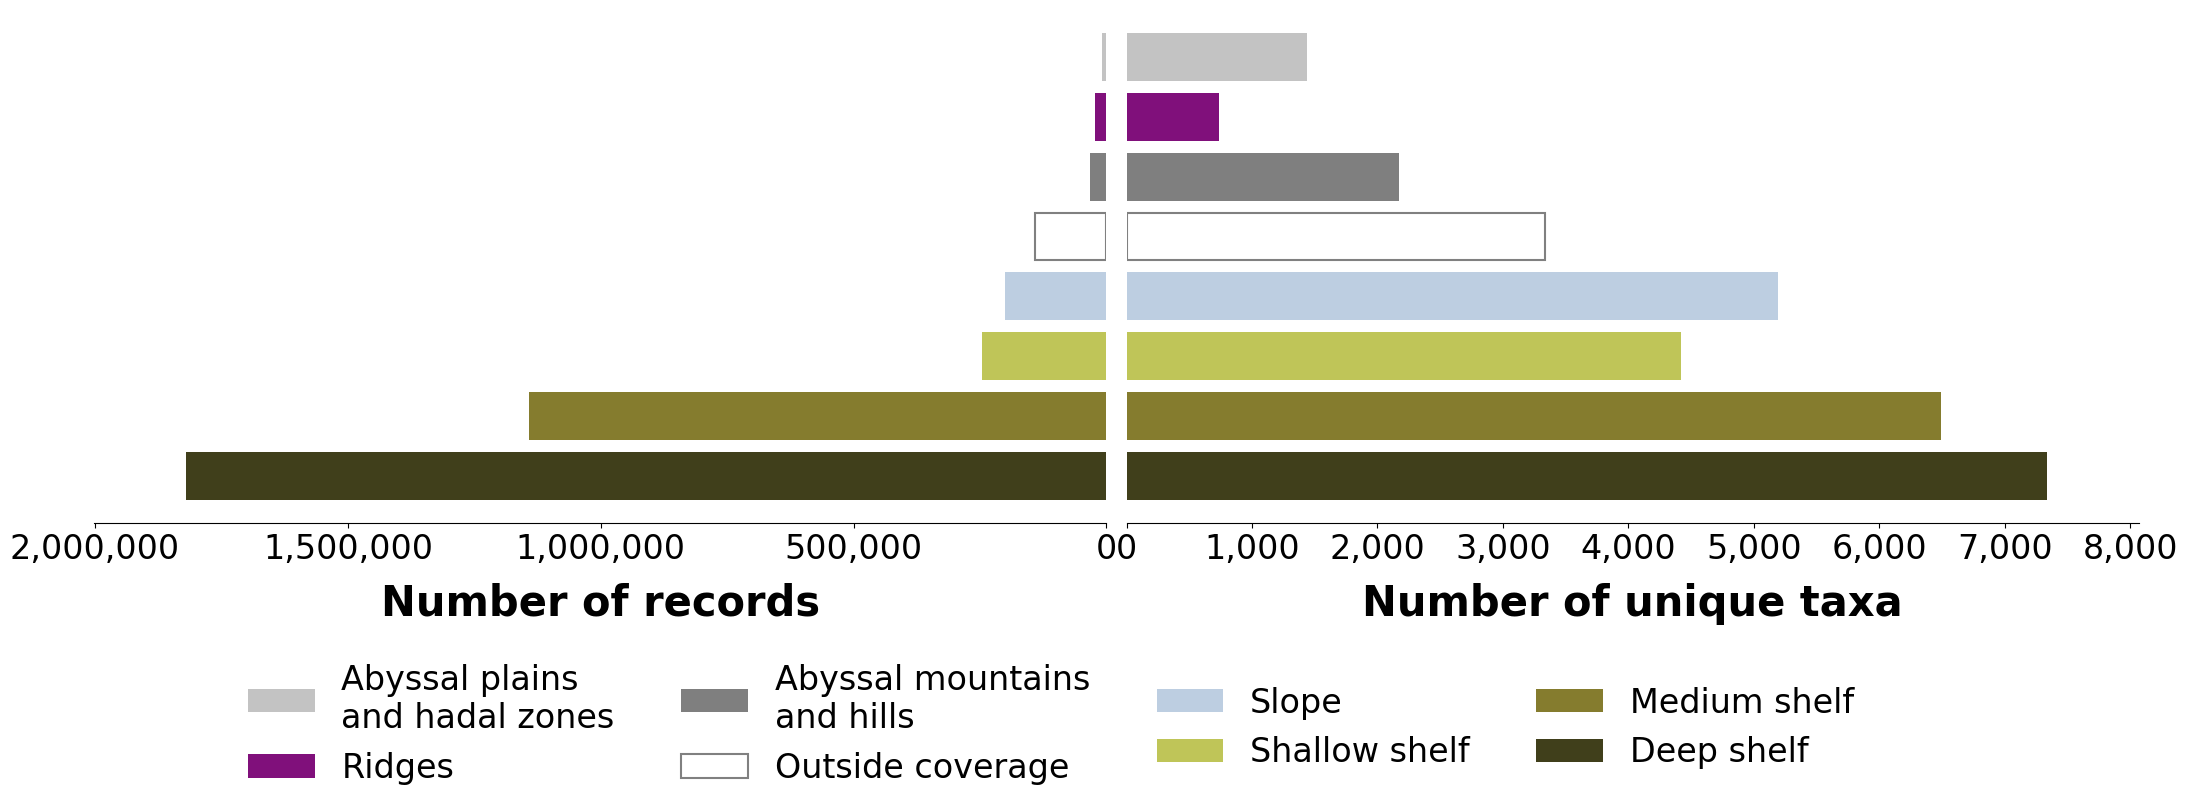

In [24]:
# Load the Excel file
geo_path = 'all_merged_geo.parquet'
biota_geo_df = pd.read_parquet(geo_path)
# Clean column names and handle missing values
biota_geo_df.columns = [c.strip() for c in biota_geo_df.columns]  # Strip whitespace from column names
geo_col = 'Geo_category'
accepted_col = 'aphiaID'
# Ensure required columns exist
if geo_col not in biota_geo_df.columns or accepted_col not in biota_geo_df.columns:
    raise KeyError(f"Required column(s) missing: {geo_col} or {accepted_col}")
# Convert 'AphiaId (Accepted)' to numeric and handle missing values in 'Geo_category'
biota_geo_df[accepted_col] = pd.to_numeric(biota_geo_df[accepted_col], errors='coerce')
# Replace NaN AND empty strings with 'Outside geomorphological categories'
biota_geo_df[geo_col] = biota_geo_df[geo_col].fillna('Outside geomorphological categories')
biota_geo_df[geo_col] = biota_geo_df[geo_col].replace('', 'Outside geomorphological categories')
# Group by 'Geo_category' to calculate metrics
total_records = biota_geo_df.groupby(geo_col, dropna=False).size().reset_index(name='total_records')
unique_taxa = (
    biota_geo_df.dropna(subset=[accepted_col])
                .groupby(geo_col, dropna=False)[accepted_col]
                .nunique()
                .reset_index(name='unique_taxa')
)
# Merge metrics into a single DataFrame
summary_df = pd.merge(total_records, unique_taxa, on=geo_col, how='outer').fillna(0)
summary_df['total_records'] = summary_df['total_records'].astype(int)
summary_df['unique_taxa'] = summary_df['unique_taxa'].astype(int)
# Sort data so that categories with the highest number of records are lowest on the y-axis
summary_df = summary_df.sort_values('total_records', ascending=False)
# Define colors for each category
category_colors = {
    'Abyssal plains and hadal zones': '#C3C3C3',
    'Ridges': '#80107B',
    'Abyssal mountains and hills': '#7F7F7F',
    'Slope': '#BDCEE1',
    'Deep shelf': '#403F1B',
    'Medium shelf': '#857C2E',
    'Shallow shelf': '#BFC558',
    'Outside geomorphological categories': 'white',
}
# Custom legend labels (use \n for line breaks)
legend_label_map = {
    'Abyssal plains and hadal zones': 'Abyssal plains\nand hadal zones',
    'Abyssal mountains and hills': 'Abyssal mountains\nand hills',
    'Outside geomorphological categories': 'Outside coverage',
    # 'Ridges': 'Ridges',
    # 'Slope': 'Slope',
    # 'Deep shelf': 'Deep shelf',
    # 'Medium shelf': 'Medium shelf',
    # 'Shallow shelf': 'Shallow shelf',
}
# Prepare data for plotting
categories = summary_df[geo_col].tolist()
bar_colors = [category_colors.get(cat, 'lightgray') for cat in categories]  # Use .get() with default color
# Define edge colors: black border only for "Outside geomorphological coverage"
bar_edge_colors = ['gray' if cat == 'Outside geomorphological categories' else 'none' for cat in categories]
# Create mirrored bar plot
fig, (ax_left, ax_right) = plt.subplots(
    ncols=2, figsize=(22, 7), gridspec_kw={'width_ratios': [1, 1]}
)
# Plot bars
bars_left = ax_left.barh(
    categories, 
    -summary_df['total_records'], 
    color=bar_colors, 
    edgecolor=bar_edge_colors, 
    linewidth=1.5,  # Set border width
    label='Total records',
)
bars_right = ax_right.barh(
    categories, 
    summary_df['unique_taxa'], 
    color=bar_colors, 
    edgecolor=bar_edge_colors, 
    linewidth=1.5,  # Set border width
    label='Unique taxa',
)
# Format axes
ax_left.set_xlabel('Number of records', fontsize=30, fontweight='bold', labelpad=12)
ax_left.set_xlim(-summary_df['total_records'].max() * 1.1, 0)
ax_left.spines['right'].set_visible(False)
ax_left.spines['top'].set_visible(False)
ax_left.spines['left'].set_visible(False)
ax_left.xaxis.set_major_locator(MaxNLocator(nbins=5, integer=True))
ax_left.xaxis.set_major_formatter(FuncFormatter(lambda x, pos: f"{int(abs(x)):,}"))
ax_left.tick_params(axis='x', labelsize=24)
ax_right.set_xlabel('Number of unique taxa', fontsize=30, fontweight='bold', labelpad=12)
ax_right.set_xlim(0, summary_df['unique_taxa'].max() * 1.1)
ax_right.spines['left'].set_visible(False)
ax_right.spines['top'].set_visible(False)
ax_right.spines['right'].set_visible(False)
ax_right.xaxis.set_major_formatter(FuncFormatter(lambda x, pos: f"{int(x):,}"))
ax_right.tick_params(axis='x', labelsize=24)

# Remove y-ticks and labels
ax_left.set_yticks([])
ax_left.set_yticklabels([])
ax_right.set_yticks([])
ax_right.set_yticklabels([])
# Add a legend below the plot
legend_labels = [legend_label_map.get(cat, cat) for cat in categories]
legend_patches = [
    Patch(
        facecolor=category_colors.get(cat, 'lightgray'), 
        edgecolor='gray' if cat == 'Outside geomorphological categories' else 'none', 
        linewidth=1.5
    ) 
    for cat in categories
]
fig.legend(
    legend_patches[::-1], 
    legend_labels[::-1], 
    loc='lower center', 
    bbox_to_anchor=(0.48, -0.25), 
    ncol=4, 
    fontsize=24, 
    frameon=False,
    markerscale=3
)
# Adjust layout and save the plot
plt.tight_layout()
plt.subplots_adjust(top=0.9, wspace=0.02)
plt.savefig('geo_records_taxa.png', dpi=300, bbox_inches='tight', facecolor='None', transparent=True)
plt.show()

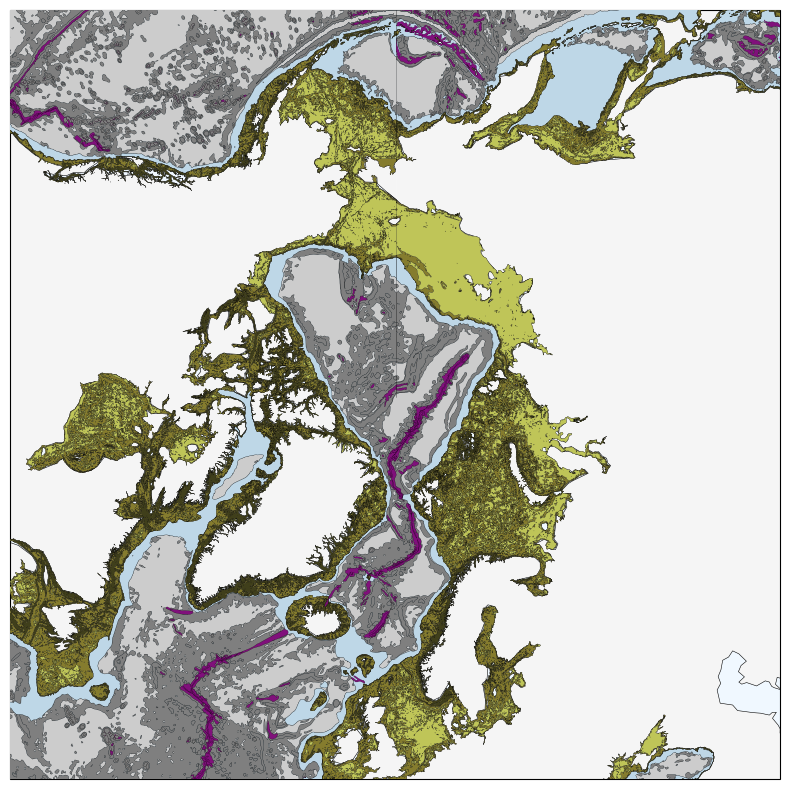

In [25]:
# ------------------------------------------ Map ------------------------------------------------

# Cell 1 — Imports and config

# Folder containing your shapefiles
geo_dir = '../Geo'
# List of shapefile filenames to load from ./Geo (add more as needed)
layer_files = [
    'Hadal.shp',
    'Abyss.shp',
    'Slope.shp',
    'Shelf.shp',
    'Abyssal_Classification.shp',
    'Shelf_Classification.shp',
    'Spreading_ridges.shp',
    'Ridges.shp',
    'Rift_valleys.shp',
    'Seamounts.shp'
]

# Cell 2 — Load shapefiles from ./Geo
layers = {}
for fname in layer_files:
    fpath = os.path.join(geo_dir, fname)
    if os.path.exists(fpath):
        gdf_loaded = gpd.read_file(fpath)
        key_name = os.path.splitext(fname)[0]
        layers[key_name] = gdf_loaded

# Cell 3 — Configure class colors (RGBA) and defaults
abyssal_class_field = 'Class'  # Update this if your column name differs
abyssal_class_colors = {
    'Hills': (0.498, 0.498, 0.498, 1.0),  # fixed
    'Mountains': (0.498, 0.498, 0.498, 1.0),  # fixed
    'Plains': (0.8, 0.8, 0.8, 1.0)   # fixed
}
shelf_class_field = 'Class'  # Update this if your column name differs
shelf_class_colors = {
    'high': (0.251, 0.247, 0.106, 1.0),  # Light blue
    'medium': (0.522, 0.486, 0.180, 1.0),  # Green
    'low': (0.749, 0.773, 0.345, 1.0)   # Orange
}
layer_colors_rgba = {
    'Hadal': (0.8, 0.8, 0.8, 1.0),  # Dark blue, previously (0.129, 0.443, 0.710, 1.0)
    'Abyss': (0.420, 0.682, 0.843, 1.0),  # Light blue
    'Ridges': (0.502, 0.063, 0.482, 1.0),  # Purple
    'Slope': (0.745, 0.843, 0.906, 1.0),  # Purple
    'Shelf': (0.933, 0.953, 1.0, 1.0),  # Purple
    'Spreading_ridges': (0.502, 0.063, 0.482, 1.0),  # Purple
    'Rift_valleys': (0.502, 0.063, 0.482, 1.0),  # Purple
    'Seamounts': (0.498, 0.498, 0.498, 1.0)  # Purple
}
default_color = (0.5, 0.5, 0.5, 0.5)  # Gray with transparency

# Simplify geometries for faster plotting
simp_tol_deg = 0.02
simplified_layers = {}
for lname, gdf in layers.items():
    sgdf = gdf.copy()
    sgdf['geometry'] = sgdf.geometry.simplify(simp_tol_deg, preserve_topology=True)
    simplified_layers[lname] = sgdf

# Cell 4 — Plot preview (rasterized)
fig = plt.figure(figsize=(8, 8))
ax = plt.axes(projection=ccrs.NorthPolarStereo())
ax.set_extent([-180, 180, 50, 90], crs=ccrs.PlateCarree())
ax.add_feature(cfeature.LAND, facecolor='whitesmoke', zorder=0)
ax.add_feature(cfeature.OCEAN, facecolor='aliceblue', zorder=0)
ax.coastlines(resolution='110m', linewidth=0.4, color='black', zorder=2)
legend_handles = []
# Define zorder for each layer explicitly
layer_zorder = {
    'Hadal': 3,
    'Abyss': 4,
    'Abyssal_Classification': 5,
    'Shelf_Classification': 8,
    'Slope': 7,
    'Shelf': 6,
    'Spreading_ridges': 9,
    'Ridges': 10,
    'Rift_valleys': 11,
    'Seamounts': 12
}
# Plot layers in the specified order with explicit zorder
for fname in layer_files:
    lname = os.path.splitext(fname)[0]  # Get layer name without extension
    if lname in simplified_layers:
        gdf = simplified_layers[lname]
        rgba = layer_colors_rgba.get(lname, default_color)
        geoms = [geom for geom in gdf.geometry if geom is not None]
        if len(geoms) > 0:
            artist = ax.add_geometries(
                geoms,
                crs=ccrs.PlateCarree(),
                facecolor=rgba,
                edgecolor='k',
                linewidth=0.15,
                alpha=rgba[3],
                zorder=layer_zorder[lname]  # Use explicit zorder
            )
            legend_handles.append(Patch(facecolor=rgba, edgecolor='k', label=lname))
# Plot Abyssal_Classification with class-specific colors
if 'Abyssal_Classification' in simplified_layers:
    gdfc = simplified_layers['Abyssal_Classification']
    for cls_name, cls_rgba in abyssal_class_colors.items():
        subset = gdfc[gdfc[abyssal_class_field].astype(str) == cls_name]
        geoms = [geom for geom in subset.geometry if geom is not None]
        if len(geoms) > 0:
            artist = ax.add_geometries(
                geoms,
                crs=ccrs.PlateCarree(),
                facecolor=cls_rgba,
                edgecolor='k',
                linewidth=0.12,
                alpha=cls_rgba[3],
                zorder=layer_zorder['Abyssal_Classification']  # Explicit zorder for Abyssal_Classification
            )
            legend_handles.append(Patch(facecolor=cls_rgba, edgecolor='k', label='Abyssal ' + cls_name))
# Plot Shelf_Classification with class-specific colors
if 'Shelf_Classification' in simplified_layers:
    gdfc = simplified_layers['Shelf_Classification']
    for cls_name, cls_rgba in shelf_class_colors.items():
        subset = gdfc[gdfc[shelf_class_field].astype(str) == cls_name]
        geoms = [geom for geom in subset.geometry if geom is not None]
        if len(geoms) > 0:
            artist = ax.add_geometries(
                geoms,
                crs=ccrs.PlateCarree(),
                facecolor=cls_rgba,
                edgecolor='k',
                linewidth=0.12,
                alpha=cls_rgba[3],
                zorder=layer_zorder['Shelf_Classification']  # Explicit zorder for Shelf_Classification
            )

plt.tight_layout()
out_path = 'geo_map.png'
plt.savefig(out_path, dpi=300)
plt.show()

In [105]:
# Load the parquet file and save as CSV
df_geo = pd.read_parquet("all_stations_geo_collapsed.parquet")
df_geo.to_csv("all_stations_geo.csv", index=False)
print(f"Saved {len(df_geo)} rows to all_stations_geo.csv")

Saved 134192 rows to all_stations_geo.csv


Biomass, gear, samplingEffort

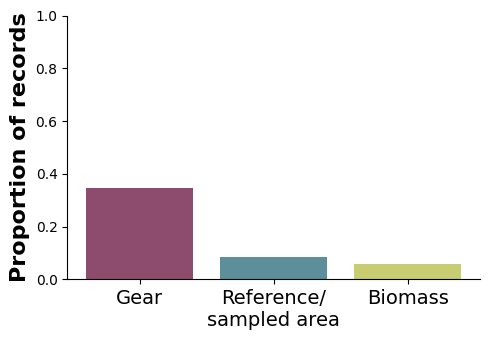

In [128]:
# Proportion of records with gear, samplingEffort, and biomass
all_merged = pd.read_parquet("all_merged.parquet")

cols = ["gear", "samplingEffort", "biomass"]
missing_cols = [c for c in cols if c not in all_merged.columns]
if missing_cols:
    raise KeyError(f"Missing columns in all_merged.parquet: {missing_cols}")

def has_value(s):
    return s.notna() & (s.astype("string").str.strip() != "")

coverage = pd.DataFrame({
    "column": cols,
    "proportion": [has_value(all_merged[c]).mean() for c in cols]
})

# Rename for display
label_map = {
    "gear": "Gear",
    "samplingEffort": "Reference/\nsampled area",
    "biomass": "Biomass"
}
display_labels = [label_map[c] for c in coverage["column"]]

# Use existing palette style
colors = ["#792D54", "#3F7B89", "#BFC558"]

plt.figure(figsize=(5, 3.5))
ax = plt.gca()
bars = ax.bar(display_labels, coverage["proportion"], color=colors, alpha=0.85)

ax.set_ylim(0, 1)
ax.set_ylabel("Proportion of records", fontsize=16, fontweight="bold")
ax.grid(axis="y", linestyle='None', alpha=0.3)

# Remove right and top spines
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)

ax.tick_params(axis='x', labelsize=14)

plt.tight_layout()
plt.savefig("coverage_biomass_etc.png", dpi=200, bbox_inches="tight", facecolor="white")
plt.show()

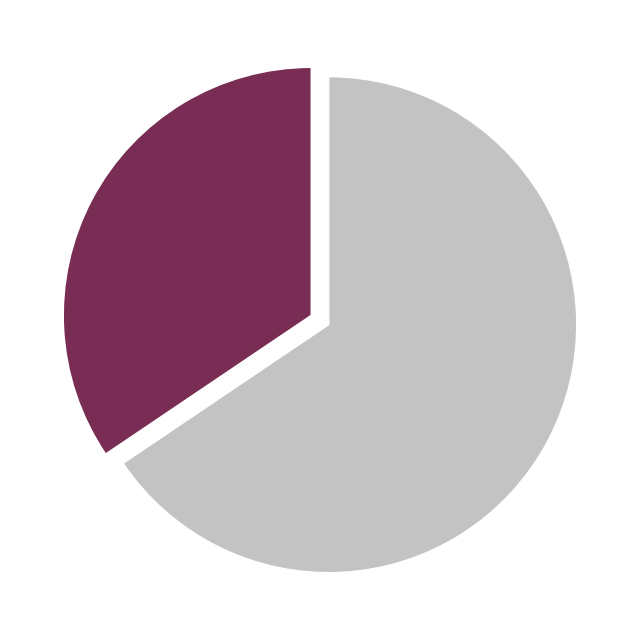

In [141]:
# Pie chart for gear coverage (uses existing all_merged and has_value)
gear_has = has_value(all_merged["gear"])
counts = pd.Series(
    {"With gear": int(gear_has.sum()), "Missing gear": int((~gear_has).sum())}
)

colors = ["#792D54", "#C3C3C3"]
explode = (0.04, 0.04)

fig, ax = plt.subplots(figsize=(6.5, 6.5))
wedges, texts = ax.pie(
    counts.values,
    colors=colors,
    explode=explode,
    startangle=90,
    wedgeprops=dict(edgecolor="white"),
)

ax.set_aspect("equal")

plt.tight_layout()
plt.savefig("gear_coverage_pie.png", dpi=200, bbox_inches="tight", facecolor="white")
plt.show()

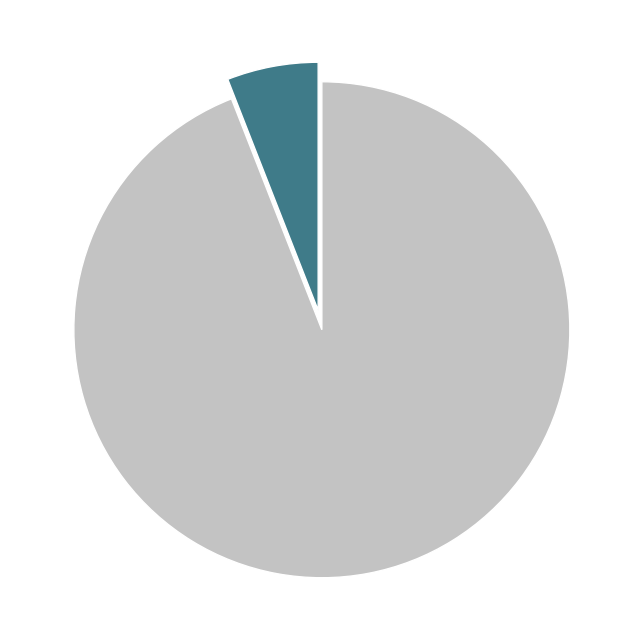

In [142]:
# Pie chart for gear coverage (uses existing all_merged and has_value)
gear_has = has_value(all_merged["biomass"])
counts = pd.Series(
    {"With gear": int(gear_has.sum()), "Missing gear": int((~gear_has).sum())}
)

colors = ["#3F7B89", "#C3C3C3"]
explode = (0.04, 0.04)

fig, ax = plt.subplots(figsize=(6.5, 6.5))
wedges, texts = ax.pie(
    counts.values,
    colors=colors,
    explode=explode,
    startangle=90,
    wedgeprops=dict(edgecolor="white"),
)

ax.set_aspect("equal")

plt.tight_layout()
plt.savefig("biomass_coverage_pie.png", dpi=200, bbox_inches="tight", facecolor="white")
plt.show()

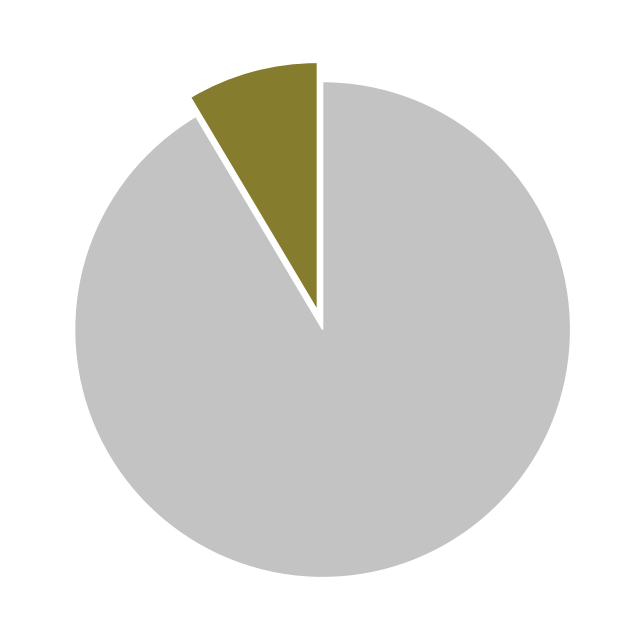

In [143]:
# Pie chart for gear coverage (uses existing all_merged and has_value)
gear_has = has_value(all_merged["samplingEffort"])
counts = pd.Series(
    {"With gear": int(gear_has.sum()), "Missing gear": int((~gear_has).sum())}
)

colors = ["#857C2E", "#C3C3C3"]
explode = (0.04, 0.04)

fig, ax = plt.subplots(figsize=(6.5, 6.5))
wedges, texts = ax.pie(
    counts.values,
    colors=colors,
    explode=explode,
    startangle=90,
    wedgeprops=dict(edgecolor="white"),
)

ax.set_aspect("equal")

plt.tight_layout()
plt.savefig("samplingeffort_coverage_pie.png", dpi=200, bbox_inches="tight", facecolor="white")
plt.show()

# Count the nr of aphiaID

In [127]:

# Count unique aphiaID entries in all_merged.parquet
all_merged = pd.read_parquet("all_merged.parquet")

unique_aphia_count = all_merged['aphiaID'].nunique()

print(f"Number of unique aphiaID entries: {unique_aphia_count}")

Number of unique aphiaID entries: 10354


In [129]:
df_geo = pd.read_parquet(input_file)
unique_station_years = df_geo.drop_duplicates(
    subset=["decimalLatitudeStart", "decimalLongitudeStart", "year"]
)
print("Total unique lat/lon/year combinations:", len(unique_station_years))

Total unique lat/lon/year combinations: 134192


# Most common phyla

In [3]:
# Use existing all_merged if available; otherwise load it
if "all_merged" not in globals():
    all_merged = pd.read_parquet("all_merged.parquet")

required_cols = ["phylum", "aphiaID"]
missing_cols = [c for c in required_cols if c not in all_merged.columns]
if missing_cols:
    raise KeyError(f"Missing columns: {missing_cols}")

phylum_stats = (
    all_merged.assign(
        phylum=all_merged["phylum"].astype("string").fillna("Unknown").str.strip().replace("", "Unknown")
    )
    .groupby("phylum", dropna=False)
    .agg(
        record_count=("aphiaID", "size"),
        unique_aphiaID=("aphiaID", "nunique"),
    )
    .reset_index()
    .sort_values("record_count", ascending=False)
)

phylum_stats

,phylum,record_count,unique_aphiaID
0,Annelida,1662419,1946
16,Mollusca,783392,1696
1,Arthropoda,504899,2536
10,Echinodermata,250319,772
23,Porifera,106332,945
8,Cnidaria,105865,835
27,Sipuncula,65432,39
19,Nemertea,40140,89
3,Bryozoa,24853,622
6,Chordata,23981,343


# Nr of species

In [4]:
# Count unique species from records where taxonRank = SPECIES
species_records = all_merged[all_merged["taxonRank"] == "SPECIES"]
unique_species_count = species_records["acceptedScientificName"].nunique()

print(f"Number of unique species (acceptedScientificName where taxonRank = SPECIES): {unique_species_count}")

Number of unique species (acceptedScientificName where taxonRank = SPECIES): 6668


# Column coverage

In [3]:
# Percent coverage for each column in all_merged_geo.parquet
df_cov = pd.read_parquet("all_merged_geo.parquet")

total_rows = len(df_cov)

def non_missing_mask(s):
    m = s.notna()
    # Treat empty/whitespace-only strings as missing
    if pd.api.types.is_object_dtype(s) or pd.api.types.is_string_dtype(s):
        m &= s.astype("string").str.strip().ne("")
    return m

coverage_df = pd.DataFrame({
    "column": df_cov.columns,
    "non_missing": [non_missing_mask(df_cov[c]).sum() for c in df_cov.columns],
})

coverage_df["total_rows"] = total_rows
coverage_df["coverage_percent"] = (coverage_df["non_missing"] / total_rows * 100).round(2)
coverage_df = coverage_df.sort_values("coverage_percent", ascending=False).reset_index(drop=True)

coverage_df
coverage_df.to_csv("column_coverage.csv", index=False)

# Spatial join LME

In [12]:
# Spatial join: add LME name to all_merged_geo using intersects
all_merged_geo = pd.read_parquet("all_merged_geo.parquet").copy()
all_merged_geo["_row_id"] = np.arange(len(all_merged_geo))

# Build valid point geometries
lon = pd.to_numeric(all_merged_geo["decimalLongitudeStart"], errors="coerce")
lat = pd.to_numeric(all_merged_geo["decimalLatitudeStart"], errors="coerce")
valid = lon.between(-180, 180) & lat.between(-90, 90)

pts = gpd.GeoDataFrame(
    all_merged_geo.loc[valid, ["_row_id"]].copy(),
    geometry=gpd.points_from_xy(lon[valid], lat[valid]),
    crs="EPSG:4326",
)

# Load LME polygons
lme_path = "../LME_boundaries_2014/LME_2013_polygon_projected.shp"
lme_gdf = gpd.read_file(lme_path).to_crs("EPSG:4326")

# Find LME name column (expects "LME", fallback to first column containing "lme")
if "LME" in lme_gdf.columns:
    lme_col = "LME"
else:
    candidates = [c for c in lme_gdf.columns if "lme" in c.lower()]
    if not candidates:
        raise KeyError("No LME name column found in shapefile.")
    lme_col = candidates[0]

# Spatial join with intersects
joined = gpd.sjoin(
    pts,
    lme_gdf[[lme_col, "geometry"]],
    how="left",
    predicate="intersects"
).drop(columns=["index_right"], errors="ignore")

# If a point intersects multiple polygons, keep first non-null LME
lme_map = (
    joined.groupby("_row_id")[lme_col]
    .agg(lambda s: next((v for v in s if pd.notna(v) and str(v).strip() != ""), np.nan))
)

# Write result back
all_merged_geo["LME"] = all_merged_geo["_row_id"].map(lme_map)
all_merged_geo = all_merged_geo.drop(columns="_row_id")

# Save
all_merged_geo.to_parquet("all_merged_geo_LME.parquet", index=False)

print("Saved with LME column:", all_merged_geo["LME"].notna().sum(), "rows matched")
all_merged_geo[["decimalLatitudeStart", "decimalLongitudeStart", "LME"]].head()

Saved with LME column: 3614601 rows matched


,decimalLatitudeStart,decimalLongitudeStart,LME
0,81.0139,8.0094,Barents Sea LME
1,81.8333,8.5667,Barents Sea LME
2,76.4000,30.0000,Barents Sea LME
3,81.0139,8.0094,Barents Sea LME
4,81.8333,8.5667,Barents Sea LME


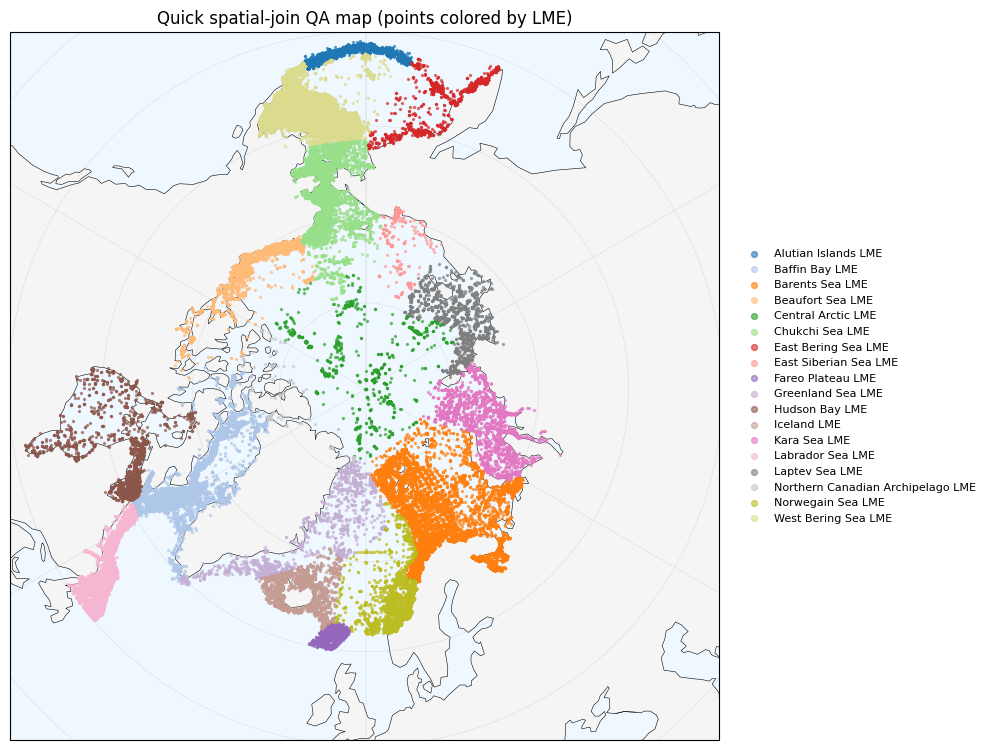

In [13]:
# Quick QA map for spatial join accuracy (LME-colored points, polar projection)

# Load from saved parquet to avoid kernel state mismatch
df_plot = pd.read_parquet("all_merged_geo_LME.parquet").copy()
if "LME" not in df_plot.columns:
    raise KeyError("Column 'LME' not found in all_merged_geo_LME.parquet")

# Keep only rows with usable coordinates
df_plot["decimalLatitudeStart"] = pd.to_numeric(df_plot["decimalLatitudeStart"], errors="coerce")
df_plot["decimalLongitudeStart"] = pd.to_numeric(df_plot["decimalLongitudeStart"], errors="coerce")

df_plot = df_plot[
    df_plot["decimalLatitudeStart"].between(-90, 90)
    & df_plot["decimalLongitudeStart"].between(-180, 180)
].copy()

# Focus on Arctic extent and reduce overplotting
df_plot = df_plot[df_plot["decimalLatitudeStart"] >= 50].copy()
df_plot["LME"] = df_plot["LME"].astype("string").fillna("Unassigned").str.strip().replace("", "Unassigned")

# Optional speed-up: unique station-LME combos only
df_plot = df_plot.drop_duplicates(subset=["decimalLatitudeStart", "decimalLongitudeStart", "LME"])

if df_plot.empty:
    raise ValueError("No Arctic points available after filtering (lat >= 50 and valid lon/lat).")

# Optional speed-up: cap points per LME for plotting
max_per_lme = 15000
df_plot = df_plot.groupby("LME", group_keys=False).head(max_per_lme).copy()

# Color map
lmes = sorted(df_plot["LME"].dropna().unique().tolist())
palette = sns.color_palette("tab20", n_colors=len(lmes))
lme_colors = dict(zip(lmes, palette))

# Plot
fig = plt.figure(figsize=(10, 10))
ax = plt.axes(projection=ccrs.NorthPolarStereo())
ax.set_extent([-180, 180, 50, 90], crs=ccrs.PlateCarree())
ax.add_feature(cfeature.LAND, facecolor="whitesmoke", zorder=0)
ax.add_feature(cfeature.OCEAN, facecolor="aliceblue", zorder=0)
ax.coastlines(resolution="110m", linewidth=0.4, color="black", zorder=1)
ax.gridlines(draw_labels=False, linewidth=0.3, color="gray", alpha=0.4, linestyle="--")

for lme in lmes:
    sub = df_plot[df_plot["LME"] == lme]
    ax.scatter(
        sub["decimalLongitudeStart"].values,
        sub["decimalLatitudeStart"].values,
        s=2,
        alpha=0.6,
        color=lme_colors[lme],
        transform=ccrs.PlateCarree(),
        label=lme,
        zorder=2,
    )

ax.set_title("Quick spatial-join QA map (points colored by LME)", fontsize=12)
ax.legend(
    loc="center left",
    bbox_to_anchor=(1.02, 0.5),
    frameon=False,
    fontsize=8,
    markerscale=3,
    ncol=1,
)

plt.tight_layout()
plt.show()

# VME Porifera

In [14]:
# Filter all_merged_geo_LME.parquet for Porifera and save as porifera.parquet
all_merged_geo_lme = pd.read_parquet("all_merged_geo_LME.parquet")

porifera = all_merged_geo_lme[all_merged_geo_lme["phylum"] == "Porifera"]

porifera.to_parquet("porifera.parquet", index=False)

print(f"Saved {len(porifera)} Porifera records to porifera.parquet")

Saved 106332 Porifera records to porifera.parquet


In [15]:
# Calculate column coverage for porifera.parquet
porifera = pd.read_parquet("porifera.parquet")

total_rows = len(porifera)

def non_missing_mask(s):
    m = s.notna()
    if pd.api.types.is_object_dtype(s) or pd.api.types.is_string_dtype(s):
        m &= s.astype("string").str.strip().ne("")
    return m

coverage_porifera = pd.DataFrame({
    "column": porifera.columns,
    "non_missing": [non_missing_mask(porifera[c]).sum() for c in porifera.columns],
})

coverage_porifera["total_rows"] = total_rows
coverage_porifera["coverage_percent"] = (coverage_porifera["non_missing"] / total_rows * 100).round(2)
coverage_porifera = coverage_porifera.sort_values("coverage_percent", ascending=False).reset_index(drop=True)

coverage_porifera.to_csv("column_coverage_porifera.csv", index=False)
print(coverage_porifera)

                    column  non_missing  total_rows  coverage_percent
0               datasetKey       106332      106332             100.0
1           sourceDatabase       106332      106332             100.0
2   acceptedScientificName       106332      106332             100.0
3               gebcoDepth       106332      106332             100.0
4    decimalLongitudeStart       106332      106332             100.0
..                     ...          ...         ...               ...
65  subsampleToSampleRatio            0      106332               0.0
66                 flagged            0      106332               0.0
67   subsampleSpatialLevel            0      106332               0.0
68     percentCoverage_num            1      106332               0.0
69          flaggedComment            0      106332               0.0

[70 rows x 4 columns]


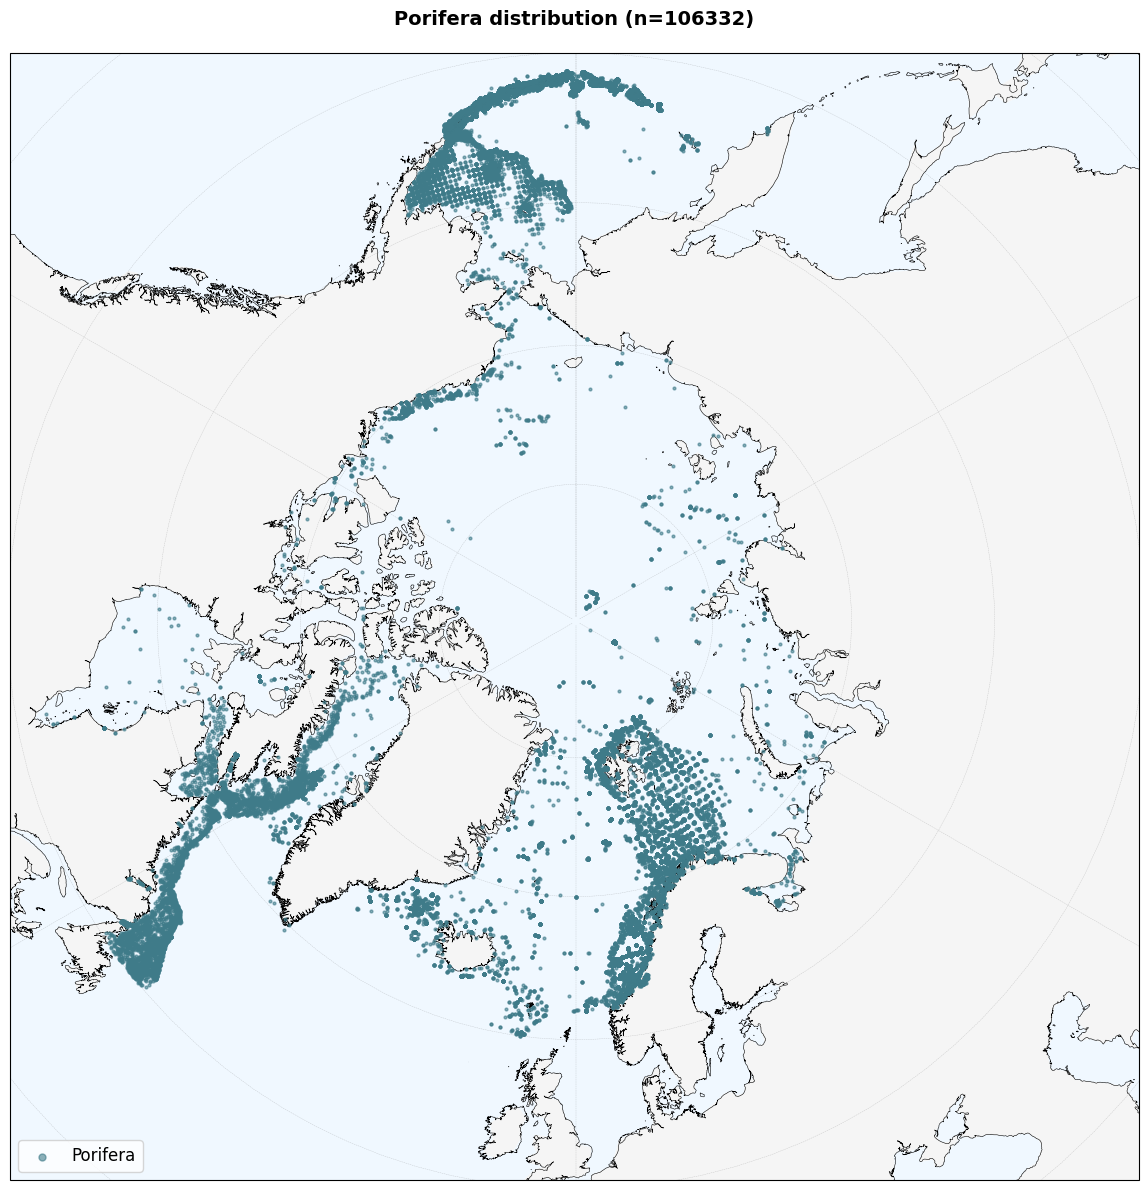

In [30]:
# Load porifera data if not already in memory
if "porifera" not in locals():
    porifera = pd.read_parquet("porifera.parquet")

# Prepare data for plotting
df_map = porifera.copy()
df_map["decimalLatitudeStart"] = pd.to_numeric(df_map["decimalLatitudeStart"], errors="coerce")
df_map["decimalLongitudeStart"] = pd.to_numeric(df_map["decimalLongitudeStart"], errors="coerce")

# Filter to valid coordinates
df_map = df_map[
    df_map["decimalLatitudeStart"].between(-90, 90)
    & df_map["decimalLongitudeStart"].between(-180, 180)
].copy()

# Create the map
fig = plt.figure(figsize=(12, 12))
ax = plt.axes(projection=ccrs.NorthPolarStereo())
ax.set_extent([-180, 180, 50, 90], crs=ccrs.PlateCarree())
ax.add_feature(cfeature.LAND, facecolor="whitesmoke", zorder=0)
ax.add_feature(cfeature.OCEAN, facecolor="aliceblue", zorder=0)
ax.coastlines(resolution="10m", linewidth=0.4, color="black", zorder=1)
ax.gridlines(draw_labels=False, linewidth=0.3, color="gray", alpha=0.4, linestyle="--")

# Plot all Porifera records in one style
ax.scatter(
    df_map["decimalLongitudeStart"].values,
    df_map["decimalLatitudeStart"].values,
    s=4,
    alpha=0.6,
    color="#3F7B89",
    transform=ccrs.PlateCarree(),
    label="Porifera",
    zorder=2,
)

ax.legend(
    loc="lower left",
    frameon=True,
    fontsize=12,
    markerscale=2.5,
)

plt.title(f"Porifera distribution (n={len(df_map)})", fontsize=14, fontweight="bold", pad=20)
plt.tight_layout()
plt.savefig("porifera_distribution_map.png", dpi=300, bbox_inches="tight", facecolor="white")
plt.show()

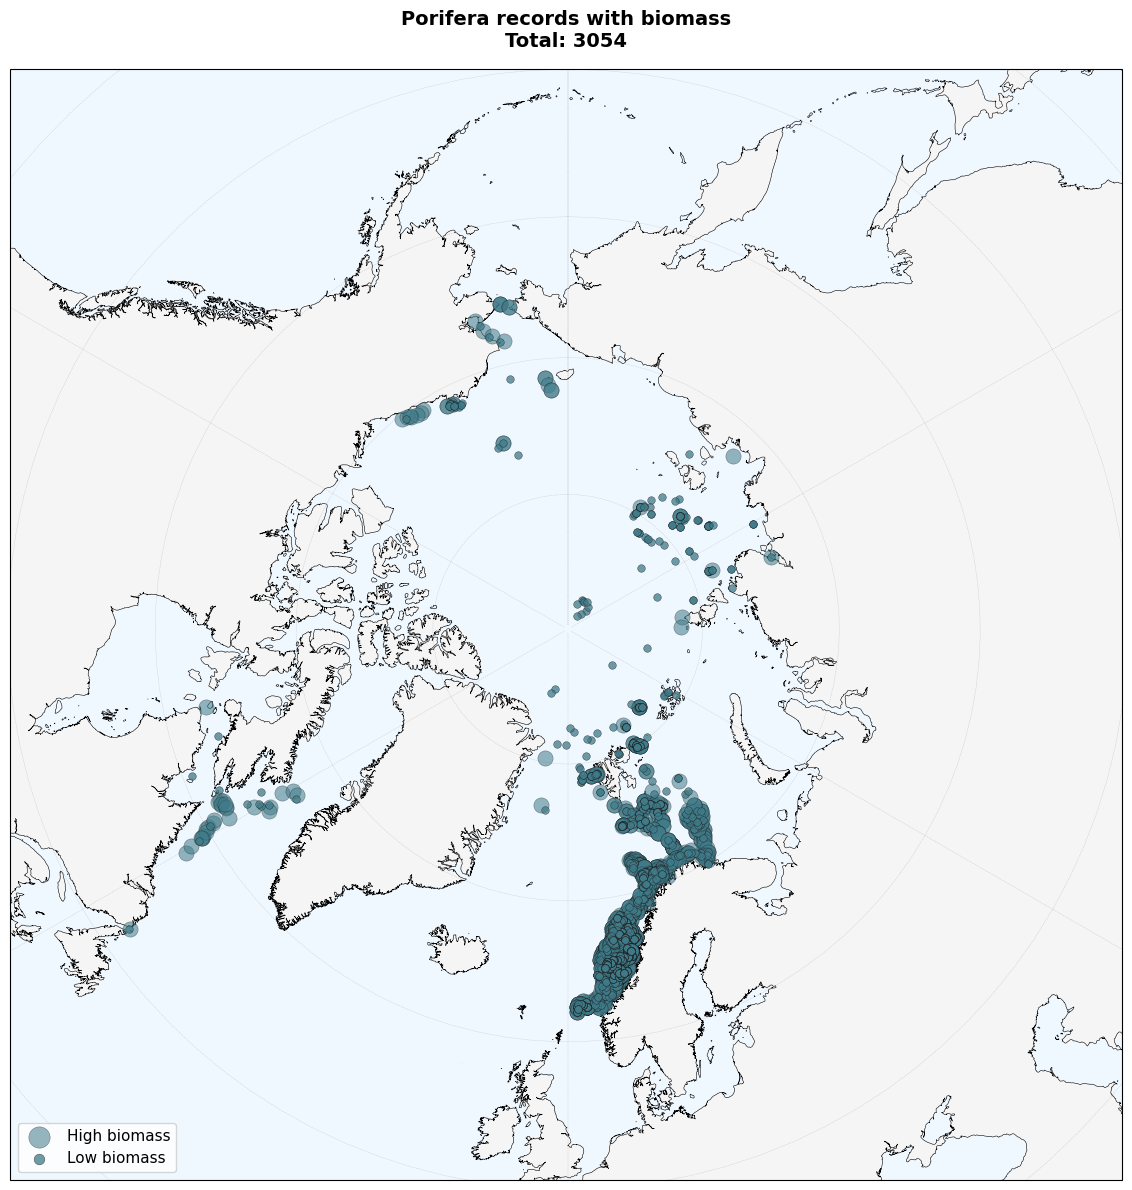

In [33]:
# Map Porifera records with biomass; marker size indicates high/low biomass
if "porifera" not in globals():
    porifera = pd.read_parquet("porifera.parquet")

df_bio = porifera.copy()

# Clean numeric fields
df_bio["decimalLatitudeStart"] = pd.to_numeric(df_bio["decimalLatitudeStart"], errors="coerce")
df_bio["decimalLongitudeStart"] = pd.to_numeric(df_bio["decimalLongitudeStart"], errors="coerce")
df_bio["biomass_num"] = pd.to_numeric(df_bio["biomass"], errors="coerce")

# Keep valid coordinates + rows with biomass
df_bio = df_bio[
    df_bio["decimalLatitudeStart"].between(-90, 90)
    & df_bio["decimalLongitudeStart"].between(-180, 180)
    & df_bio["biomass_num"].notna()
    & (df_bio["biomass_num"] > 0)
].copy()

if df_bio.empty:
    raise ValueError("No Porifera records with valid positive biomass and coordinates.")

# Classify biomass as high/low based on median
biomass_median = df_bio["biomass_num"].median()
df_bio["biomass_category"] = np.where(df_bio["biomass_num"] >= biomass_median, "high", "low")

# Define shared style (no Geodia distinction)
point_color = "#3F7B89"
edge_color = "#1F1F1F"
size_high = 120
size_low = 30

# Plot
fig = plt.figure(figsize=(12, 12))
ax = plt.axes(projection=ccrs.NorthPolarStereo())
ax.set_extent([-180, 180, 50, 90], crs=ccrs.PlateCarree())
ax.add_feature(cfeature.LAND, facecolor="whitesmoke", zorder=0)
ax.add_feature(cfeature.OCEAN, facecolor="aliceblue", zorder=0)
ax.coastlines(resolution="10m", linewidth=0.4, color="black", zorder=1)
ax.gridlines(draw_labels=False, linewidth=0.3, color="gray", alpha=0.4, linestyle="--")

# Plot order: large markers first (so small markers appear on top)
df_high = df_bio[df_bio["biomass_category"] == "high"]
ax.scatter(
    df_high["decimalLongitudeStart"].values,
    df_high["decimalLatitudeStart"].values,
    s=size_high,
    c=point_color,
    alpha=0.55,
    edgecolors=edge_color,
    linewidths=0.35,
    transform=ccrs.PlateCarree(),
    zorder=2,
    label="High biomass",
)

df_low = df_bio[df_bio["biomass_category"] == "low"]
ax.scatter(
    df_low["decimalLongitudeStart"].values,
    df_low["decimalLatitudeStart"].values,
    s=size_low,
    c=point_color,
    alpha=0.75,
    edgecolors=edge_color,
    linewidths=0.35,
    transform=ccrs.PlateCarree(),
    zorder=3,
    label="Low biomass",
)

ax.legend(loc="lower left", frameon=True, fontsize=11, markerscale=1.4)

counts_str = f"Total: {len(df_bio)}"
plt.title(f"Porifera records with biomass\n{counts_str}", fontsize=14, fontweight="bold", pad=16)
plt.tight_layout()
plt.savefig("porifera_biomass_map.png", dpi=300, bbox_inches="tight", facecolor="white")
plt.show()

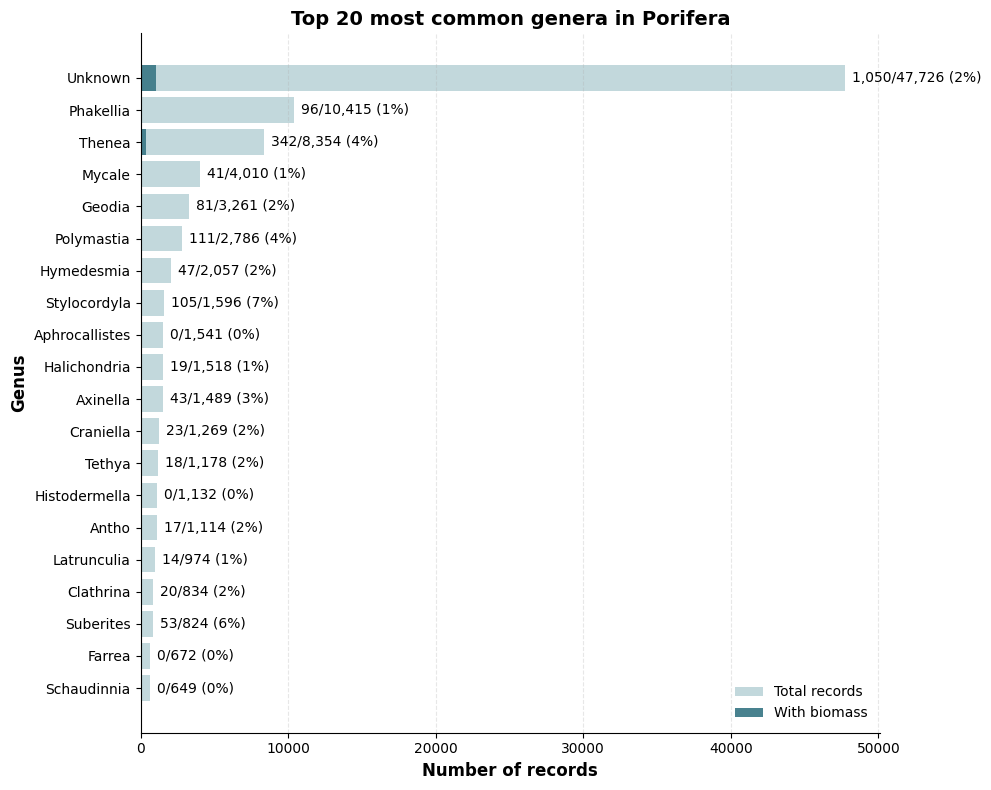

,record_count,biomass_count,biomass_proportion
group,,,
Schaudinnia,649,0,0.0
Farrea,672,0,0.0
Suberites,824,53,0.06432
Clathrina,834,20,0.023981
Latrunculia,974,14,0.014374
Antho,1114,17,0.01526
Histodermella,1132,0,0.0
Tethya,1178,18,0.01528
Craniella,1269,23,0.018125


In [24]:
# Visualize most common genera in Porifera records + biomass coverage within each bar

if "porifera" not in globals():
    porifera = pd.read_parquet("porifera.parquet")

top_n = 20

if "biomass" not in porifera.columns:
    raise KeyError("Column 'biomass' not found in porifera.parquet")

biomass_has = porifera["biomass"].notna() & porifera["biomass"].astype("string").str.strip().ne("")

plot_df = porifera.copy()
plot_df["group"] = (
    plot_df["genus"]
    .astype("string")
    .str.strip()
    .replace("", pd.NA)
    .fillna("Unknown")
)
plot_df["has_biomass"] = biomass_has

genus_stats = (
    plot_df.groupby("group", dropna=False)
    .agg(
        record_count=("group", "size"),
        biomass_count=("has_biomass", "sum"),
    )
    .sort_values("record_count", ascending=False)
    .head(top_n)
    .sort_values("record_count", ascending=True)
)
genus_stats["biomass_proportion"] = genus_stats["biomass_count"] / genus_stats["record_count"]

plt.figure(figsize=(10, 8))
ax = plt.gca()

# Full bar = total records
ax.barh(genus_stats.index, genus_stats["record_count"], color="#BFD6DB", alpha=0.95, label="Total records")
# Colored segment = records with biomass present
ax.barh(genus_stats.index, genus_stats["biomass_count"], color="#3F7B89", alpha=0.95, label="With biomass")

ax.set_xlabel("Number of records", fontsize=12, fontweight="bold")
ax.set_ylabel("Genus", fontsize=12, fontweight="bold")
ax.set_title(f"Top {top_n} most common genera in Porifera", fontsize=14, fontweight="bold")
ax.grid(axis="x", linestyle="--", alpha=0.3)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.legend(loc="lower right", frameon=False, fontsize=10)

max_count = genus_stats["record_count"].max()
for i, (total, bio, prop) in enumerate(zip(genus_stats["record_count"], genus_stats["biomass_count"], genus_stats["biomass_proportion"])):
    ax.text(total + max_count * 0.01, i, f"{bio:,}/{total:,} ({prop:.0%})", va="center", fontsize=10)

plt.tight_layout()
plt.savefig("porifera_top_genera.png", dpi=300, bbox_inches="tight", facecolor="white")
plt.show()

genus_stats[["record_count", "biomass_count", "biomass_proportion"]]

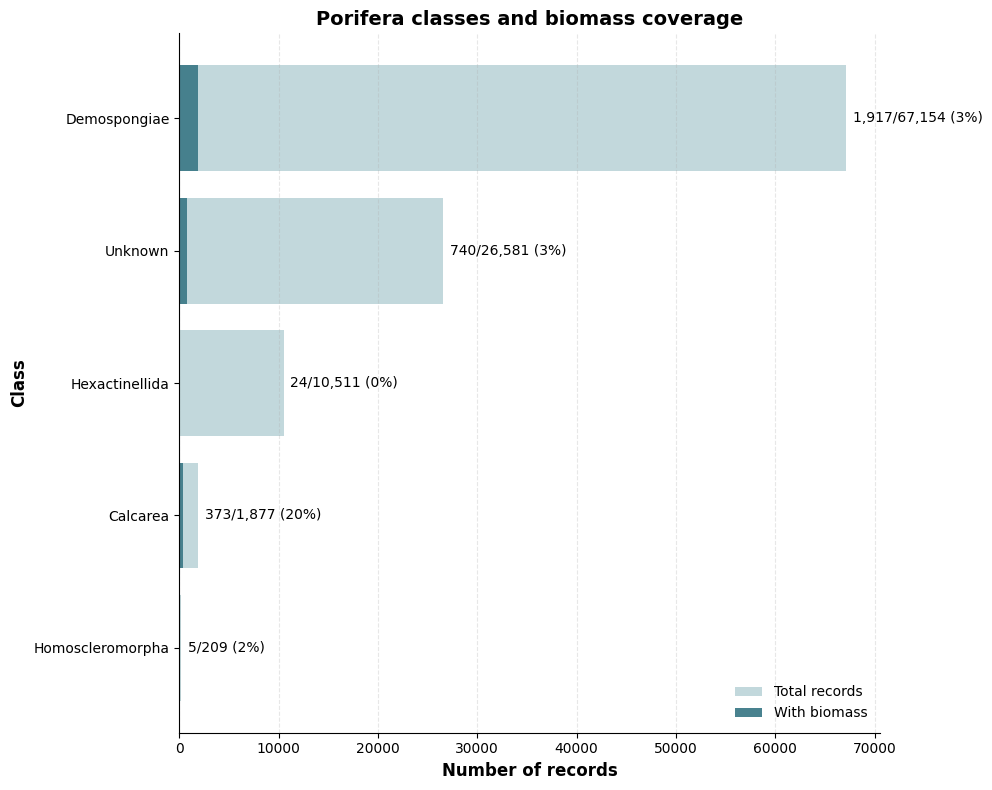

,record_count,biomass_count,biomass_proportion
group,,,
Homoscleromorpha,209,5,0.023923
Calcarea,1877,373,0.198721
Hexactinellida,10511,24,0.002283
Unknown,26581,740,0.027839
Demospongiae,67154,1917,0.028546


In [32]:
# Visualize most common classes in Porifera records + biomass coverage within each bar

if "porifera" not in globals():
    porifera = pd.read_parquet("porifera.parquet")

top_n = 20

if "biomass" not in porifera.columns:
    raise KeyError("Column 'biomass' not found in porifera.parquet")

biomass_has = porifera["biomass"].notna() & porifera["biomass"].astype("string").str.strip().ne("")

plot_df = porifera.copy()
plot_df["group"] = (
    plot_df["class"]
    .astype("string")
    .str.strip()
    .replace("", pd.NA)
    .fillna("Unknown")
)
plot_df["has_biomass"] = biomass_has

class_stats = (
    plot_df.groupby("group", dropna=False)
    .agg(
        record_count=("group", "size"),
        biomass_count=("has_biomass", "sum"),
    )
    .sort_values("record_count", ascending=False)
    .head(top_n)
    .sort_values("record_count", ascending=True)
)
class_stats["biomass_proportion"] = class_stats["biomass_count"] / class_stats["record_count"]

plt.figure(figsize=(10, 8))
ax = plt.gca()

ax.barh(class_stats.index, class_stats["record_count"], color="#BFD6DB", alpha=0.95, label="Total records")
ax.barh(class_stats.index, class_stats["biomass_count"], color="#3F7B89", alpha=0.95, label="With biomass")

ax.set_xlabel("Number of records", fontsize=12, fontweight="bold")
ax.set_ylabel("Class", fontsize=12, fontweight="bold")
ax.set_title(f"Porifera classes and biomass coverage", fontsize=14, fontweight="bold")
ax.grid(axis="x", linestyle="--", alpha=0.3)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.legend(loc="lower right", frameon=False, fontsize=10)

max_count = class_stats["record_count"].max()
for i, (total, bio, prop) in enumerate(zip(class_stats["record_count"], class_stats["biomass_count"], class_stats["biomass_proportion"])):
    ax.text(total + max_count * 0.01, i, f"{bio:,}/{total:,} ({prop:.0%})", va="center", fontsize=10)

plt.tight_layout()
plt.savefig("porifera_top_classes.png", dpi=300, bbox_inches="tight", facecolor="white")
plt.show()

class_stats[["record_count", "biomass_count", "biomass_proportion"]]

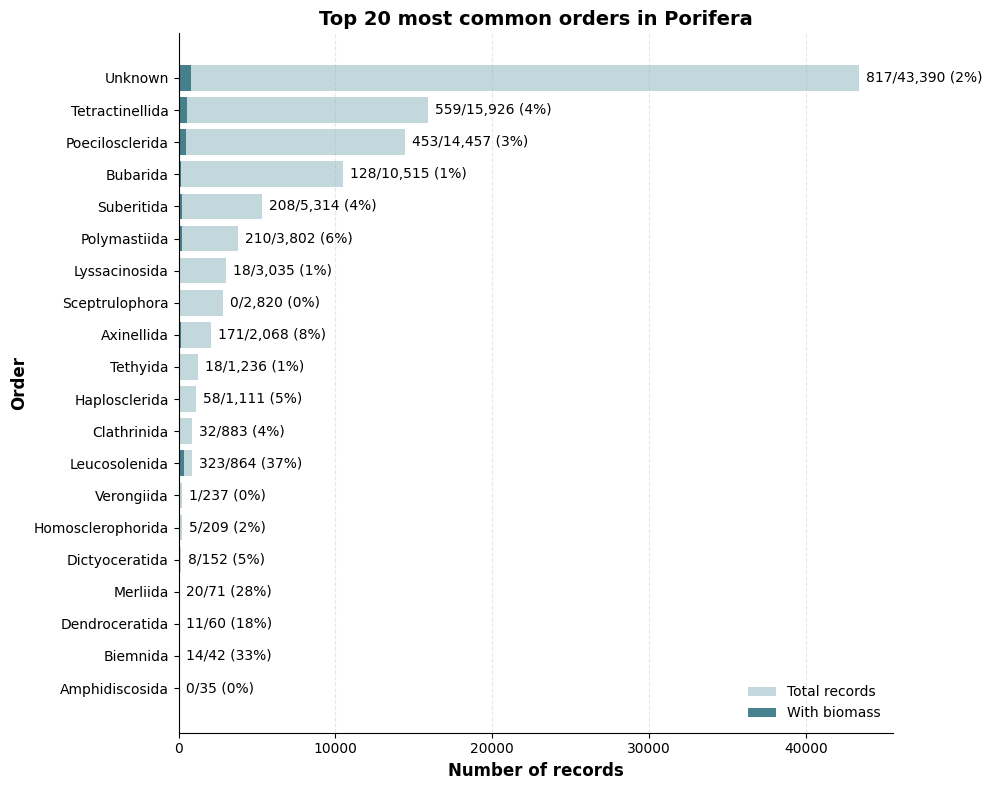

,record_count,biomass_count,biomass_proportion
group,,,
Amphidiscosida,35,0,0.0
Biemnida,42,14,0.333333
Dendroceratida,60,11,0.183333
Merliida,71,20,0.28169
Dictyoceratida,152,8,0.052632
Homosclerophorida,209,5,0.023923
Verongiida,237,1,0.004219
Leucosolenida,864,323,0.373843
Clathrinida,883,32,0.03624


In [26]:
# Visualize most common orders in Porifera records + biomass coverage within each bar

if "porifera" not in globals():
    porifera = pd.read_parquet("porifera.parquet")

top_n = 20

if "biomass" not in porifera.columns:
    raise KeyError("Column 'biomass' not found in porifera.parquet")

biomass_has = porifera["biomass"].notna() & porifera["biomass"].astype("string").str.strip().ne("")

plot_df = porifera.copy()
plot_df["group"] = (
    plot_df["order"]
    .astype("string")
    .str.strip()
    .replace("", pd.NA)
    .fillna("Unknown")
)
plot_df["has_biomass"] = biomass_has

order_stats = (
    plot_df.groupby("group", dropna=False)
    .agg(
        record_count=("group", "size"),
        biomass_count=("has_biomass", "sum"),
    )
    .sort_values("record_count", ascending=False)
    .head(top_n)
    .sort_values("record_count", ascending=True)
)
order_stats["biomass_proportion"] = order_stats["biomass_count"] / order_stats["record_count"]

plt.figure(figsize=(10, 8))
ax = plt.gca()

ax.barh(order_stats.index, order_stats["record_count"], color="#BFD6DB", alpha=0.95, label="Total records")
ax.barh(order_stats.index, order_stats["biomass_count"], color="#3F7B89", alpha=0.95, label="With biomass")

ax.set_xlabel("Number of records", fontsize=12, fontweight="bold")
ax.set_ylabel("Order", fontsize=12, fontweight="bold")
ax.set_title(f"Top {top_n} most common orders in Porifera", fontsize=14, fontweight="bold")
ax.grid(axis="x", linestyle="--", alpha=0.3)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.legend(loc="lower right", frameon=False, fontsize=10)

max_count = order_stats["record_count"].max()
for i, (total, bio, prop) in enumerate(zip(order_stats["record_count"], order_stats["biomass_count"], order_stats["biomass_proportion"])):
    ax.text(total + max_count * 0.01, i, f"{bio:,}/{total:,} ({prop:.0%})", va="center", fontsize=10)

plt.tight_layout()
plt.savefig("porifera_top_orders.png", dpi=300, bbox_inches="tight", facecolor="white")
plt.show()

order_stats[["record_count", "biomass_count", "biomass_proportion"]]

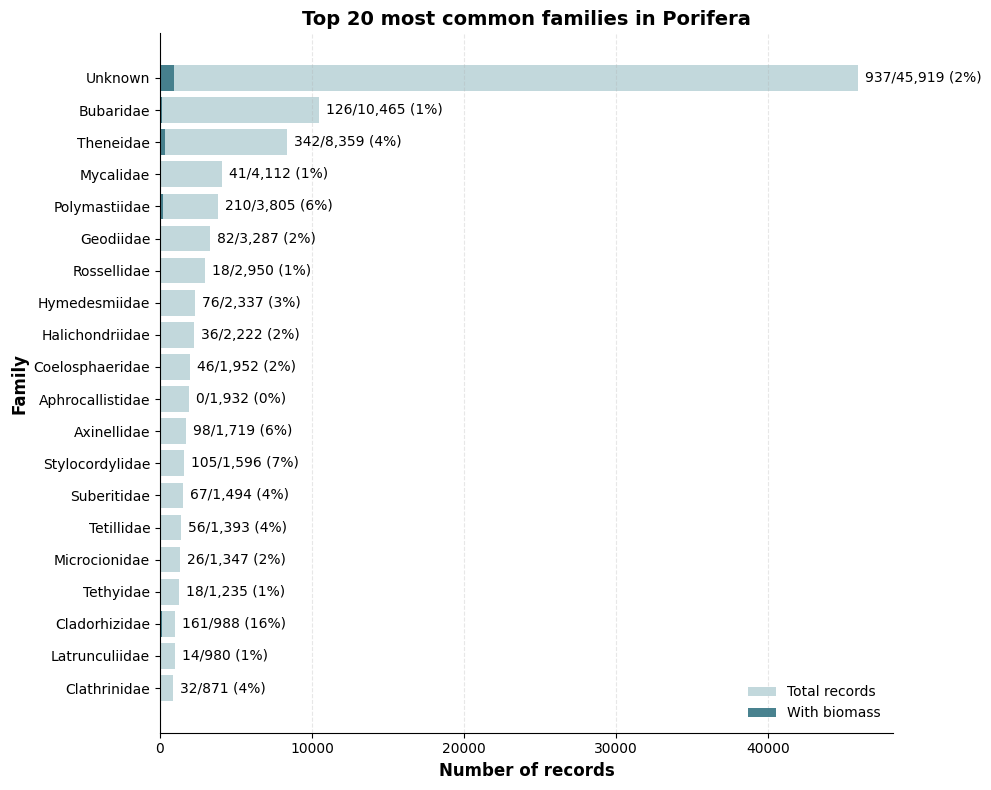

,record_count,biomass_count,biomass_proportion
group,,,
Clathrinidae,871,32,0.036739
Latrunculiidae,980,14,0.014286
Cladorhizidae,988,161,0.162955
Tethyidae,1235,18,0.014575
Microcionidae,1347,26,0.019302
Tetillidae,1393,56,0.040201
Suberitidae,1494,67,0.044846
Stylocordylidae,1596,105,0.065789
Axinellidae,1719,98,0.05701


In [27]:
# Visualize most common families in Porifera records + biomass coverage within each bar

if "porifera" not in globals():
    porifera = pd.read_parquet("porifera.parquet")

top_n = 20

if "biomass" not in porifera.columns:
    raise KeyError("Column 'biomass' not found in porifera.parquet")

biomass_has = porifera["biomass"].notna() & porifera["biomass"].astype("string").str.strip().ne("")

plot_df = porifera.copy()
plot_df["group"] = (
    plot_df["family"]
    .astype("string")
    .str.strip()
    .replace("", pd.NA)
    .fillna("Unknown")
)
plot_df["has_biomass"] = biomass_has

family_stats = (
    plot_df.groupby("group", dropna=False)
    .agg(
        record_count=("group", "size"),
        biomass_count=("has_biomass", "sum"),
    )
    .sort_values("record_count", ascending=False)
    .head(top_n)
    .sort_values("record_count", ascending=True)
)
family_stats["biomass_proportion"] = family_stats["biomass_count"] / family_stats["record_count"]

plt.figure(figsize=(10, 8))
ax = plt.gca()

ax.barh(family_stats.index, family_stats["record_count"], color="#BFD6DB", alpha=0.95, label="Total records")
ax.barh(family_stats.index, family_stats["biomass_count"], color="#3F7B89", alpha=0.95, label="With biomass")

ax.set_xlabel("Number of records", fontsize=12, fontweight="bold")
ax.set_ylabel("Family", fontsize=12, fontweight="bold")
ax.set_title(f"Top {top_n} most common families in Porifera", fontsize=14, fontweight="bold")
ax.grid(axis="x", linestyle="--", alpha=0.3)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.legend(loc="lower right", frameon=False, fontsize=10)

max_count = family_stats["record_count"].max()
for i, (total, bio, prop) in enumerate(zip(family_stats["record_count"], family_stats["biomass_count"], family_stats["biomass_proportion"])):
    ax.text(total + max_count * 0.01, i, f"{bio:,}/{total:,} ({prop:.0%})", va="center", fontsize=10)

plt.tight_layout()
plt.savefig("porifera_top_families.png", dpi=300, bbox_inches="tight", facecolor="white")
plt.show()

family_stats[["record_count", "biomass_count", "biomass_proportion"]]

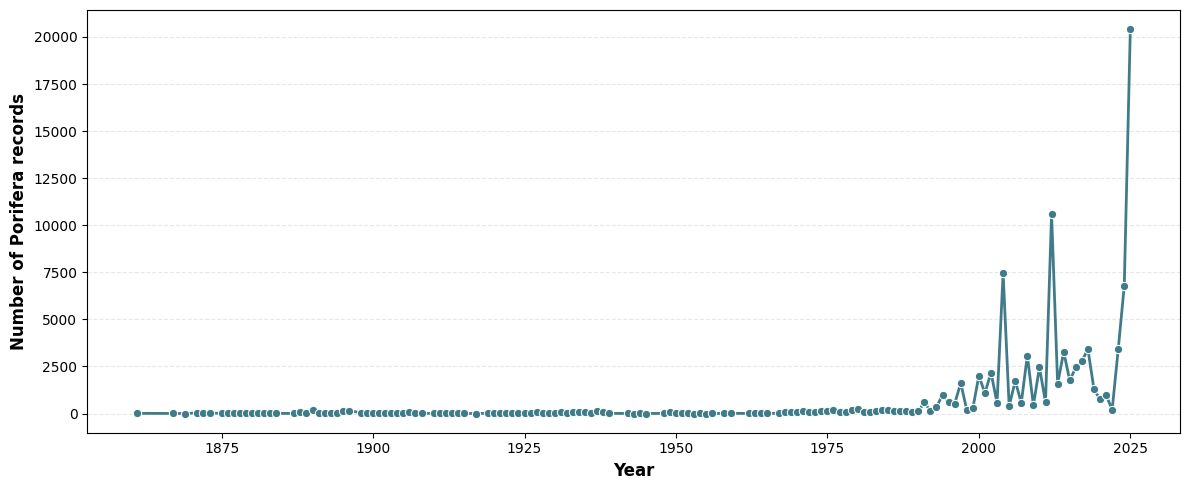

,year,record_count
0,1861,11
1,1867,2
2,1869,1
3,1871,35
4,1872,5
...,...,...
138,2021,996
139,2022,195
140,2023,3410
141,2024,6778


In [35]:
# Timeline: number of Porifera records per year
if "porifera" not in globals():
    porifera = pd.read_parquet("porifera.parquet")

porifera_timeline = (
    porifera.assign(year=pd.to_numeric(porifera["year"], errors="coerce"))
    .dropna(subset=["year"])
    .assign(year=lambda d: d["year"].astype(int))
    .groupby("year")
    .size()
    .reset_index(name="record_count")
    .sort_values("year")
)

plt.figure(figsize=(12, 5))
sns.lineplot(data=porifera_timeline, x="year", y="record_count", marker="o", color="#3F7B89", linewidth=2)
plt.xlabel("Year", fontsize=12, fontweight="bold")
plt.ylabel("Number of Porifera records", fontsize=12, fontweight="bold")
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.savefig("porifera_records_timeline.png", dpi=300, bbox_inches="tight", facecolor="white")
plt.show()

porifera_timeline

# VME Cnidaria

In [37]:
# Remove selected Cnidaria orders
excluded_orders = {
    "Coronatae",
    "Limnomedusae",
    "Trachymedusae",
    "Semaeostomeae",
}

# Load cnidaria if not already in memory
if "cnidaria" not in globals():
    if os.path.exists("cnidaria.parquet"):
        cnidaria = pd.read_parquet("cnidaria.parquet")
    else:
        src = pd.read_parquet("all_merged_geo_LME.parquet")
        cnidaria = src[src["phylum"] == "Cnidaria"].copy()

before_n = len(cnidaria)

mask_excluded = cnidaria["order"].astype("string").str.strip().isin(excluded_orders)
cnidaria = cnidaria.loc[~mask_excluded].copy()

after_n = len(cnidaria)
removed_n = before_n - after_n

# Save filtered dataset
cnidaria.to_parquet("cnidaria.parquet", index=False)

print(f"Removed records: {removed_n:,}")
print(f"Remaining Cnidaria records: {after_n:,}")

Removed records: 199
Remaining Cnidaria records: 105,666


Cnidaria records: 105,666
Saved: column_coverage_cnidaria.csv


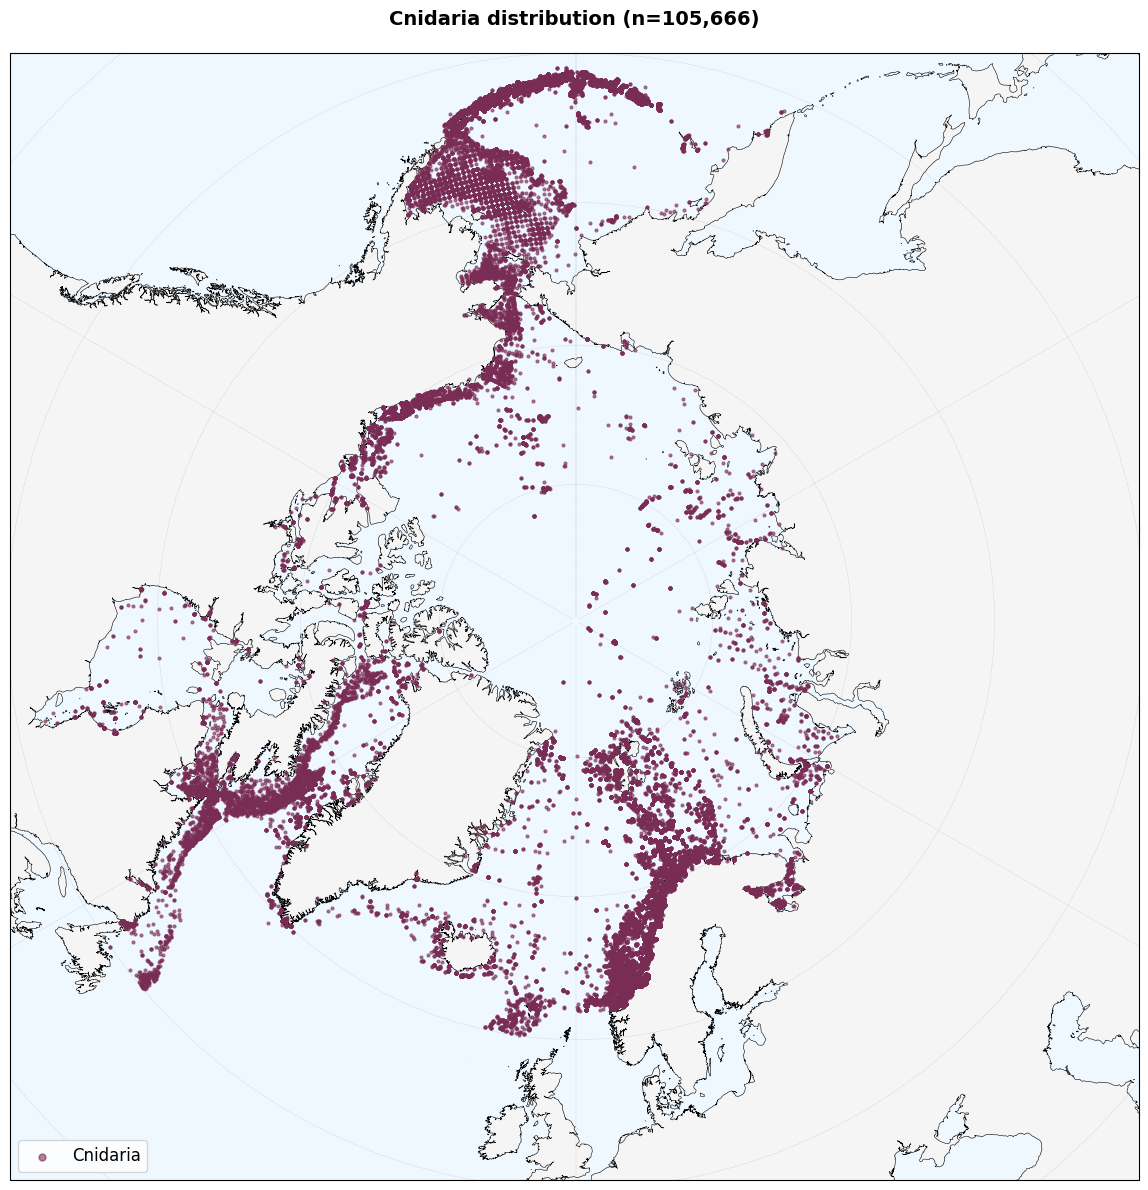

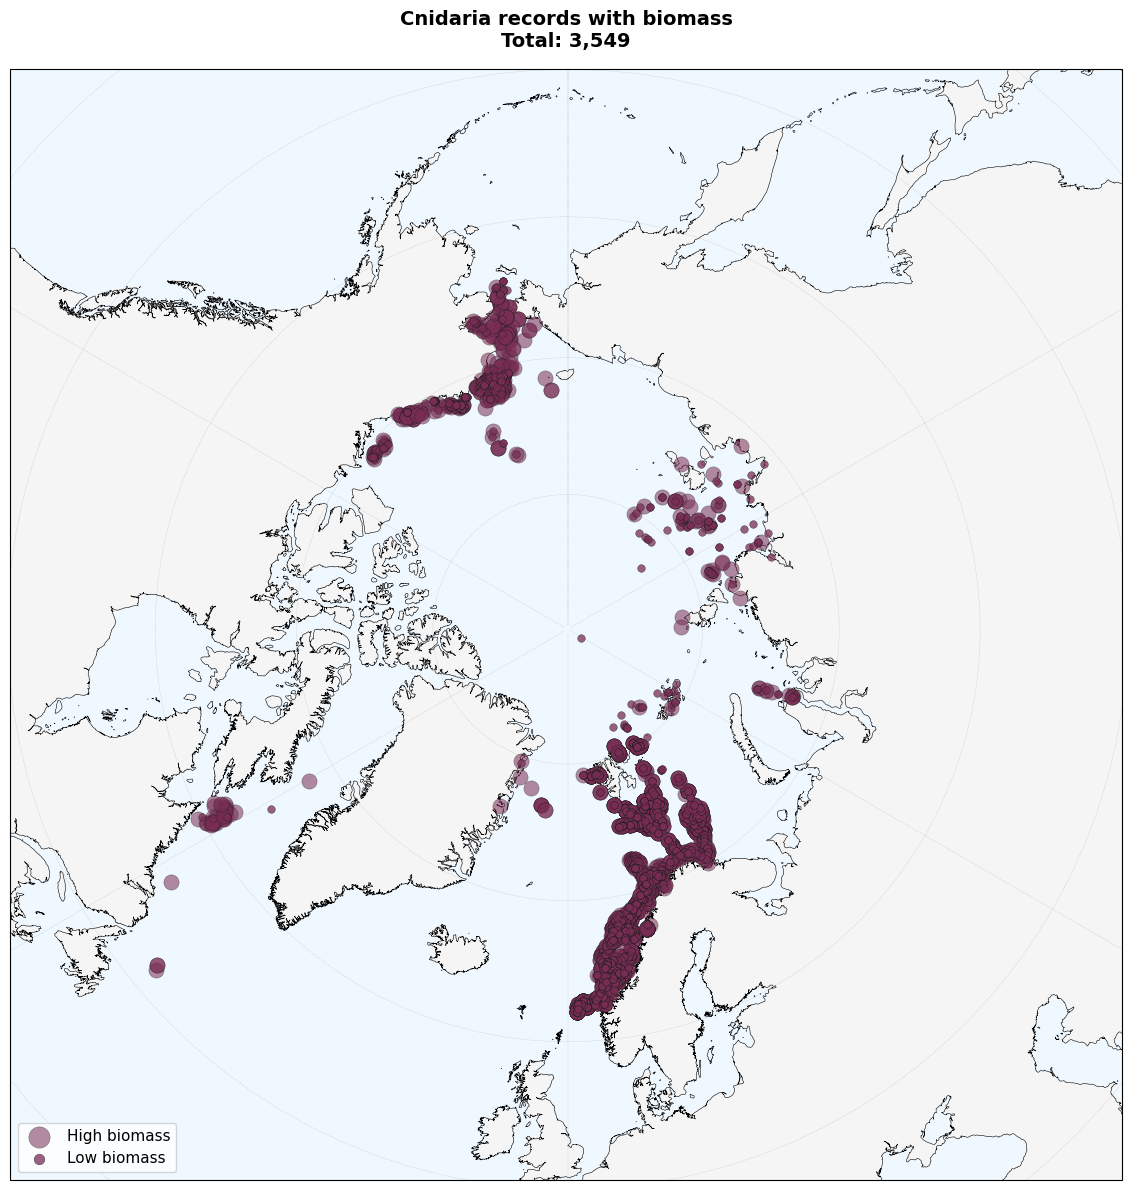

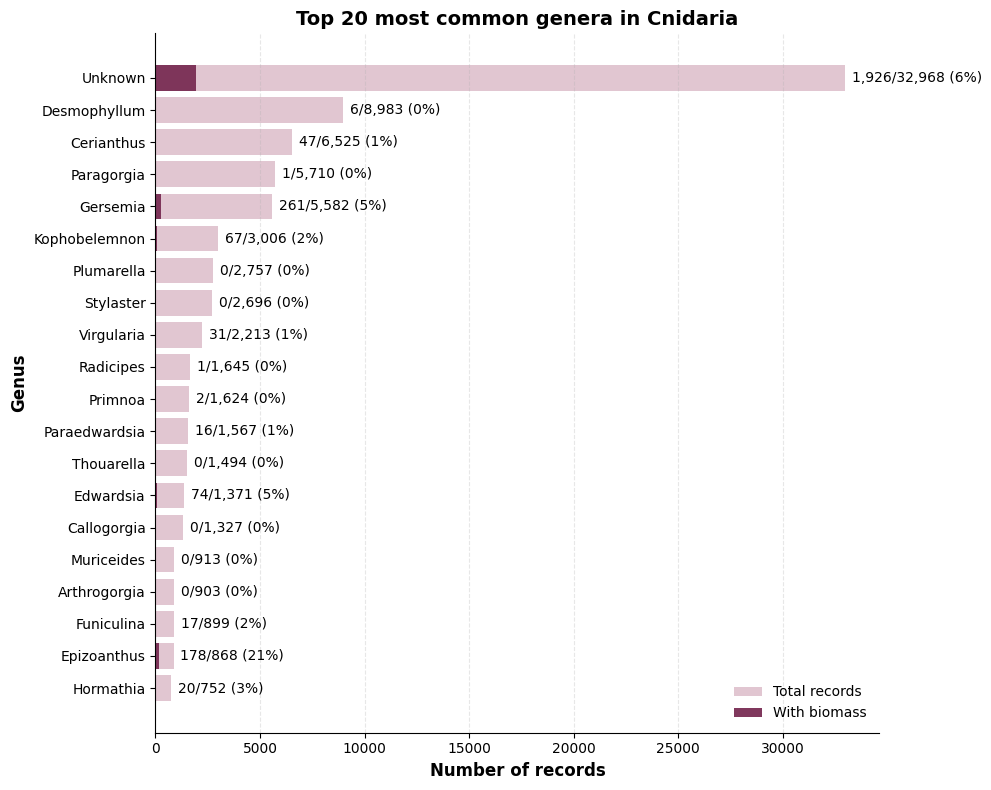

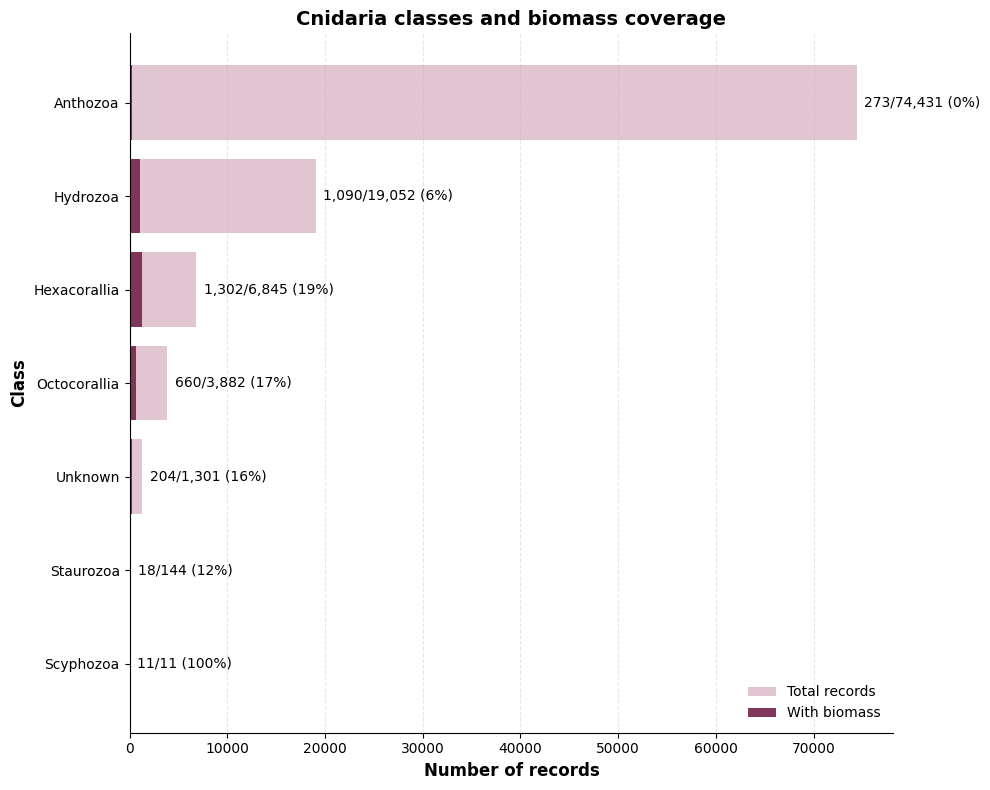

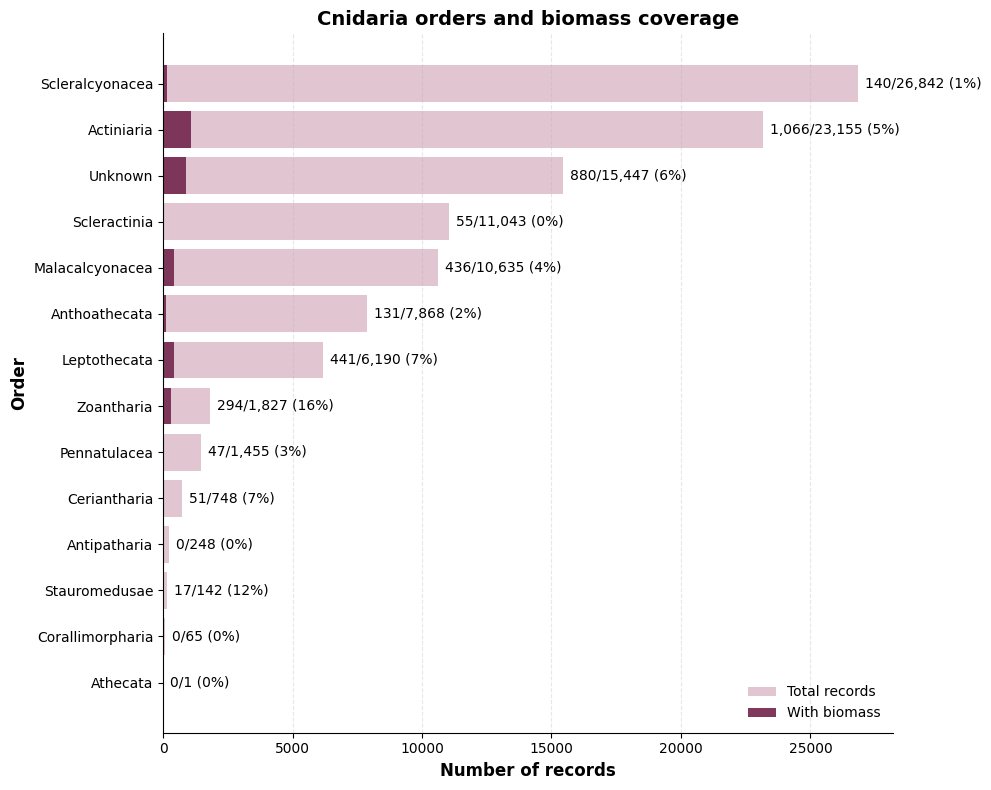

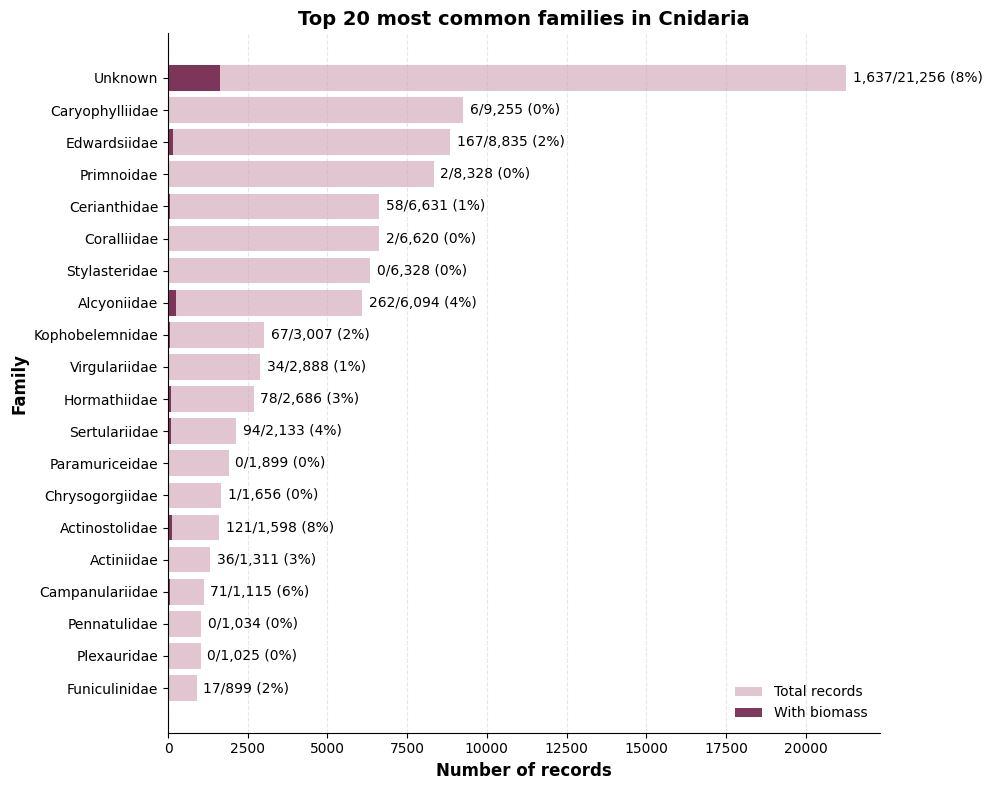

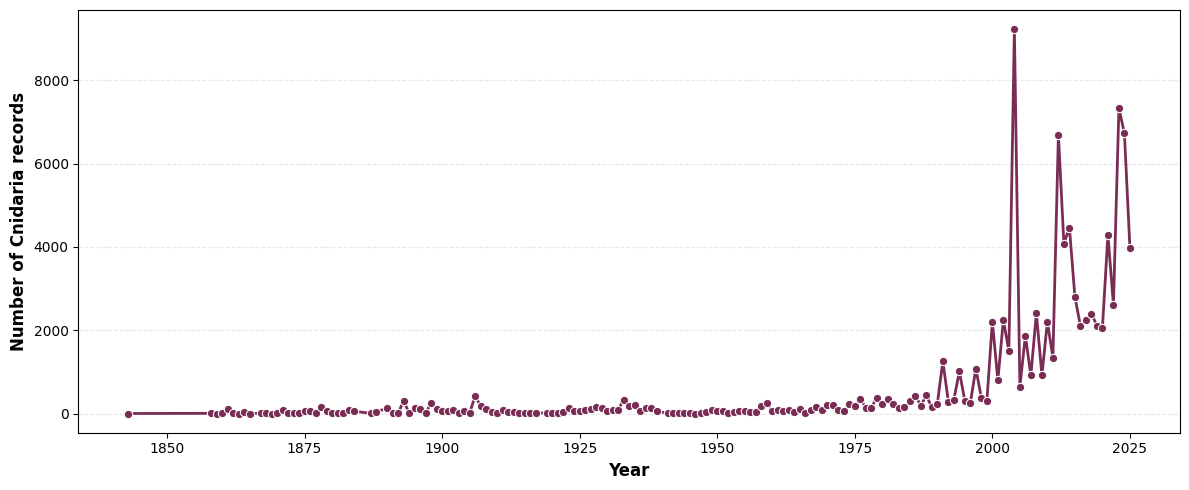

,year,record_count
0,1843,1
1,1858,5
2,1859,1
3,1860,3
4,1861,108
...,...,...
158,2021,4295
159,2022,2616
160,2023,7332
161,2024,6725


In [39]:
# Cnidaria workflow (analogous to cells 49–57)

# 0) Load or build cnidaria dataset
cnidaria_path = "cnidaria.parquet"
if os.path.exists(cnidaria_path):
    cnidaria = pd.read_parquet(cnidaria_path)
else:
    src = pd.read_parquet("all_merged_geo_LME.parquet")
    cnidaria = src[src["phylum"] == "Cnidaria"].copy()
    cnidaria.to_parquet(cnidaria_path, index=False)

print(f"Cnidaria records: {len(cnidaria):,}")

# 1) Column coverage (like cell 49)
total_rows = len(cnidaria)

def non_missing_mask(s):
    m = s.notna()
    if pd.api.types.is_object_dtype(s) or pd.api.types.is_string_dtype(s):
        m &= s.astype("string").str.strip().ne("")
    return m

coverage_cnidaria = pd.DataFrame({
    "column": cnidaria.columns,
    "non_missing": [non_missing_mask(cnidaria[c]).sum() for c in cnidaria.columns],
})
coverage_cnidaria["total_rows"] = total_rows
coverage_cnidaria["coverage_percent"] = (coverage_cnidaria["non_missing"] / total_rows * 100).round(2)
coverage_cnidaria = coverage_cnidaria.sort_values("coverage_percent", ascending=False).reset_index(drop=True)
coverage_cnidaria.to_csv("column_coverage_cnidaria.csv", index=False)
print("Saved: column_coverage_cnidaria.csv")

# 2) Distribution map (like cell 50)
cn_map = cnidaria.copy()
cn_map["decimalLatitudeStart"] = pd.to_numeric(cn_map["decimalLatitudeStart"], errors="coerce")
cn_map["decimalLongitudeStart"] = pd.to_numeric(cn_map["decimalLongitudeStart"], errors="coerce")
cn_map = cn_map[
    cn_map["decimalLatitudeStart"].between(-90, 90)
    & cn_map["decimalLongitudeStart"].between(-180, 180)
].copy()

fig = plt.figure(figsize=(12, 12))
ax = plt.axes(projection=ccrs.NorthPolarStereo())
ax.set_extent([-180, 180, 50, 90], crs=ccrs.PlateCarree())
ax.add_feature(cfeature.LAND, facecolor="whitesmoke", zorder=0)
ax.add_feature(cfeature.OCEAN, facecolor="aliceblue", zorder=0)
ax.coastlines(resolution="10m", linewidth=0.4, color="black", zorder=1)
ax.gridlines(draw_labels=False, linewidth=0.3, color="gray", alpha=0.4, linestyle="--")

ax.scatter(
    cn_map["decimalLongitudeStart"].values,
    cn_map["decimalLatitudeStart"].values,
    s=4,
    alpha=0.6,
    color="#792D54",
    transform=ccrs.PlateCarree(),
    label="Cnidaria",
    zorder=2,
)
ax.legend(loc="lower left", frameon=True, fontsize=12, markerscale=2.5)
plt.title(f"Cnidaria distribution (n={len(cn_map):,})", fontsize=14, fontweight="bold", pad=20)
plt.tight_layout()
plt.savefig("cnidaria_distribution_map.png", dpi=300, bbox_inches="tight", facecolor="white")
plt.show()

# 3) Biomass map (like cell 51)
cn_bio = cnidaria.copy()
cn_bio["decimalLatitudeStart"] = pd.to_numeric(cn_bio["decimalLatitudeStart"], errors="coerce")
cn_bio["decimalLongitudeStart"] = pd.to_numeric(cn_bio["decimalLongitudeStart"], errors="coerce")
cn_bio["biomass_num"] = pd.to_numeric(cn_bio["biomass"], errors="coerce")
cn_bio = cn_bio[
    cn_bio["decimalLatitudeStart"].between(-90, 90)
    & cn_bio["decimalLongitudeStart"].between(-180, 180)
    & cn_bio["biomass_num"].notna()
    & (cn_bio["biomass_num"] > 0)
].copy()

if not cn_bio.empty:
    med = cn_bio["biomass_num"].median()
    cn_bio["biomass_category"] = np.where(cn_bio["biomass_num"] >= med, "high", "low")

    fig = plt.figure(figsize=(12, 12))
    ax = plt.axes(projection=ccrs.NorthPolarStereo())
    ax.set_extent([-180, 180, 50, 90], crs=ccrs.PlateCarree())
    ax.add_feature(cfeature.LAND, facecolor="whitesmoke", zorder=0)
    ax.add_feature(cfeature.OCEAN, facecolor="aliceblue", zorder=0)
    ax.coastlines(resolution="10m", linewidth=0.4, color="black", zorder=1)
    ax.gridlines(draw_labels=False, linewidth=0.3, color="gray", alpha=0.4, linestyle="--")

    high = cn_bio[cn_bio["biomass_category"] == "high"]
    low = cn_bio[cn_bio["biomass_category"] == "low"]

    ax.scatter(high["decimalLongitudeStart"], high["decimalLatitudeStart"], s=120, c="#792D54",
               alpha=0.55, edgecolors=edge_color, linewidths=0.35,
               transform=ccrs.PlateCarree(), zorder=2, label="High biomass")
    ax.scatter(low["decimalLongitudeStart"], low["decimalLatitudeStart"], s=30, c="#792D54",
               alpha=0.75, edgecolors=edge_color, linewidths=0.35,
               transform=ccrs.PlateCarree(), zorder=3, label="Low biomass")

    ax.legend(loc="lower left", frameon=True, fontsize=11, markerscale=1.4)
    plt.title(f"Cnidaria records with biomass\nTotal: {len(cn_bio):,}", fontsize=14, fontweight="bold", pad=16)
    plt.tight_layout()
    plt.savefig("cnidaria_biomass_map.png", dpi=300, bbox_inches="tight", facecolor="white")
    plt.show()
else:
    print("No Cnidaria records with valid positive biomass for biomass map.")

# 4) Top taxa + biomass overlay (like cells 52–55)
def plot_top_taxa(df, rank_col, out_png, ylab, title, top_n=20):
    biomass_has = df["biomass"].notna() & df["biomass"].astype("string").str.strip().ne("")
    tmp = df.copy()
    tmp["group"] = tmp[rank_col].astype("string").str.strip().replace("", pd.NA).fillna("Unknown")
    tmp["has_biomass"] = biomass_has

    stats = (
        tmp.groupby("group", dropna=False)
        .agg(record_count=("group", "size"), biomass_count=("has_biomass", "sum"))
        .sort_values("record_count", ascending=False)
        .head(top_n)
        .sort_values("record_count", ascending=True)
    )
    stats["biomass_proportion"] = stats["biomass_count"] / stats["record_count"]

    plt.figure(figsize=(10, 8))
    ax = plt.gca()
    ax.barh(stats.index, stats["record_count"], color="#E0C3CF", alpha=0.95, label="Total records")
    ax.barh(stats.index, stats["biomass_count"], color="#792D54", alpha=0.95, label="With biomass")
    ax.set_xlabel("Number of records", fontsize=12, fontweight="bold")
    ax.set_ylabel(ylab, fontsize=12, fontweight="bold")
    ax.set_title(title, fontsize=14, fontweight="bold")
    ax.grid(axis="x", linestyle="--", alpha=0.3)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.legend(loc="lower right", frameon=False, fontsize=10)

    max_count_local = stats["record_count"].max()
    for idx, (tot, bio, pr) in enumerate(zip(stats["record_count"], stats["biomass_count"], stats["biomass_proportion"])):
        ax.text(tot + max_count_local * 0.01, idx, f"{bio:,}/{tot:,} ({pr:.0%})", va="center", fontsize=10)

    plt.tight_layout()
    plt.savefig(out_png, dpi=300, bbox_inches="tight", facecolor="white")
    plt.show()
    return stats

cn_genus_stats = plot_top_taxa(cnidaria, "genus", "cnidaria_top_genera.png", "Genus", "Top 20 most common genera in Cnidaria")
cn_class_stats = plot_top_taxa(cnidaria, "class", "cnidaria_top_classes.png", "Class", "Cnidaria classes and biomass coverage")
cn_order_stats = plot_top_taxa(cnidaria, "order", "cnidaria_top_orders.png", "Order", "Cnidaria orders and biomass coverage")
cn_family_stats = plot_top_taxa(cnidaria, "family", "cnidaria_top_families.png", "Family", "Top 20 most common families in Cnidaria")

# 5) Timeline (like cell 56)
cnidaria_timeline = (
    cnidaria.assign(year=pd.to_numeric(cnidaria["year"], errors="coerce"))
    .dropna(subset=["year"])
    .assign(year=lambda d: d["year"].astype(int))
    .groupby("year")
    .size()
    .reset_index(name="record_count")
    .sort_values("year")
)

plt.figure(figsize=(12, 5))
sns.lineplot(data=cnidaria_timeline, x="year", y="record_count", marker="o", color="#792D54", linewidth=2)
plt.xlabel("Year", fontsize=12, fontweight="bold")
plt.ylabel("Number of Cnidaria records", fontsize=12, fontweight="bold")
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.savefig("cnidaria_records_timeline.png", dpi=300, bbox_inches="tight", facecolor="white")
plt.show()

cnidaria_timeline

# Siboglinids

Siboglinidae records: 5,963


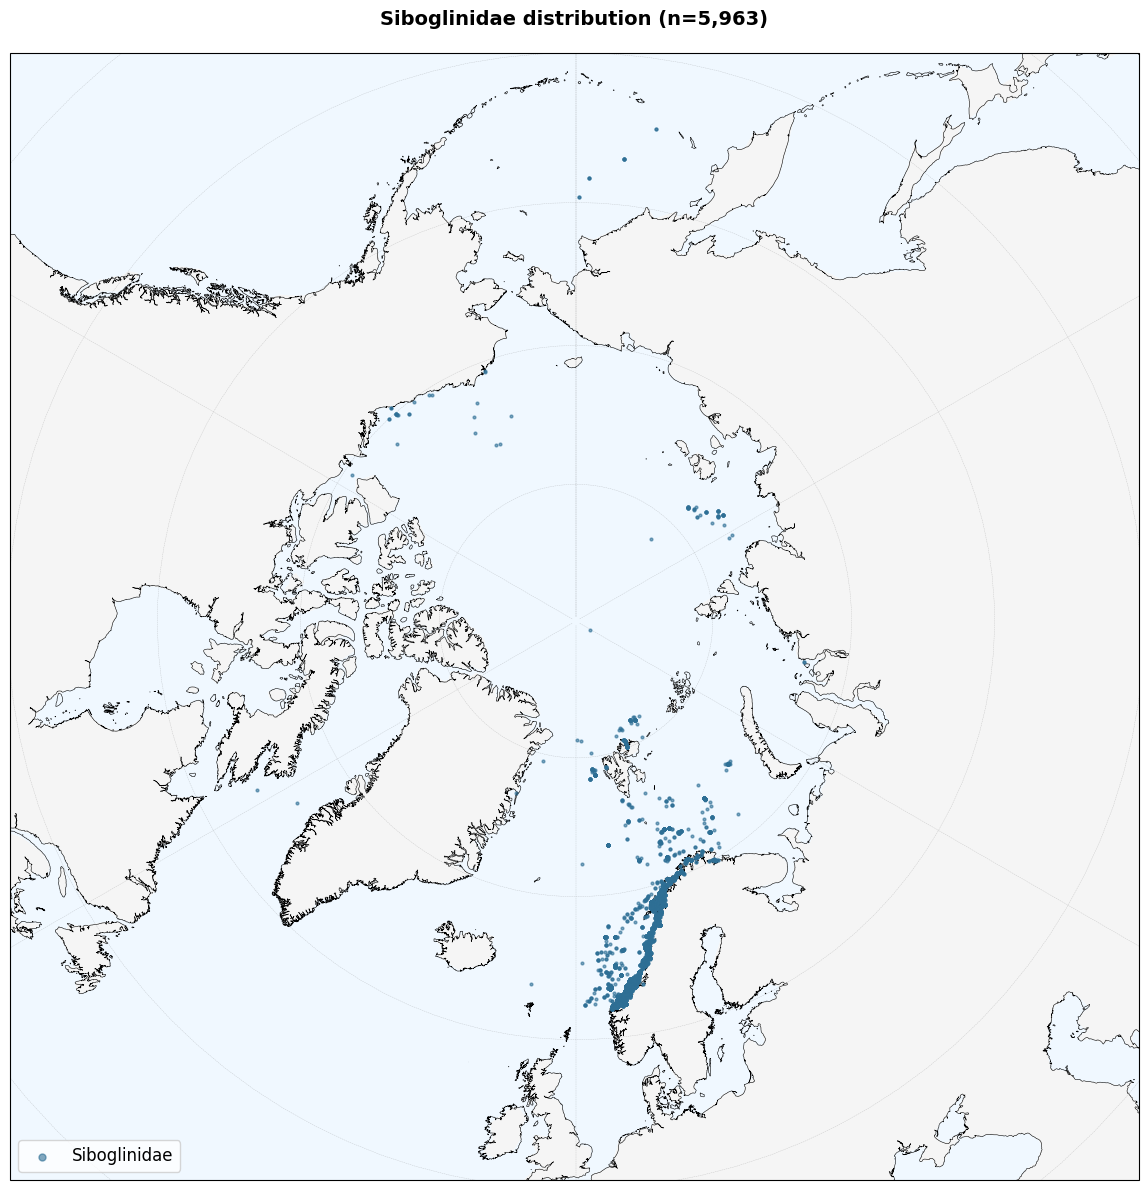

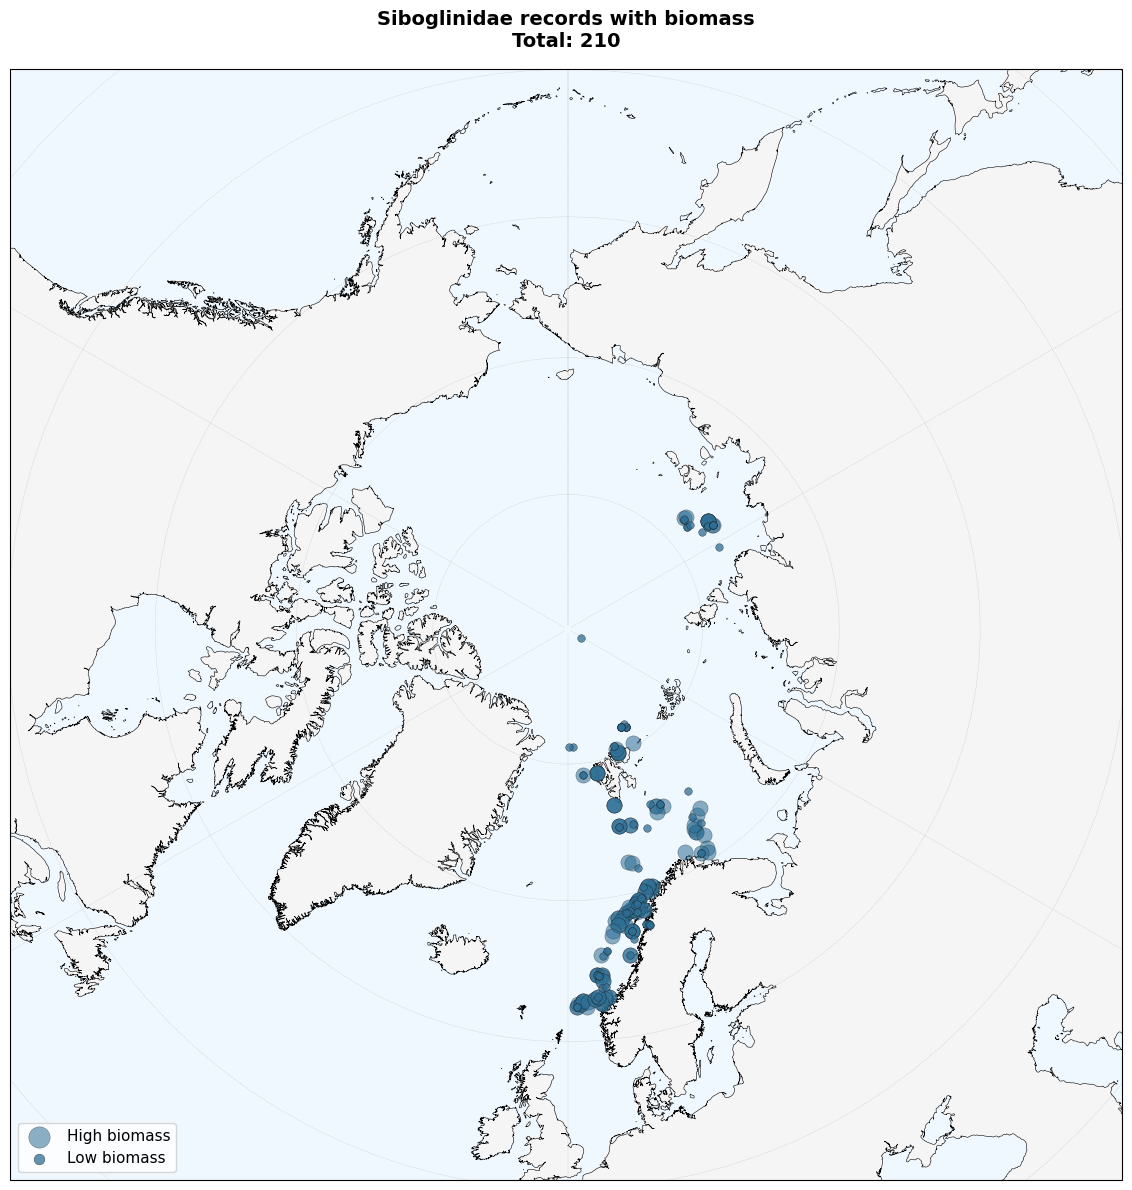

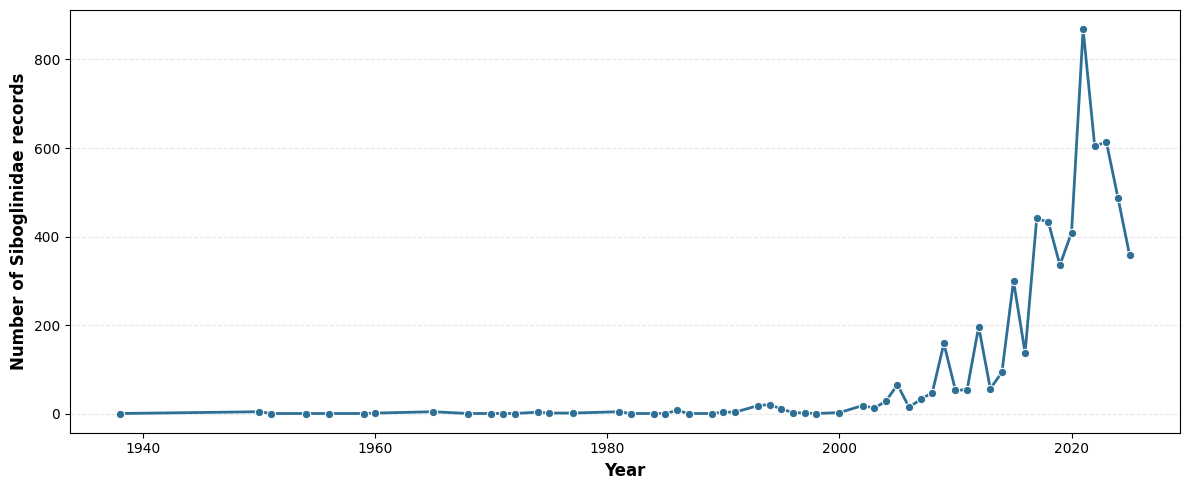

,year,record_count
0,1938,1
1,1950,5
2,1951,1
3,1954,1
4,1956,1
5,1959,1
6,1960,2
7,1965,5
8,1968,1
9,1970,1


In [48]:
# Siboglinidae maps: distribution + biomass (high/low by median)

# 1) Build/load Siboglinidae subset
if "src" in globals():
    base_df = src
elif "all_merged_geo_lme" in globals():
    base_df = all_merged_geo_lme
else:
    base_df = pd.read_parquet("all_merged_geo_LME.parquet")

siboglinidae = base_df[
    base_df["family"].astype("string").str.strip().str.lower() == "siboglinidae"
] .copy()

siboglinidae.to_parquet("siboglinidae.parquet", index=False)
print(f"Siboglinidae records: {len(siboglinidae):,}")

if siboglinidae.empty:
    raise ValueError("No records found where family == 'Siboglinidae'.")

# 2) Distribution map
df_map = siboglinidae.copy()
df_map["decimalLatitudeStart"] = pd.to_numeric(df_map["decimalLatitudeStart"], errors="coerce")
df_map["decimalLongitudeStart"] = pd.to_numeric(df_map["decimalLongitudeStart"], errors="coerce")
df_map = df_map[
    df_map["decimalLatitudeStart"].between(-90, 90)
    & df_map["decimalLongitudeStart"].between(-180, 180)
] .copy()

fig = plt.figure(figsize=(12, 12))
ax = plt.axes(projection=ccrs.NorthPolarStereo())
ax.set_extent([-180, 180, 50, 90], crs=ccrs.PlateCarree())
ax.add_feature(cfeature.LAND, facecolor="whitesmoke", zorder=0)
ax.add_feature(cfeature.OCEAN, facecolor="aliceblue", zorder=0)
ax.coastlines(resolution="10m", linewidth=0.4, color="black", zorder=1)
ax.gridlines(draw_labels=False, linewidth=0.3, color="gray", alpha=0.4, linestyle="--")

ax.scatter(
    df_map["decimalLongitudeStart"].values,
    df_map["decimalLatitudeStart"].values,
    s=4,
    alpha=0.6,
    color="#2E6F95",
    transform=ccrs.PlateCarree(),
    label="Siboglinidae",
    zorder=2,
)

ax.legend(loc="lower left", frameon=True, fontsize=12, markerscale=2.5)
plt.title(f"Siboglinidae distribution (n={len(df_map):,})", fontsize=14, fontweight="bold", pad=20)
plt.tight_layout()
plt.savefig("siboglinidae_distribution_map.png", dpi=300, bbox_inches="tight", facecolor="white")
plt.show()

# 3) Biomass map (high/low from median biomass)
df_bio = siboglinidae.copy()
df_bio["decimalLatitudeStart"] = pd.to_numeric(df_bio["decimalLatitudeStart"], errors="coerce")
df_bio["decimalLongitudeStart"] = pd.to_numeric(df_bio["decimalLongitudeStart"], errors="coerce")
df_bio["biomass_num"] = pd.to_numeric(df_bio["biomass"], errors="coerce")

df_bio = df_bio[
    df_bio["decimalLatitudeStart"].between(-90, 90)
    & df_bio["decimalLongitudeStart"].between(-180, 180)
    & df_bio["biomass_num"].notna()
    & (df_bio["biomass_num"] > 0)
] .copy()

if df_bio.empty:
    print("No Siboglinidae records with valid positive biomass for biomass map.")
else:
    biomass_median = df_bio["biomass_num"].median()
    df_bio["biomass_category"] = np.where(df_bio["biomass_num"] >= biomass_median, "high", "low")

    point_color = "#2E6F95"
    edge_color = "#1F1F1F"
    size_high = 120
    size_low = 30

    fig = plt.figure(figsize=(12, 12))
    ax = plt.axes(projection=ccrs.NorthPolarStereo())
    ax.set_extent([-180, 180, 50, 90], crs=ccrs.PlateCarree())
    ax.add_feature(cfeature.LAND, facecolor="whitesmoke", zorder=0)
    ax.add_feature(cfeature.OCEAN, facecolor="aliceblue", zorder=0)
    ax.coastlines(resolution="10m", linewidth=0.4, color="black", zorder=1)
    ax.gridlines(draw_labels=False, linewidth=0.3, color="gray", alpha=0.4, linestyle="--")

    high = df_bio[df_bio["biomass_category"] == "high"]
    low = df_bio[df_bio["biomass_category"] == "low"]

    ax.scatter(
        high["decimalLongitudeStart"].values,
        high["decimalLatitudeStart"].values,
        s=size_high,
        c=point_color,
        alpha=0.55,
        edgecolors=edge_color,
        linewidths=0.35,
        transform=ccrs.PlateCarree(),
        zorder=2,
        label="High biomass",
    )
    ax.scatter(
        low["decimalLongitudeStart"].values,
        low["decimalLatitudeStart"].values,
        s=size_low,
        c=point_color,
        alpha=0.75,
        edgecolors=edge_color,
        linewidths=0.35,
        transform=ccrs.PlateCarree(),
        zorder=3,
        label="Low biomass",
    )

    ax.legend(loc="lower left", frameon=True, fontsize=11, markerscale=1.4)
    plt.title(f"Siboglinidae records with biomass\nTotal: {len(df_bio):,}", fontsize=14, fontweight="bold", pad=16)
    plt.tight_layout()
    plt.savefig("siboglinidae_biomass_map.png", dpi=300, bbox_inches="tight", facecolor="white")
    plt.show()

# 4) Timeline
siboglinidae_timeline = (
    siboglinidae.assign(year=pd.to_numeric(siboglinidae["year"], errors="coerce"))
    .dropna(subset=["year"])
.assign(year=lambda d: d["year"].astype(int))
    .groupby("year")
    .size()
    .reset_index(name="record_count")
    .sort_values("year")
)

plt.figure(figsize=(12, 5))
sns.lineplot(data=siboglinidae_timeline, x="year", y="record_count", marker="o", color="#2E6F95", linewidth=2)
plt.xlabel("Year", fontsize=12, fontweight="bold")
plt.ylabel("Number of Siboglinidae records", fontsize=12, fontweight="bold")
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.savefig("siboglinidae_records_timeline.png", dpi=300, bbox_inches="tight", facecolor="white")
plt.show()

siboglinidae_timeline

# VME Crinioidea

Crinoidea records: 3,677


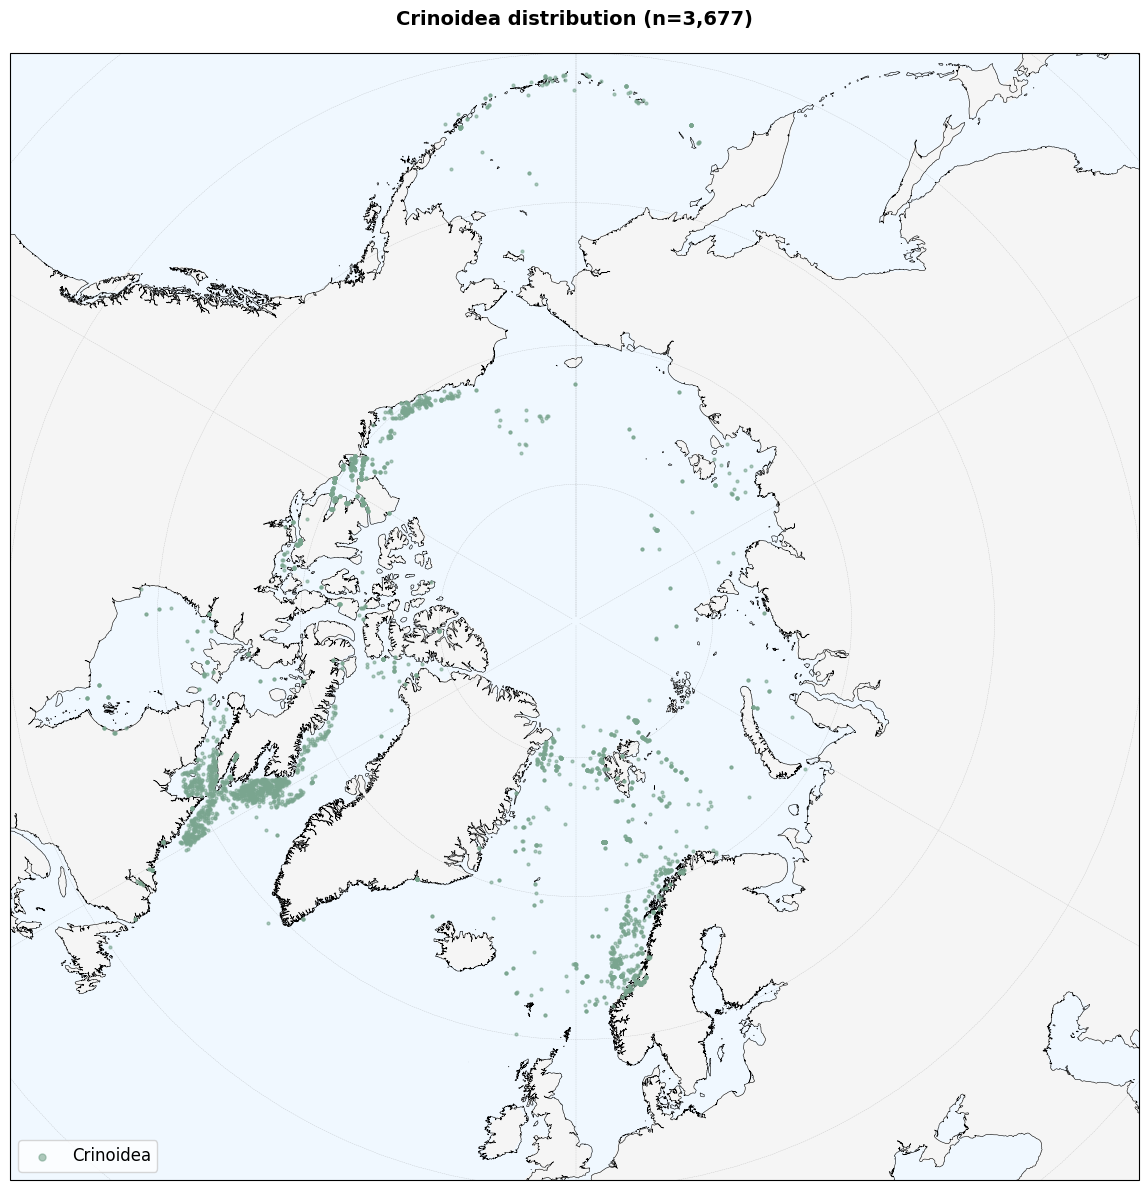

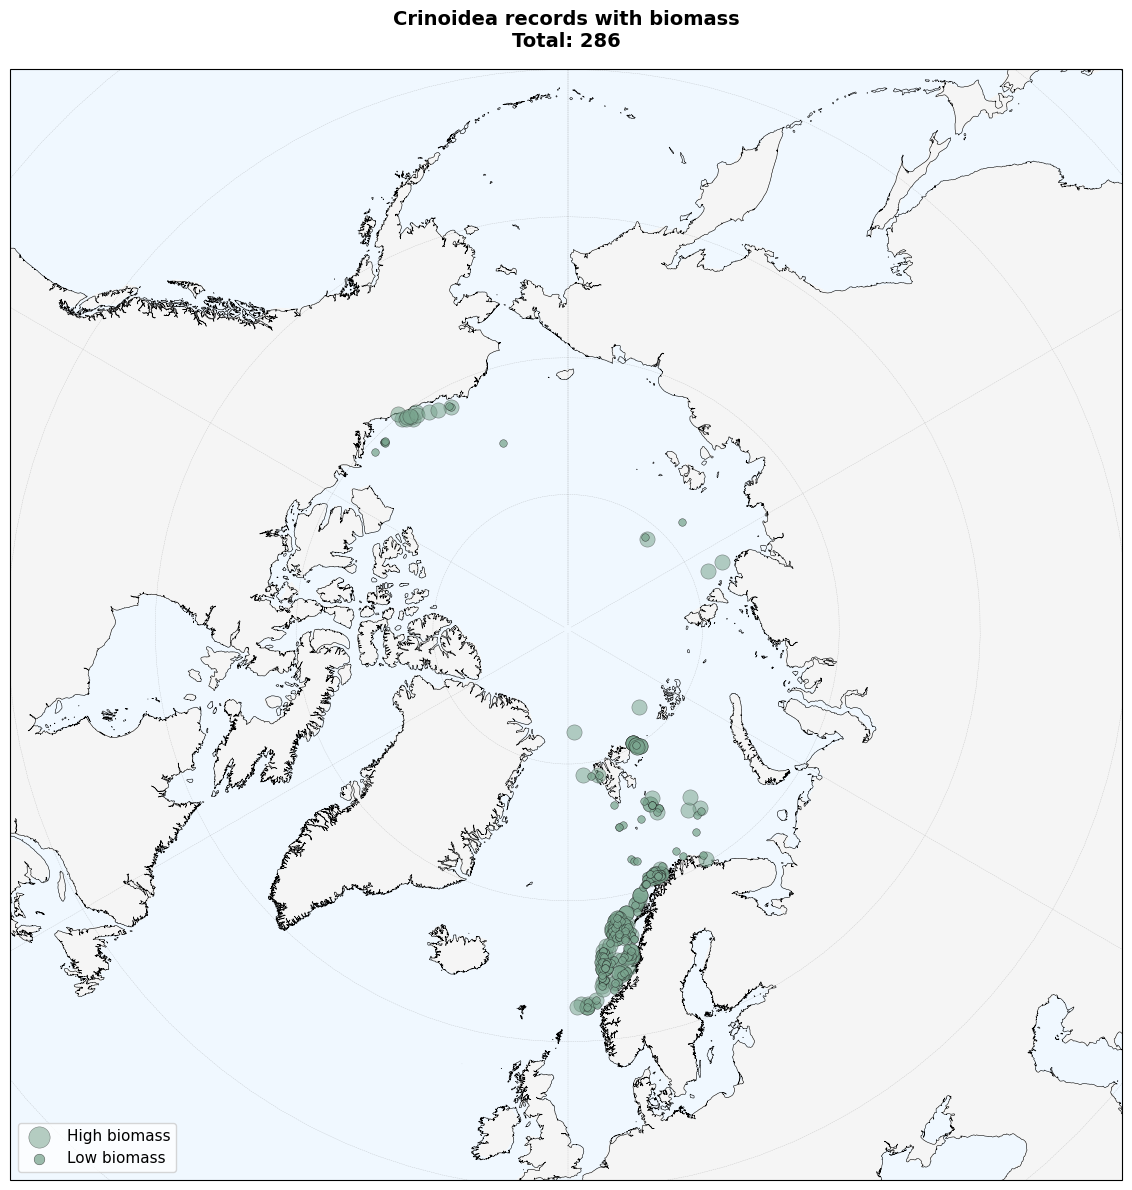

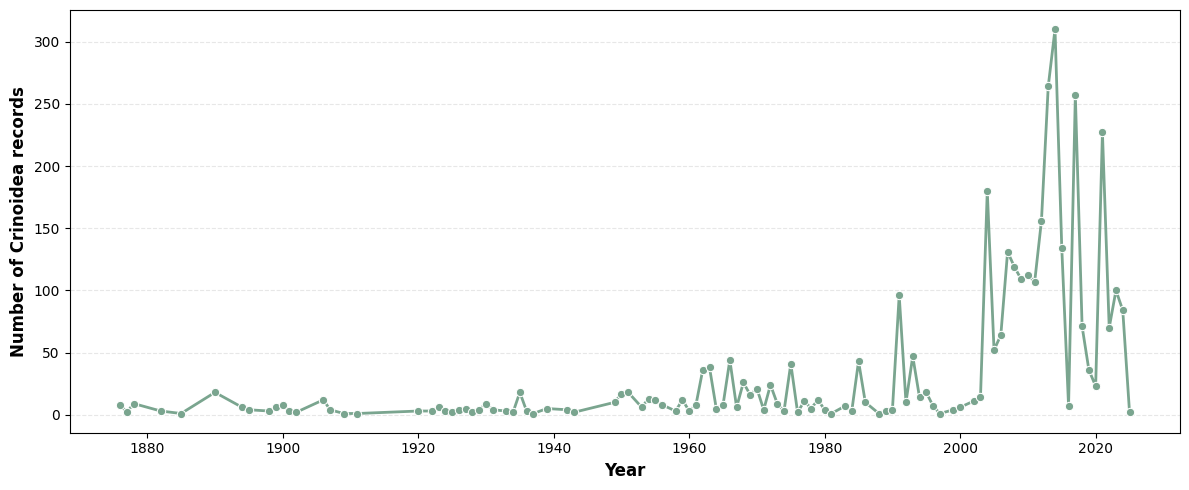

,year,record_count
0,1876,8
1,1877,2
2,1878,9
3,1882,3
4,1885,1
...,...,...
102,2021,227
103,2022,70
104,2023,100
105,2024,84


In [49]:
# Crinoidea maps: distribution + biomass (high/low by median), analogous to Siboglinidae maps

# 1) Build/load Crinoidea subset (class == Crinoidea)
if "src" in globals():
    base_df = src
else:
    base_df = pd.read_parquet("all_merged_geo_LME.parquet")

crinoidea = base_df[
    base_df["class"].astype("string").str.strip().str.lower() == "crinoidea"
] .copy()

crinoidea.to_parquet("crinoidea.parquet", index=False)
print(f"Crinoidea records: {len(crinoidea):,}")

if crinoidea.empty:
    raise ValueError("No records found where class == 'Crinoidea'.")

# Fixed style for both maps
map_color = "#7AA58F"
edge_color_local = "#1F1F1F"
size_high_local = size_high if "size_high" in globals() else 120
size_low_local = size_low if "size_low" in globals() else 30

# 2) Distribution map
df_map = crinoidea.copy()
df_map["decimalLatitudeStart"] = pd.to_numeric(df_map["decimalLatitudeStart"], errors="coerce")
df_map["decimalLongitudeStart"] = pd.to_numeric(df_map["decimalLongitudeStart"], errors="coerce")
df_map = df_map[
    df_map["decimalLatitudeStart"].between(-90, 90)
    & df_map["decimalLongitudeStart"].between(-180, 180)
] .copy()

fig = plt.figure(figsize=(12, 12))
ax = plt.axes(projection=ccrs.NorthPolarStereo())
ax.set_extent([-180, 180, 50, 90], crs=ccrs.PlateCarree())
ax.add_feature(cfeature.LAND, facecolor="whitesmoke", zorder=0)
ax.add_feature(cfeature.OCEAN, facecolor="aliceblue", zorder=0)
ax.coastlines(resolution="10m", linewidth=0.4, color="black", zorder=1)
ax.gridlines(draw_labels=False, linewidth=0.3, color="gray", alpha=0.4, linestyle="--")

ax.scatter(
    df_map["decimalLongitudeStart"].values,
    df_map["decimalLatitudeStart"].values,
    s=4,
    alpha=0.6,
    color=map_color,
    transform=ccrs.PlateCarree(),
    label="Crinoidea",
    zorder=2,
)

ax.legend(loc="lower left", frameon=True, fontsize=12, markerscale=2.5)
plt.title(f"Crinoidea distribution (n={len(df_map):,})", fontsize=14, fontweight="bold", pad=20)
plt.tight_layout()
plt.savefig("crinoidea_distribution_map.png", dpi=300, bbox_inches="tight", facecolor="white")
plt.show()

# 3) Biomass map (high/low from median biomass)
df_bio = crinoidea.copy()
df_bio["decimalLatitudeStart"] = pd.to_numeric(df_bio["decimalLatitudeStart"], errors="coerce")
df_bio["decimalLongitudeStart"] = pd.to_numeric(df_bio["decimalLongitudeStart"], errors="coerce")
df_bio["biomass_num"] = pd.to_numeric(df_bio["biomass"], errors="coerce")

df_bio = df_bio[
    df_bio["decimalLatitudeStart"].between(-90, 90)
    & df_bio["decimalLongitudeStart"].between(-180, 180)
    & df_bio["biomass_num"].notna()
    & (df_bio["biomass_num"] > 0)
] .copy()

if df_bio.empty:
    print("No Crinoidea records with valid positive biomass for biomass map.")
else:
    biomass_median = df_bio["biomass_num"].median()
    df_bio["biomass_category"] = np.where(df_bio["biomass_num"] >= biomass_median, "high", "low")

    fig = plt.figure(figsize=(12, 12))
    ax = plt.axes(projection=ccrs.NorthPolarStereo())
    ax.set_extent([-180, 180, 50, 90], crs=ccrs.PlateCarree())
    ax.add_feature(cfeature.LAND, facecolor="whitesmoke", zorder=0)
    ax.add_feature(cfeature.OCEAN, facecolor="aliceblue", zorder=0)
    ax.coastlines(resolution="10m", linewidth=0.4, color="black", zorder=1)
    ax.gridlines(draw_labels=False, linewidth=0.3, color="gray", alpha=0.4, linestyle="--")

    high = df_bio[df_bio["biomass_category"] == "high"]
    low = df_bio[df_bio["biomass_category"] == "low"]

    ax.scatter(
        high["decimalLongitudeStart"].values,
        high["decimalLatitudeStart"].values,
        s=size_high_local,
        c=map_color,
        alpha=0.55,
        edgecolors=edge_color_local,
        linewidths=0.35,
        transform=ccrs.PlateCarree(),
        zorder=2,
        label="High biomass",
    )
    ax.scatter(
        low["decimalLongitudeStart"].values,
        low["decimalLatitudeStart"].values,
        s=size_low_local,
        c=map_color,
        alpha=0.75,
        edgecolors=edge_color_local,
        linewidths=0.35,
        transform=ccrs.PlateCarree(),
        zorder=3,
        label="Low biomass",
    )

    ax.legend(loc="lower left", frameon=True, fontsize=11, markerscale=1.4)
    plt.title(f"Crinoidea records with biomass\nTotal: {len(df_bio):,}", fontsize=14, fontweight="bold", pad=16)
    plt.tight_layout()
    plt.savefig("crinoidea_biomass_map.png", dpi=300, bbox_inches="tight", facecolor="white")
    plt.show()

# 4) Timeline
crinoidea_timeline = (
    crinoidea.assign(year=pd.to_numeric(crinoidea["year"], errors="coerce"))
    .dropna(subset=["year"])
.assign(year=lambda d: d["year"].astype(int))
    .groupby("year")
    .size()
    .reset_index(name="record_count")
    .sort_values("year")
)

plt.figure(figsize=(12, 5))
sns.lineplot(data=crinoidea_timeline, x="year", y="record_count", marker="o", color=map_color, linewidth=2)
plt.xlabel("Year", fontsize=12, fontweight="bold")
plt.ylabel("Number of Crinoidea records", fontsize=12, fontweight="bold")
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.savefig("crinoidea_records_timeline.png", dpi=300, bbox_inches="tight", facecolor="white")
plt.show()

crinoidea_timeline

# Bryozoa

Bryozoa records: 24,853


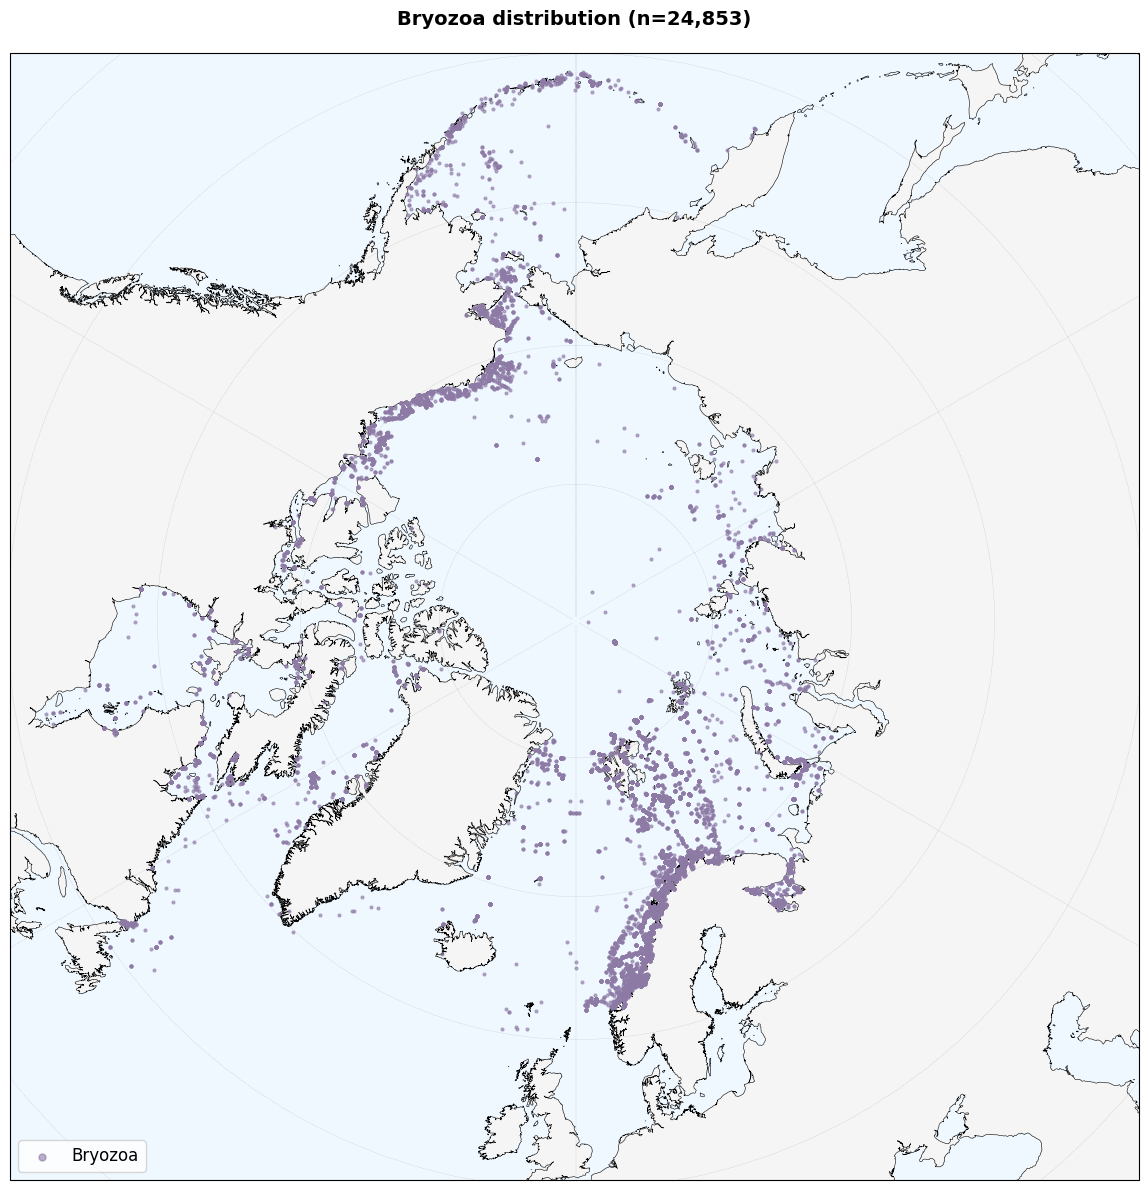

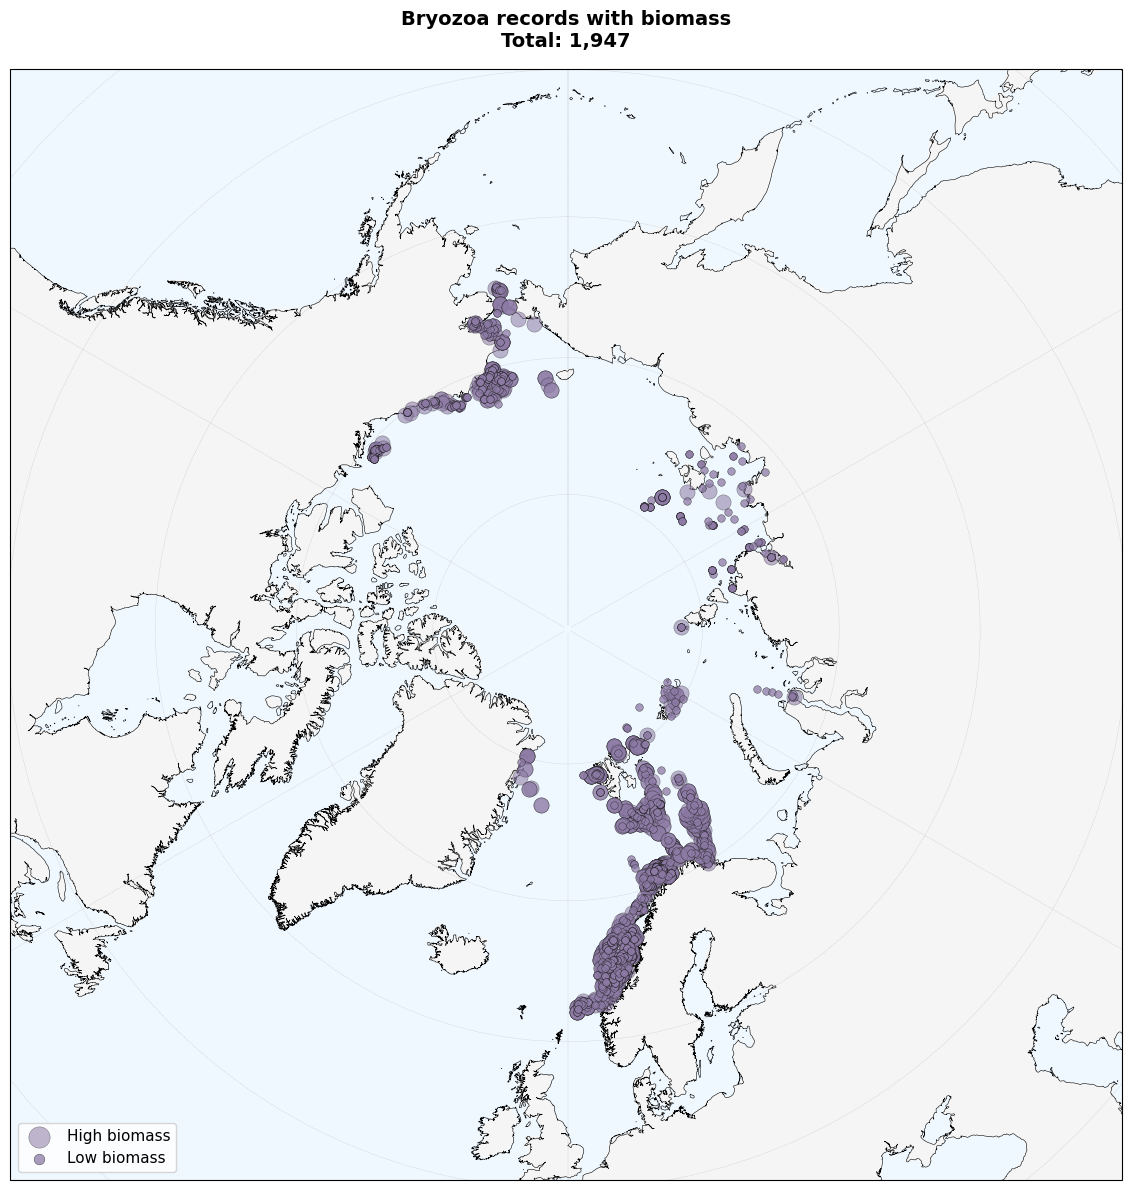

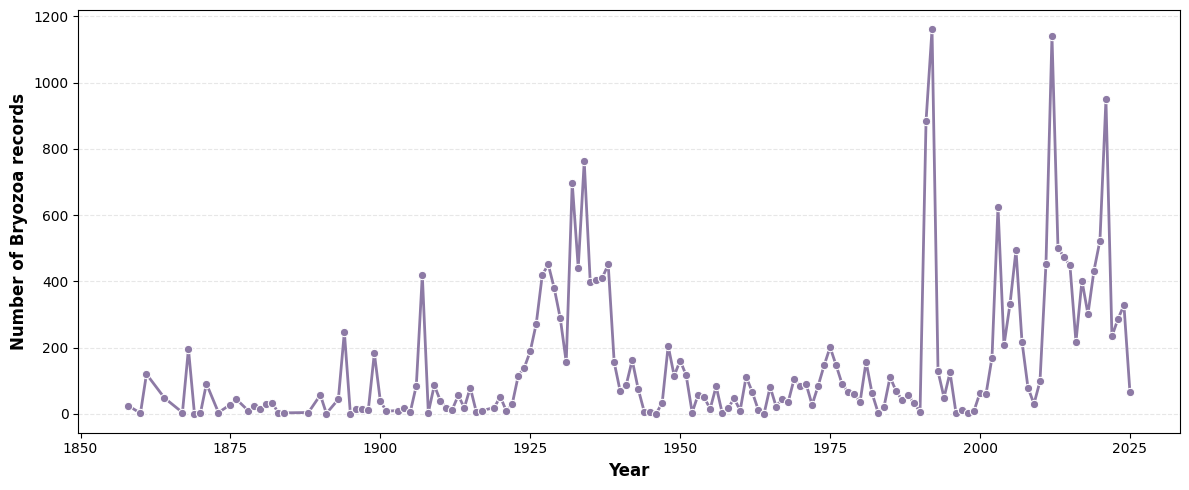

,year,record_count
0,1858,24
1,1860,2
2,1861,120
3,1864,48
4,1867,4
...,...,...
148,2021,949
149,2022,234
150,2023,286
151,2024,328


In [50]:
# Bryozoa maps: distribution + biomass (high/low by median), same pattern as previous taxa

# 1) Build/load Bryozoa subset
if "src" in globals():
    base_df = src
else:
    base_df = pd.read_parquet("all_merged_geo_LME.parquet")

bryozoa = base_df[
    base_df["phylum"].astype("string").str.strip().str.lower() == "bryozoa"
] .copy()

bryozoa.to_parquet("bryozoa.parquet", index=False)
print(f"Bryozoa records: {len(bryozoa):,}")

if bryozoa.empty:
    raise ValueError("No records found where phylum == 'Bryozoa'.")

# Fixed style for both maps
map_color = "#8D7AA5"
edge_color_local = "#1F1F1F"
size_high_local = size_high if "size_high" in globals() else 120
size_low_local = size_low if "size_low" in globals() else 30

# 2) Distribution map
df_map = bryozoa.copy()
df_map["decimalLatitudeStart"] = pd.to_numeric(df_map["decimalLatitudeStart"], errors="coerce")
df_map["decimalLongitudeStart"] = pd.to_numeric(df_map["decimalLongitudeStart"], errors="coerce")
df_map = df_map[
    df_map["decimalLatitudeStart"].between(-90, 90)
    & df_map["decimalLongitudeStart"].between(-180, 180)
] .copy()

fig = plt.figure(figsize=(12, 12))
ax = plt.axes(projection=ccrs.NorthPolarStereo())
ax.set_extent([-180, 180, 50, 90], crs=ccrs.PlateCarree())
ax.add_feature(cfeature.LAND, facecolor="whitesmoke", zorder=0)
ax.add_feature(cfeature.OCEAN, facecolor="aliceblue", zorder=0)
ax.coastlines(resolution="10m", linewidth=0.4, color="black", zorder=1)
ax.gridlines(draw_labels=False, linewidth=0.3, color="gray", alpha=0.4, linestyle="--")

ax.scatter(
    df_map["decimalLongitudeStart"].values,
    df_map["decimalLatitudeStart"].values,
    s=4,
    alpha=0.6,
    color=map_color,
    transform=ccrs.PlateCarree(),
    label="Bryozoa",
    zorder=2,
)

ax.legend(loc="lower left", frameon=True, fontsize=12, markerscale=2.5)
plt.title(f"Bryozoa distribution (n={len(df_map):,})", fontsize=14, fontweight="bold", pad=20)
plt.tight_layout()
plt.savefig("bryozoa_distribution_map.png", dpi=300, bbox_inches="tight", facecolor="white")
plt.show()

# 3) Biomass map (high/low from median biomass)
df_bio = bryozoa.copy()
df_bio["decimalLatitudeStart"] = pd.to_numeric(df_bio["decimalLatitudeStart"], errors="coerce")
df_bio["decimalLongitudeStart"] = pd.to_numeric(df_bio["decimalLongitudeStart"], errors="coerce")
df_bio["biomass_num"] = pd.to_numeric(df_bio["biomass"], errors="coerce")

df_bio = df_bio[
    df_bio["decimalLatitudeStart"].between(-90, 90)
    & df_bio["decimalLongitudeStart"].between(-180, 180)
    & df_bio["biomass_num"].notna()
    & (df_bio["biomass_num"] > 0)
] .copy()

if df_bio.empty:
    print("No Bryozoa records with valid positive biomass for biomass map.")
else:
    biomass_median = df_bio["biomass_num"].median()
    df_bio["biomass_category"] = np.where(df_bio["biomass_num"] >= biomass_median, "high", "low")

    fig = plt.figure(figsize=(12, 12))
    ax = plt.axes(projection=ccrs.NorthPolarStereo())
    ax.set_extent([-180, 180, 50, 90], crs=ccrs.PlateCarree())
    ax.add_feature(cfeature.LAND, facecolor="whitesmoke", zorder=0)
    ax.add_feature(cfeature.OCEAN, facecolor="aliceblue", zorder=0)
    ax.coastlines(resolution="10m", linewidth=0.4, color="black", zorder=1)
    ax.gridlines(draw_labels=False, linewidth=0.3, color="gray", alpha=0.4, linestyle="--")

    high = df_bio[df_bio["biomass_category"] == "high"]
    low = df_bio[df_bio["biomass_category"] == "low"]

    ax.scatter(
        high["decimalLongitudeStart"].values,
        high["decimalLatitudeStart"].values,
        s=size_high_local,
        c=map_color,
        alpha=0.55,
        edgecolors=edge_color_local,
        linewidths=0.35,
        transform=ccrs.PlateCarree(),
        zorder=2,
        label="High biomass",
    )
    ax.scatter(
        low["decimalLongitudeStart"].values,
        low["decimalLatitudeStart"].values,
        s=size_low_local,
        c=map_color,
        alpha=0.75,
        edgecolors=edge_color_local,
        linewidths=0.35,
        transform=ccrs.PlateCarree(),
        zorder=3,
        label="Low biomass",
    )

    ax.legend(loc="lower left", frameon=True, fontsize=11, markerscale=1.4)
    plt.title(f"Bryozoa records with biomass\nTotal: {len(df_bio):,}", fontsize=14, fontweight="bold", pad=16)
    plt.tight_layout()
    plt.savefig("bryozoa_biomass_map.png", dpi=300, bbox_inches="tight", facecolor="white")
    plt.show()

# 4) Timeline
bryozoa_timeline = (
    bryozoa.assign(year=pd.to_numeric(bryozoa["year"], errors="coerce"))
    .dropna(subset=["year"])
.assign(year=lambda d: d["year"].astype(int))
    .groupby("year")
    .size()
    .reset_index(name="record_count")
    .sort_values("year")
)

plt.figure(figsize=(12, 5))
sns.lineplot(data=bryozoa_timeline, x="year", y="record_count", marker="o", color=map_color, linewidth=2)
plt.xlabel("Year", fontsize=12, fontweight="bold")
plt.ylabel("Number of Bryozoa records", fontsize=12, fontweight="bold")
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.savefig("bryozoa_records_timeline.png", dpi=300, bbox_inches="tight", facecolor="white")
plt.show()

bryozoa_timeline

# Dataset for Lis

Taxa to include

Cnidarians after 2000 (exclude records without year): 
- Families
    - Primnoidae 
    - Cerianthidae 
    - Coralliidae 
    - Stylasteridae 
    - Alcyoniidae 
    - Pennatulidae 
    - Funiculinidae 
    - Virgulariidae 

Porifera after 2000 (exclude records without year): 
- Families
    - Geodiidae
- Species: 
    - Chondrocladia (Chondrocladia) gigantea (133185) (unaccepted), Chondrocladia (Chondrocladia) grandis (1023293) (accepted)
    - Cladorhiza bathycrinoides (133190)

Siboglinids after 2000 (exclude records without year): 
- Families
    - Siboglinidae

Crinoidea after 2000 (exclude records without year): 
- Orders
    - Isocrinida 
    - Hyocrinida
- Families
    - Eugeniacrinitidae

Columns to include:
-	sourceDatabase 
-	sourceID
-	datasetKey
-	datasetTitle
-	decimalLatitudeStart
-	decimalLongitudeStart
-	year
-	acceptedScientificName
-	phylum
-	class
-	order
-	family
-	genus
-	aphiaID
-	biomass 
-   gear
-	LME

In [2]:
# Create Cnidaria subset for selected families and years, then save to CSV
input_file = "all_merged_geo_LME.parquet"
output_file = "subset_cnidaria.csv"

target_families = [
    "Primnoidae",
    "Cerianthidae",
    "Coralliidae",
    "Stylasteridae",
    "Alcyoniidae",
    "Pennatulidae",
    "Funiculinidae",
    "Virgulariidae",
]

selected_cols = [
    "sourceDatabase",
    "sourceID",
    "datasetKey",
    "datasetTitle",
    "decimalLatitudeStart",
    "decimalLongitudeStart",
    "year",
    "acceptedScientificName",
    "phylum",
    "class",
    "order",
    "family",
    "genus",
    "aphiaID",
    "biomass",
    "gear",
    "LME",
]

df = pd.read_parquet(input_file)

missing_cols = [c for c in selected_cols if c not in df.columns]
if missing_cols:
    raise KeyError(f"Missing required columns: {missing_cols}")

work = df[selected_cols].copy()
work["year_num"] = pd.to_numeric(work["year"], errors="coerce")
work["family_norm"] = work["family"].astype("string").str.strip()

mask = (
    work["family_norm"].isin(target_families)
    & work["year_num"].between(2000, 2026, inclusive="both")
)

subset_cnidaria = work.loc[mask, selected_cols].copy()
subset_cnidaria["year"] = work.loc[mask, "year_num"].astype(int).values

subset_cnidaria.to_csv(output_file, index=False)

# Summary statistics
family_counts = (
    subset_cnidaria["family"]
    .astype("string")
    .str.strip()
    .value_counts()
    .reindex(target_families, fill_value=0)
    .rename_axis("family")
    .reset_index(name="record_count")
)

total_records = len(subset_cnidaria)

print(f"Saved {total_records:,} records to {output_file}")
print("\nRecords per family:")
print(family_counts)
print(f"\nTotal records: {total_records:,}")

Saved 32,703 records to subset_cnidaria.csv

Records per family:
          family  record_count
0     Primnoidae          7172
1   Cerianthidae          6383
2    Coralliidae          6161
3  Stylasteridae          5435
4    Alcyoniidae          3205
5   Pennatulidae           945
6  Funiculinidae           890
7  Virgulariidae          2512

Total records: 32,703


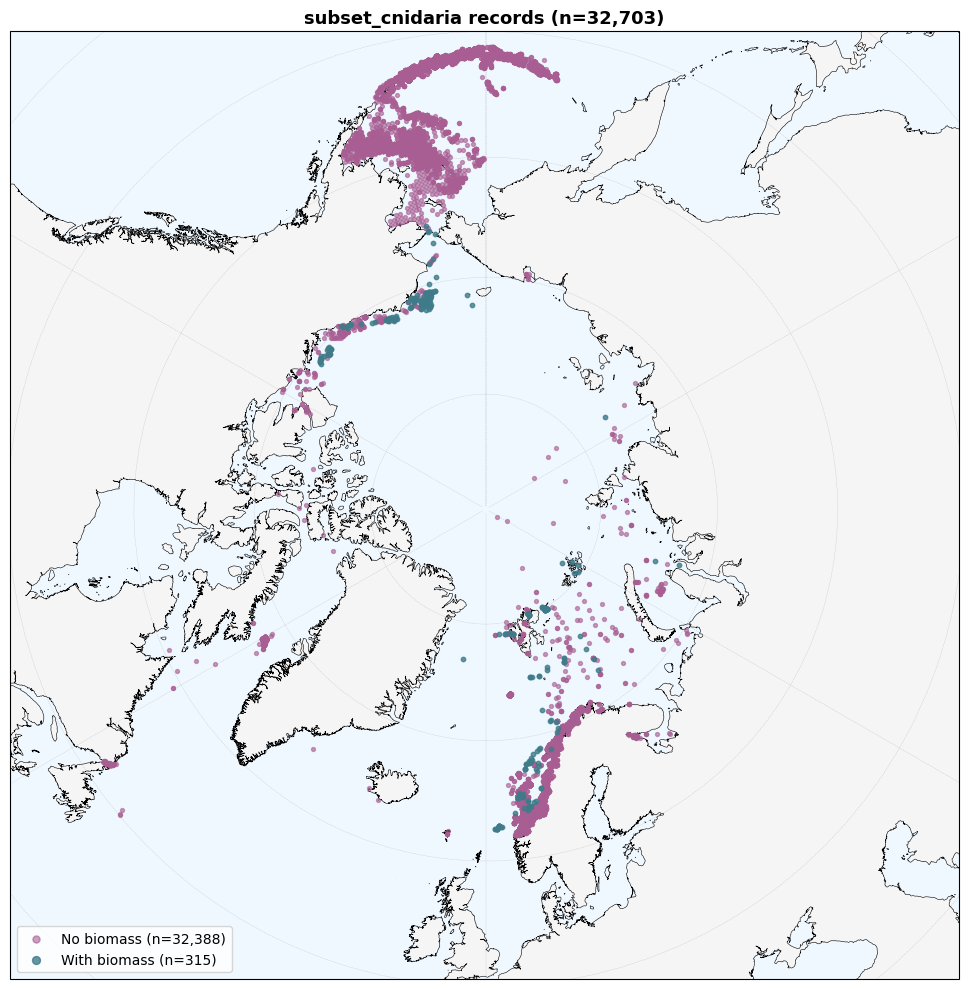

In [13]:
# Load subset_cnidaria from memory or CSV
if "subset_cnidaria" in globals():
    df_map = subset_cnidaria.copy()
else:
    csv_path = output_file if "output_file" in globals() else "subset_cnidaria.csv"
    df_map = pd.read_csv(csv_path)

# Clean coordinates
df_map["decimalLatitudeStart"] = pd.to_numeric(df_map["decimalLatitudeStart"], errors="coerce")
df_map["decimalLongitudeStart"] = pd.to_numeric(df_map["decimalLongitudeStart"], errors="coerce")

df_map = df_map[
    df_map["decimalLatitudeStart"].between(-90, 90)
    & df_map["decimalLongitudeStart"].between(-180, 180)
].copy()

# Biomass presence flag (non-null and non-empty)
df_map["has_biomass"] = (
    df_map["biomass"].notna()
    & df_map["biomass"].astype("string").str.strip().ne("")
)

# Plot (North Polar Stereographic)
fig = plt.figure(figsize=(10, 10))
ax = plt.axes(projection=ccrs.NorthPolarStereo())
ax.set_extent([-180, 180, 50, 90], crs=ccrs.PlateCarree())
ax.add_feature(cfeature.LAND, facecolor="whitesmoke", zorder=0)
ax.add_feature(cfeature.OCEAN, facecolor="aliceblue", zorder=0)
ax.coastlines(resolution="10m", linewidth=0.4, color="black", zorder=1)
ax.gridlines(draw_labels=False, linewidth=0.3, color="gray", alpha=0.4, linestyle="--")

# Records without biomass
no_bio = df_map[~df_map["has_biomass"]]
ax.scatter(
    no_bio["decimalLongitudeStart"].values,
    no_bio["decimalLatitudeStart"].values,
    s=8,
    color="#A85E92",
    alpha=0.6,
    transform=ccrs.PlateCarree(),
    label=f"No biomass (n={len(no_bio):,})",
    zorder=2,
)

# Records with biomass
yes_bio = df_map[df_map["has_biomass"]]
ax.scatter(
    yes_bio["decimalLongitudeStart"].values,
    yes_bio["decimalLatitudeStart"].values,
    s=10,
    color="#3F7B89",
    alpha=0.8,
    transform=ccrs.PlateCarree(),
    label=f"With biomass (n={len(yes_bio):,})",
    zorder=3,
)

ax.legend(loc="lower left", frameon=True, fontsize=10, markerscale=1.8)
plt.title(f"subset_cnidaria records (n={len(df_map):,})", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

In [5]:
# Create Porifera subset for Geodiidae family OR selected aphiaIDs, restricted to years 2000–2026
input_file = "all_merged_geo_LME.parquet"
output_file = "subset_porifera.csv"

selected_cols = [
    "sourceDatabase",
    "sourceID",
    "datasetKey",
    "datasetTitle",
    "decimalLatitudeStart",
    "decimalLongitudeStart",
    "year",
    "acceptedScientificName",
    "phylum",
    "class",
    "order",
    "family",
    "genus",
    "aphiaID",
    "biomass",
    "gear",
    "LME",
]

target_aphia_ids = {133185, 1023293, 133190}

df = pd.read_parquet(input_file)

missing_cols = [c for c in selected_cols if c not in df.columns]
if missing_cols:
    raise KeyError(f"Missing required columns: {missing_cols}")

work = df[selected_cols].copy()

# Normalize filter fields
work["year_num"] = pd.to_numeric(work["year"], errors="coerce")
work["family_norm"] = work["family"].astype("string").str.strip().str.lower()
work["aphiaID_num"] = pd.to_numeric(work["aphiaID"], errors="coerce")

mask = (
    work["year_num"].between(2000, 2026, inclusive="both")
    & (
        (work["family_norm"] == "geodiidae")
        | (work["aphiaID_num"].isin(target_aphia_ids))
    )
)

subset_porifera = work.loc[mask, selected_cols].copy()
subset_porifera["year"] = work.loc[mask, "year_num"].astype(int).values

subset_porifera.to_csv(output_file, index=False)

# Summary: records per family + total
family_counts = (
    subset_porifera["family"]
    .astype("string")
    .str.strip()
    .replace("", pd.NA)
    .fillna("Unknown")
    .value_counts()
    .rename_axis("family")
    .reset_index(name="record_count")
)

total_records = len(subset_porifera)

# Coverage (% non-missing) per column in subset
def non_missing_mask(s):
    m = s.notna()
    if pd.api.types.is_object_dtype(s) or pd.api.types.is_string_dtype(s):
        m &= s.astype("string").str.strip().ne("")
    return m

coverage_df = pd.DataFrame({
    "column": subset_porifera.columns,
    "non_missing": [non_missing_mask(subset_porifera[c]).sum() for c in subset_porifera.columns],
})
coverage_df["total_rows"] = total_records
coverage_df["coverage_percent"] = (coverage_df["non_missing"] / total_records * 100).round(2)
coverage_df = coverage_df.sort_values("coverage_percent", ascending=False).reset_index(drop=True)

print(f"Saved {total_records:,} records to {output_file}")
print("\nRecords per family:")
print(family_counts)
print(f"\nTotal records: {total_records:,}")
print("\nColumn coverage (% non-missing):")
print(coverage_df)

Saved 1,967 records to subset_porifera.csv

Records per family:
          family  record_count
0      Geodiidae          1955
1  Cladorhizidae            12

Total records: 1,967

Column coverage (% non-missing):
                    column  non_missing  total_rows  coverage_percent
0           sourceDatabase         1967        1967            100.00
1                 sourceID         1967        1967            100.00
2               datasetKey         1967        1967            100.00
3     decimalLatitudeStart         1967        1967            100.00
4    decimalLongitudeStart         1967        1967            100.00
5   acceptedScientificName         1967        1967            100.00
6                     year         1967        1967            100.00
7                   phylum         1967        1967            100.00
8                    class         1967        1967            100.00
9                      LME         1967        1967            100.00
10               

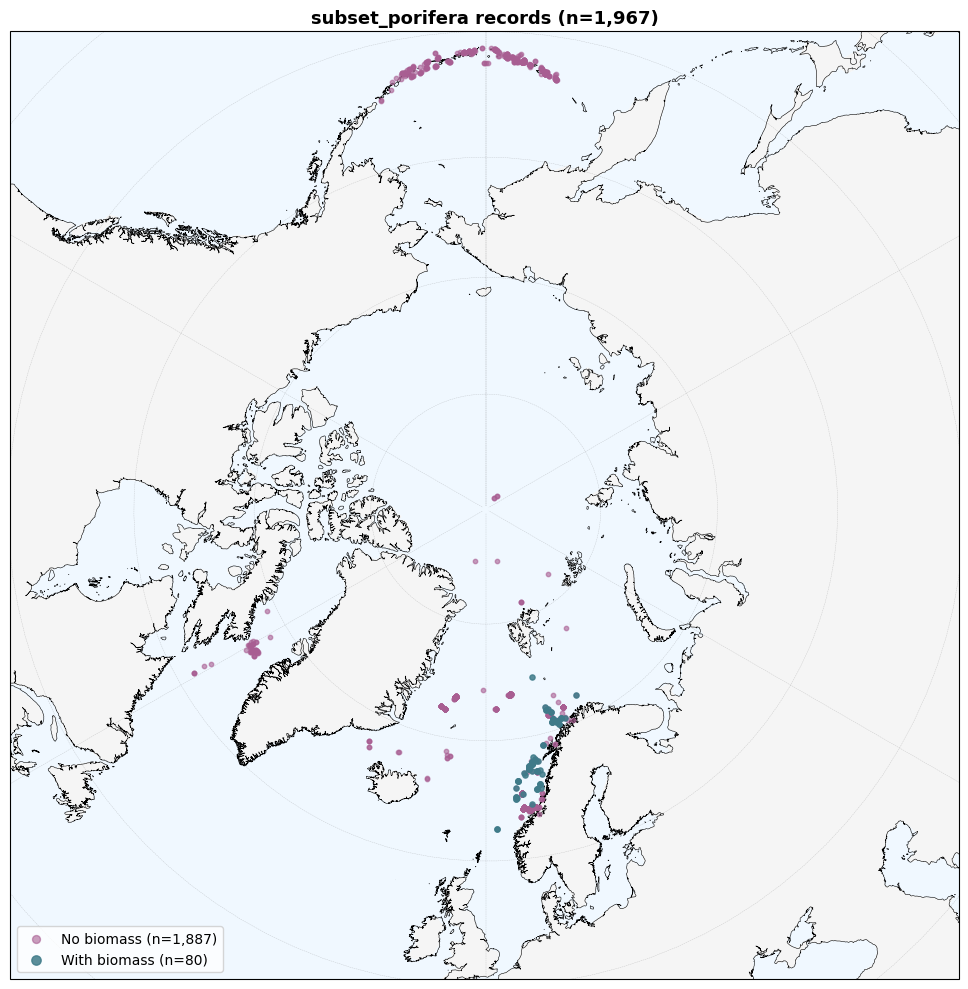

In [10]:
# Map subset_porifera.csv with biomass/non-biomass records in different colors
porifera_csv = "subset_porifera.csv"
df_map = pd.read_csv(porifera_csv)

# Clean coordinates
df_map["decimalLatitudeStart"] = pd.to_numeric(df_map["decimalLatitudeStart"], errors="coerce")
df_map["decimalLongitudeStart"] = pd.to_numeric(df_map["decimalLongitudeStart"], errors="coerce")

df_map = df_map[
    df_map["decimalLatitudeStart"].between(-90, 90)
    & df_map["decimalLongitudeStart"].between(-180, 180)
].copy()

# Biomass presence flag
df_map["has_biomass"] = (
    df_map["biomass"].notna()
    & df_map["biomass"].astype("string").str.strip().ne("")
)

no_bio = df_map[~df_map["has_biomass"]]
yes_bio = df_map[df_map["has_biomass"]]

# Plot (North Polar Stereographic)
fig = plt.figure(figsize=(10, 10))
ax = plt.axes(projection=ccrs.NorthPolarStereo())
ax.set_extent([-180, 180, 50, 90], crs=ccrs.PlateCarree())
ax.add_feature(cfeature.LAND, facecolor="whitesmoke", zorder=0)
ax.add_feature(cfeature.OCEAN, facecolor="aliceblue", zorder=0)
ax.coastlines(resolution="10m", linewidth=0.4, color="black", zorder=1)
ax.gridlines(draw_labels=False, linewidth=0.3, color="gray", alpha=0.4, linestyle="--")

ax.scatter(
    no_bio["decimalLongitudeStart"].values,
    no_bio["decimalLatitudeStart"].values,
    s=10,
    color="#A85E92",
    alpha=0.6,
    transform=ccrs.PlateCarree(),
    label=f"No biomass (n={len(no_bio):,})",
    zorder=2,
)

ax.scatter(
    yes_bio["decimalLongitudeStart"].values,
    yes_bio["decimalLatitudeStart"].values,
    s=14,
    color="#3F7B89",
    alpha=0.85,
    transform=ccrs.PlateCarree(),
    label=f"With biomass (n={len(yes_bio):,})",
    zorder=3,
)

ax.legend(loc="lower left", frameon=True, fontsize=10, markerscale=1.8)
plt.title(f"subset_porifera records (n={len(df_map):,})", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

In [14]:
# Create Siboglinidae subset for years 2000–2026 and save to CSV
sib_input_file = "all_merged_geo_LME.parquet"
sib_output_file = "subset_siboglinids.csv"

sib_selected_cols = [
    "sourceDatabase",
    "sourceID",
    "datasetKey",
    "datasetTitle",
    "decimalLatitudeStart",
    "decimalLongitudeStart",
    "year",
    "acceptedScientificName",
    "phylum",
    "class",
    "order",
    "family",
    "genus",
    "aphiaID",
    "biomass",
    "gear",
    "LME",
]

sib_df = pd.read_parquet(sib_input_file)

missing_cols = [c for c in sib_selected_cols if c not in sib_df.columns]
if missing_cols:
    raise KeyError(f"Missing required columns: {missing_cols}")

sib_work = sib_df[sib_selected_cols].copy()
sib_work["year_num"] = pd.to_numeric(sib_work["year"], errors="coerce")
sib_work["family_norm"] = sib_work["family"].astype("string").str.strip().str.lower()

sib_mask = (
    sib_work["family_norm"].eq("siboglinidae")
    & sib_work["year_num"].between(2000, 2026, inclusive="both")
)

subset_siboglinids = sib_work.loc[sib_mask, sib_selected_cols].copy()
subset_siboglinids["year"] = sib_work.loc[sib_mask, "year_num"].astype(int).values

subset_siboglinids.to_csv(sib_output_file, index=False)

# Summary: records per family and total
sib_family_counts = (
    subset_siboglinids["family"]
    .astype("string")
    .str.strip()
    .replace("", pd.NA)
    .fillna("Unknown")
    .value_counts()
    .rename_axis("family")
    .reset_index(name="record_count")
)

sib_total_records = len(subset_siboglinids)

# Coverage (% non-missing) per column
def non_missing_mask(s):
    m = s.notna()
    if pd.api.types.is_object_dtype(s) or pd.api.types.is_string_dtype(s):
        m &= s.astype("string").str.strip().ne("")
    return m

sib_coverage_df = pd.DataFrame({
    "column": subset_siboglinids.columns,
    "non_missing": [non_missing_mask(subset_siboglinids[c]).sum() for c in subset_siboglinids.columns],
})
sib_coverage_df["total_rows"] = sib_total_records
sib_coverage_df["coverage_percent"] = (sib_coverage_df["non_missing"] / sib_total_records * 100).round(2)
sib_coverage_df = sib_coverage_df.sort_values("coverage_percent", ascending=False).reset_index(drop=True)

print(f"Saved {sib_total_records:,} records to {sib_output_file}")
print("\nRecords per family:")
print(sib_family_counts)
print(f"\nTotal records: {sib_total_records:,}")
print("\nColumn coverage (% non-missing):")
print(sib_coverage_df)

Saved 5,831 records to subset_siboglinids.csv

Records per family:
         family  record_count
0  Siboglinidae          5831

Total records: 5,831

Column coverage (% non-missing):
                    column  non_missing  total_rows  coverage_percent
0           sourceDatabase         5831        5831            100.00
1                 sourceID         5831        5831            100.00
2               datasetKey         5831        5831            100.00
3     decimalLatitudeStart         5831        5831            100.00
4    decimalLongitudeStart         5831        5831            100.00
5   acceptedScientificName         5831        5831            100.00
6                     year         5831        5831            100.00
7                   phylum         5831        5831            100.00
8                    class         5831        5831            100.00
9                      LME         5831        5831            100.00
10                   order         5831        

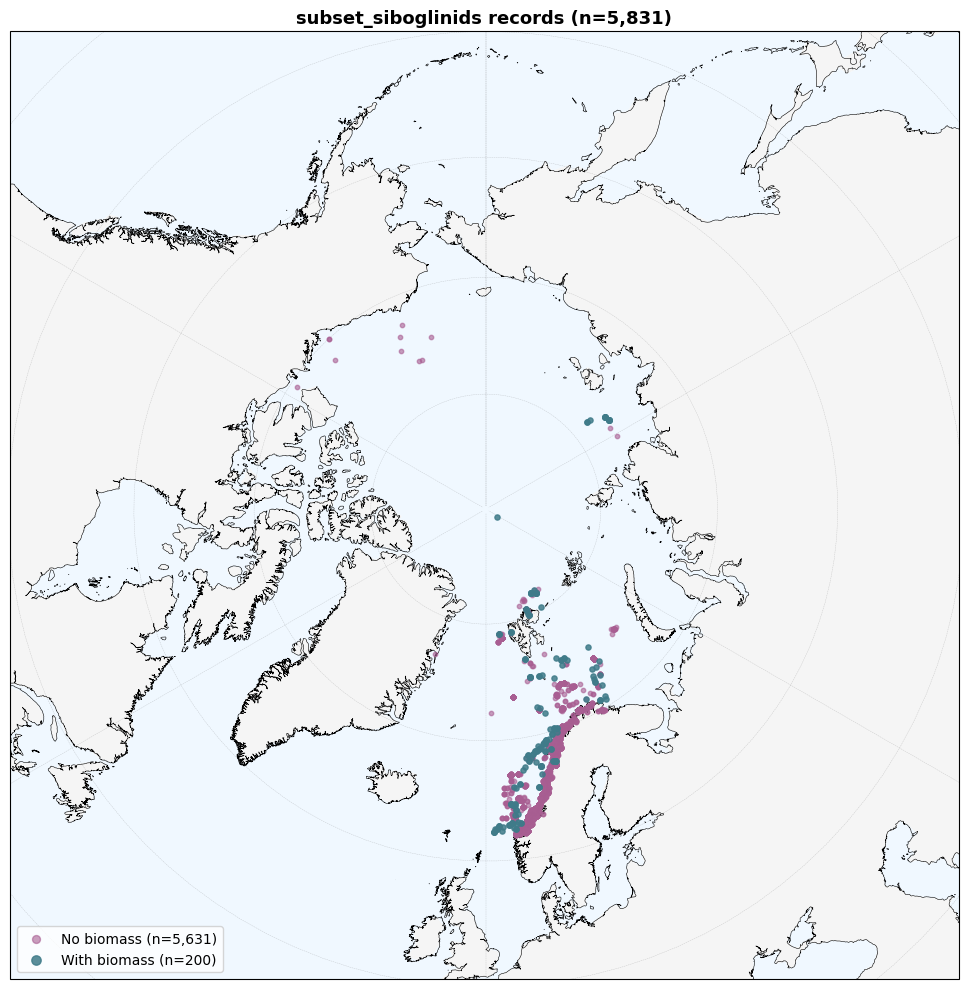

In [22]:
# Map siboglinids_cnidaria.csv with biomass/non-biomass records in different colors
csv_file = "subset_siboglinids.csv"
df_map = pd.read_csv(csv_file)

required_cols = ["decimalLatitudeStart", "decimalLongitudeStart", "biomass"]
missing_cols = [c for c in required_cols if c not in df_map.columns]
if missing_cols:
    raise KeyError(f"Missing required columns in {csv_file}: {missing_cols}")

# Clean coordinates
df_map["decimalLatitudeStart"] = pd.to_numeric(df_map["decimalLatitudeStart"], errors="coerce")
df_map["decimalLongitudeStart"] = pd.to_numeric(df_map["decimalLongitudeStart"], errors="coerce")

df_map = df_map[
    df_map["decimalLatitudeStart"].between(-90, 90)
    & df_map["decimalLongitudeStart"].between(-180, 180)
].copy()

# Biomass presence flag (non-null and non-empty)
df_map["has_biomass"] = (
    df_map["biomass"].notna()
    & df_map["biomass"].astype("string").str.strip().ne("")
)

no_bio = df_map[~df_map["has_biomass"]]
yes_bio = df_map[df_map["has_biomass"]]

# Plot map (North Polar Stereographic)
fig = plt.figure(figsize=(10, 10))
ax = plt.axes(projection=ccrs.NorthPolarStereo())
ax.set_extent([-180, 180, 50, 90], crs=ccrs.PlateCarree())
ax.add_feature(cfeature.LAND, facecolor="whitesmoke", zorder=0)
ax.add_feature(cfeature.OCEAN, facecolor="aliceblue", zorder=0)
ax.coastlines(resolution="10m", linewidth=0.4, color="black", zorder=1)
ax.gridlines(draw_labels=False, linewidth=0.3, color="gray", alpha=0.4, linestyle="--")

ax.scatter(
    no_bio["decimalLongitudeStart"].values,
    no_bio["decimalLatitudeStart"].values,
    s=10,
    color="#A85E92",
    alpha=0.6,
    transform=ccrs.PlateCarree(),
    label=f"No biomass (n={len(no_bio):,})",
    zorder=2,
)

ax.scatter(
    yes_bio["decimalLongitudeStart"].values,
    yes_bio["decimalLatitudeStart"].values,
    s=14,
    color="#3F7B89",
    alpha=0.85,
    transform=ccrs.PlateCarree(),
    label=f"With biomass (n={len(yes_bio):,})",
    zorder=3,
)

ax.legend(loc="lower left", frameon=True, fontsize=10, markerscale=1.8)
plt.title(f"subset_siboglinids records (n={len(df_map):,})", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

In [17]:
# Create Crinoidea subset (orders: Isocrinida/Hyocrinida AND family: Eugeniacrinitidae), years 2000–2026
crinoid_input_file = input_file if "input_file" in globals() else "all_merged_geo_LME.parquet"
crinoid_output_file = "subset_crinoids.csv"

crinoid_selected_cols = [
    "sourceDatabase",
    "sourceID",
    "datasetKey",
    "datasetTitle",
    "decimalLatitudeStart",
    "decimalLongitudeStart",
    "year",
    "acceptedScientificName",
    "phylum",
    "class",
    "order",
    "family",
    "genus",
    "aphiaID",
    "biomass",
    "gear",
    "LME",
]

target_orders = {"isocrinida", "hyocrinida"}
target_family = "eugeniacrinitidae"

cr_df = pd.read_parquet(crinoid_input_file)

missing_cols = [c for c in crinoid_selected_cols if c not in cr_df.columns]
if missing_cols:
    raise KeyError(f"Missing required columns: {missing_cols}")

cr_work = cr_df[crinoid_selected_cols].copy()
cr_work["year_num"] = pd.to_numeric(cr_work["year"], errors="coerce")
cr_work["order_norm"] = cr_work["order"].astype("string").str.strip().str.lower()
cr_work["family_norm"] = cr_work["family"].astype("string").str.strip().str.lower()

cr_mask = (
    cr_work["year_num"].between(2000, 2026, inclusive="both")
    & cr_work["order_norm"].isin(target_orders)
    & cr_work["family_norm"].eq(target_family)
)

subset_crinoids = cr_work.loc[cr_mask, crinoid_selected_cols].copy()
subset_crinoids["year"] = cr_work.loc[cr_mask, "year_num"].astype(int).values

subset_crinoids.to_csv(crinoid_output_file, index=False)

# Summary stats
cr_family_counts = (
    subset_crinoids["family"]
    .astype("string")
    .str.strip()
    .replace("", pd.NA)
    .fillna("Unknown")
    .value_counts()
    .rename_axis("family")
    .reset_index(name="record_count")
)

cr_total_records = len(subset_crinoids)

def non_missing_mask(s):
    m = s.notna()
    if pd.api.types.is_object_dtype(s) or pd.api.types.is_string_dtype(s):
        m &= s.astype("string").str.strip().ne("")
    return m

cr_coverage_df = pd.DataFrame({
    "column": subset_crinoids.columns,
    "non_missing": [non_missing_mask(subset_crinoids[c]).sum() for c in subset_crinoids.columns],
})
cr_coverage_df["total_rows"] = cr_total_records
cr_coverage_df["coverage_percent"] = (
    (cr_coverage_df["non_missing"] / cr_total_records * 100).round(2)
    if cr_total_records > 0
    else 0.0
)
cr_coverage_df = cr_coverage_df.sort_values("coverage_percent", ascending=False).reset_index(drop=True)

print(f"Saved {cr_total_records:,} records to {crinoid_output_file}")
print("\nRecords per family:")
print(cr_family_counts)
print(f"\nTotal records: {cr_total_records:,}")
print("\nColumn coverage (% non-missing):")
print(cr_coverage_df)

Saved 0 records to subset_crinoids.csv

Records per family:
Empty DataFrame
Columns: [family, record_count]
Index: []

Total records: 0

Column coverage (% non-missing):
                    column  non_missing  total_rows  coverage_percent
0           sourceDatabase            0           0               0.0
1                 sourceID            0           0               0.0
2               datasetKey            0           0               0.0
3             datasetTitle            0           0               0.0
4     decimalLatitudeStart            0           0               0.0
5    decimalLongitudeStart            0           0               0.0
6                     year            0           0               0.0
7   acceptedScientificName            0           0               0.0
8                   phylum            0           0               0.0
9                    class            0           0               0.0
10                   order            0           0         

In [18]:
# Overview of orders and families within class Crinoidea
crino_file = input_file if "input_file" in globals() else "all_merged_geo_LME.parquet"
df_crino = pd.read_parquet(crino_file)

# Filter class = Crinoidea (case/whitespace robust)
crino = df_crino[
    df_crino["class"].astype("string").str.strip().str.lower().eq("crinoidea")
].copy()

print(f"Total Crinoidea records: {len(crino):,}")

# Clean order/family labels
crino["order_clean"] = (
    crino["order"].astype("string").str.strip().replace("", pd.NA).fillna("Unknown")
)
crino["family_clean"] = (
    crino["family"].astype("string").str.strip().replace("", pd.NA).fillna("Unknown")
)

# 1) Orders overview
crino_order_counts = (
    crino["order_clean"]
    .value_counts(dropna=False)
    .rename_axis("order")
    .reset_index(name="record_count")
)

# 2) Families overview
crino_family_counts = (
    crino["family_clean"]
    .value_counts(dropna=False)
    .rename_axis("family")
    .reset_index(name="record_count")
)

# 3) Order x Family overview
crino_order_family_counts = (
    crino.groupby(["order_clean", "family_clean"], dropna=False)
    .size()
    .reset_index(name="record_count")
    .sort_values(["order_clean", "record_count"], ascending=[True, False])
)

print("\nOrders in Crinoidea:")
print(crino_order_counts)

print("\nFamilies in Crinoidea:")
print(crino_family_counts)

print("\nOrder × Family combinations in Crinoidea:")
print(crino_order_family_counts)

# Optional: save outputs
crino_order_counts.to_csv("crinoidea_orders_overview.csv", index=False)
crino_family_counts.to_csv("crinoidea_families_overview.csv", index=False)
crino_order_family_counts.to_csv("crinoidea_order_family_overview.csv", index=False)

Total Crinoidea records: 3,677

Orders in Crinoidea:
            order  record_count
0      Comatulida          2971
1         Unknown           699
2  Millericrinida             5
3      Hyocrinida             2

Families in Crinoidea:
               family  record_count
0         Antedonidae          2501
1             Unknown           687
2       Bathycrinidae           386
3       Rhizocrinidae            85
4   Bourgueticrinidae             4
5    Thalassometridae             4
6         Comatulidae             3
7         Hyocrinidae             2
8        Zenometridae             2
9     Charitometridae             2
10     Tropiometridae             1

Order × Family combinations in Crinoidea:
       order_clean       family_clean  record_count
0       Comatulida        Antedonidae          2442
1       Comatulida      Bathycrinidae           386
5       Comatulida      Rhizocrinidae            85
8       Comatulida            Unknown            42
2       Comatulida  Bourguet

In [19]:
# Years with records where order == "Hyocrinida"
source_df = sib_df if "sib_df" in globals() else pd.read_parquet(input_file)

hyocrinida_rows = source_df[
	source_df["order"].astype("string").str.strip().str.lower().eq("hyocrinida")
].copy()

hyocrinida_rows["year_num"] = pd.to_numeric(hyocrinida_rows["year"], errors="coerce")
years = sorted(hyocrinida_rows["year_num"].dropna().astype(int).unique().tolist())

print("Years with Hyocrinida records:", years)
print("Total Hyocrinida records:", len(hyocrinida_rows))
print(
	hyocrinida_rows["year_num"]
	.dropna()
	.astype(int)
	.value_counts()
	.sort_index()
	.rename("record_count")
)

Years with Hyocrinida records: [1990]
Total Hyocrinida records: 2
year_num
1990    2
Name: record_count, dtype: int64


In [20]:
# Merge selected subset files into one CSV, then report column coverage and sourceDatabase proportions
files_to_merge = ["subset_siboglinids.csv", "subset_porifera.csv", "subset_cnidaria.csv"]
merged_output_file = "subset_merged_vme.csv"

dfs = []
for f in files_to_merge:
	if not os.path.exists(f):
		raise FileNotFoundError(f"File not found: {f}")
	dfs.append(pd.read_csv(f))

merged_df = pd.concat(dfs, ignore_index=True, sort=False)
merged_df.to_csv(merged_output_file, index=False)

def non_missing_mask(s):
	m = s.notna()
	if pd.api.types.is_object_dtype(s) or pd.api.types.is_string_dtype(s):
		m &= s.astype("string").str.strip().ne("")
	return m

# Column coverage (% non-missing)
total_rows = len(merged_df)
coverage_df = pd.DataFrame({
	"column": merged_df.columns,
	"non_missing": [non_missing_mask(merged_df[c]).sum() for c in merged_df.columns],
})
coverage_df["total_rows"] = total_rows
coverage_df["coverage_percent"] = (coverage_df["non_missing"] / total_rows * 100).round(2)
coverage_df = coverage_df.sort_values("coverage_percent", ascending=False).reset_index(drop=True)

# Proportion of records by sourceDatabase
if "sourceDatabase" not in merged_df.columns:
	raise KeyError("Column 'sourceDatabase' not found in merged data.")

source_stats = (
	merged_df["sourceDatabase"]
	.astype("string")
	.str.strip()
	.replace("", pd.NA)
	.fillna("Unknown")
	.value_counts(dropna=False)
	.rename_axis("sourceDatabase")
	.reset_index(name="record_count")
)
source_stats["proportion_percent"] = (source_stats["record_count"] / total_rows * 100).round(2)

# Optional outputs
coverage_df.to_csv("subset_merged_column_coverage.csv", index=False)
source_stats.to_csv("subset_merged_source_proportion.csv", index=False)

print(f"Saved merged file: {merged_output_file} ({total_rows:,} rows)")
print("\nColumn coverage (% non-missing):")
print(coverage_df)
print("\nsourceDatabase distribution:")
print(source_stats)

Saved merged file: subset_merged_vme.csv (40,501 rows)

Column coverage (% non-missing):
                    column  non_missing  total_rows  coverage_percent
0           sourceDatabase        40501       40501            100.00
1                 sourceID        40501       40501            100.00
2               datasetKey        40501       40501            100.00
3     decimalLatitudeStart        40501       40501            100.00
4    decimalLongitudeStart        40501       40501            100.00
5   acceptedScientificName        40501       40501            100.00
6                     year        40501       40501            100.00
7                   phylum        40501       40501            100.00
8                    class        40501       40501            100.00
9                      LME        40501       40501            100.00
10                  family        40501       40501            100.00
11                 aphiaID        40501       40501            100.00
1

In [21]:
# Build datasetKey summary with sourceDatabase and number of records
df_merged = pd.read_csv(merged_output_file)

summary_datasetkey = (
    df_merged.assign(
        datasetKey=df_merged["datasetKey"].astype("string").str.strip(),
        sourceDatabase=df_merged["sourceDatabase"].astype("string").str.strip(),
    )
    .replace({"datasetKey": {"": pd.NA}, "sourceDatabase": {"": pd.NA}})
    .dropna(subset=["datasetKey", "sourceDatabase"])
    .groupby(["datasetKey", "sourceDatabase"], dropna=False)
    .size()
    .reset_index(name="record_count")
    .sort_values("record_count", ascending=False)
)

out_file = "datasetKey_record_counts.csv"
summary_datasetkey.to_csv(out_file, index=False)

print(f"Saved {len(summary_datasetkey):,} rows to {out_file}")
summary_datasetkey.head(20)

Saved 102 rows to datasetKey_record_counts.csv


,datasetKey,sourceDatabase,record_count
93,df8e3fb8-3da7-4104-a866-748f6da20a3c,GBIF,16020
16,46293000-ddd1-4c32-a1e7-b5e793223ecd,GBIF,5212
18,492d63a8-4978-4bc7-acd8-7d0e3ac0e744,GBIF,5205
73,b6b4502f-ffc8-4048-a91b-af502288faa8,GBIF,3756
80,bed78790-cbec-44af-82af-fe78e9692287,GBIF,2277
36,8ff2fc9c-bd30-45ec-8b90-179b523cf6b0,GBIF,1121
5,18b7c5c7-9814-4dc4-a8aa-833e91969358,GBIF,1033
82,c4db5fd0-e2b6-4737-995e-d895bc596d86,GBIF,786
29,821cc27a-e3bb-4bc5-ac34-89ada245069d,GBIF,679
88,d7688dd5-9cd0-4de7-8873-e76b709ee082,GBIF,572
